# B3 · Attention et Transformers : un mini-GPT from scratch — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookIA/blob/main/chapitres/b3_transformers/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wb.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | B3.Q1 à B3.Q12, B3.R1 à B3.R3, B3.1 à B3.5 | vérifier tes réponses courtes | 🧠 🔁 ✏️ | ★ à ★★ | |
| A | B3.12 | causal_mask, padding_mask et scaled_dot_product_attention | 🔨 | ★★ | 30 |
|  | B3.13 | Prédire la carte d'attention quand une clé copie la requête, puis quand on retire la division par √d_k | 🔮 | ★ | 10 |
|  | B3.14 | split_heads, merge_heads et multi_head_attention | 🔨 | ★★★ | 45 |
|  | B3.15 | positional_encoding et apply_rope | 🔨 | ★★ | 30 |
|  | B3.16 | transformer_block en NumPy, validé contre nn.TransformerEncoderLayer | 🔨 | ★★★★ | 100 |
|  | B3.17 | Trois masques qui mentent : convention inversée, masque transposé, padding compté dans la loss | 🐛 | ★★ | 25 |
| B | B3.18 | De NumPy à PyTorch : un module CausalSelfAttention avec F.scaled_dot_product_attention | 📦 | ★★ | 30 |
|  | B3.19 | Mini-GPT caractère par caractère : embeddings de tokens et de positions, blocs pré-LN, tête liée | 📦 | ★★★ | 60 |
|  | B3.20 | Entraîner le mini-GPT sur Holmes : AdamW, warmup + cosinus, clipping, perplexité, face au LSTM du ch. 22 🚀 | 📦 | ★★★ | 60 |
| C | B3.21 | Lire les courbes d'entraînement du mini-GPT et poser un diagnostic | 📈 | ★★ | 15 |
|  | B3.22 | Prédire : le mini-GPT de Holmes amorcé avec une phrase de Verne | 🔮 | ★ | 10 |
|  | B3.23 | Générer vite : le KV cache, et le gain de vitesse mesuré selon la longueur | 📦 | ★★★ | 45 |
|  | B3.24 | Les cartes d'attention de chaque tête sur une phrase de Holmes | 📈 | ★★ | 20 |
| D | B3.25 | Ablations : sans position, sans résiduel, post-LN, une seule tête 🚀 | 🔬 | ★★★ | 60 |
|  | B3.26 | Tokens BPE du B2 contre caractères : perplexité par caractère à budget égal 🚀 | 🔬 | ★★★ | 45 |
|  | B3.27 | Temps et mémoire de l'attention selon la longueur du contexte (64 à 2 048) | 🔬 | ★★ | 25 |
| E | B3.28 | Un Vision Transformer minuscule : Fashion-MNIST découpé en patchs 🚀 | 📦 | ★★★ | 45 |
|  | B3.29 | Un test pytest qui prouve la causalité : modifier le futur ne change pas les logits passés | 🛠️ | ★★ | 20 |
|  | B3.30 | Défi : la meilleure perplexité caractère sur Holmes avec au plus 1 M de paramètres et 10 min de CPU | 🏆 | ★★★★ | 120 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (CPU, a few minutes); False = full version
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookIA.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookIA")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WB_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wb").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wb").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier du workbook.")

os.environ["WB_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wb  # noqa: E402

cfg = wb.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mylearn = wb.load_mylearn("ref")  # reference implementation

🧪 Deep Learning Workbook : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | scikit-learn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cpu | torchvision 0.26.0+cpu
   Device : cpu | Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Calculer à la main une attention par produit scalaire, avec et sans masque causal, et justifier la division par $\sqrt{d_k}$.
- Implémenter en NumPy les masques, l'attention multi-têtes, les encodages de position (sinusoïdal, RoPE) et un bloc Transformer pré-LN, et les valider contre PyTorch.
- Écrire et entraîner en PyTorch un mini-GPT sur Holmes, le faire générer avec un KV cache, et comparer sa perplexité à celle du LSTM du ch. 22.
- Estimer les paramètres, les FLOPs et la mémoire d'un Transformer, et mesurer le coût d'un long contexte.

**Rappel express.** $\operatorname{Attention}(\mathbf{Q}, \mathbf{K}, \mathbf{V}) = \operatorname{softmax}\big(\mathbf{Q}\mathbf{K}^\top / \sqrt{d_k} + \mathbf{M}\big)\mathbf{V}$, la softmax sur les clés, $M_{ij} = -\infty$ là où le masque vaut `False`. Masque causal : la requête $i$ voit les clés $j \le i + S - L$. Multi-têtes : $(N, T, d) \to (N, H, T, d_h)$, $4d^2 + 4d$ paramètres. Encodage sinusoïdal : $PE_{p, 2i} = \sin(p\,\omega_i)$, $PE_{p, 2i+1} = \cos(p\,\omega_i)$, $\omega_i = 10000^{-2i/d}$. RoPE : $\langle R_{m\theta} \mathbf{q}, R_{n\theta} \mathbf{k} \rangle = \langle \mathbf{q}, R_{(n-m)\theta} \mathbf{k} \rangle$. Bloc pré-LN : $\mathbf{h} = \mathbf{x} + \operatorname{MHA}(\operatorname{LN}_1(\mathbf{x}))$, $\mathbf{y} = \mathbf{h} + \operatorname{MLP}(\operatorname{LN}_2(\mathbf{h}))$, environ $12d^2$ paramètres. Entraînement : environ $6ND$ FLOPs ; KV cache : $2 \times L \times T \times d \times$ octets par valeur.

## Partie 0 · Vérifier tes réponses courtes (quiz, rappels, ✏️ B3.1 à B3.5)

Fais d'abord les quiz, les rappels et les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse courte ici : **la valeur** que tu as trouvée, pas l'expression Python, sinon tu ne vérifies rien. Un nombre : `42` ou `0.3` (en Python, le séparateur décimal est un **point** ; `0,3` sans guillemets serait un couple de deux nombres) ; un vrai ou faux : `True` ou `False` ; un choix : la lettre seule, entre guillemets (`"E"`) ; une forme de tableau : entre guillemets (`"(2, 3)"`) ; un vecteur ou une ligne de matrice : une liste (`[0.5, -1, 3]`). Arrondis comme l'énoncé le demande, et seulement à la fin du calcul. Les réponses pas encore remplies affichent ⏳. Les questions « dans ta copie », les dérivations ∂ B3.6 et B3.7, l'estimation 🧮 B3.8, la réflexion (🗣️ B3.9, ⚖️ B3.10, 📄 B3.11) et l'entretien se corrigent avec `05_solutions.md`.

In [2]:
# The short answers only use the numbers of their statements (02_exercices.md)
import math

import numpy as np


def softmax_rows(s):
    """Stable softmax over the last axis (the keys); -inf gives a weight of exactly 0."""
    s = np.asarray(s, dtype=float)
    e = np.exp(s - s.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


# ✏️ B3.1: three tokens, d_k = 2 (token i is row i), no mask
X_B31 = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
WQ_B31 = np.array([[0.0, 1.0], [1.0, 1.0]])
WK_B31 = np.array([[1.0, 0.0], [1.0, 2.0]])
WV_B31 = np.array([[1.0, -1.0], [0.0, 2.0]])
Q_B31, K_B31, V_B31 = X_B31 @ WQ_B31, X_B31 @ WK_B31, X_B31 @ WV_B31
RAW_B31 = Q_B31 @ K_B31.T                                           # (L, S) dot products
S_B31 = RAW_B31 / math.sqrt(2)                                      # scaled scores
A_B31 = softmax_rows(S_B31)                                         # attention map, softmax over the keys
O_B31 = A_B31 @ V_B31
A_NOSCALE_B31 = softmax_rows(RAW_B31)
A_COLUMNS_B31 = softmax_rows(S_B31.T).T                             # the classic mistake: softmax over the queries

# ✏️ B3.2: the same with a causal mask, then L = 2 new queries against S = 3 keys (KV cache)
CAUSAL_B32 = np.tril(np.ones((3, 3), dtype=bool))
TRIU_B32 = np.triu(np.ones((3, 3), dtype=bool))                     # the transposed mask of 🐛 B3.17
A_C_B32 = softmax_rows(np.where(CAUSAL_B32, S_B31, -np.inf))
O_C_B32 = A_C_B32 @ V_B31
A_ZERO_B32 = np.where(CAUSAL_B32, A_B31, 0.0)                       # the classic mistake: zeroed, not renormalized
A_NOSCALE_C_B32 = softmax_rows(np.where(CAUSAL_B32, RAW_B31, -np.inf))
A_TRIU_B32 = softmax_rows(np.where(TRIU_B32, S_B31, -np.inf))
BOTTOM_RIGHT_B32 = np.tril(np.ones((2, 3), dtype=bool), k=1)        # causal_mask(2, 3)
TOP_LEFT_B32 = np.tril(np.ones((2, 3), dtype=bool), k=0)            # is_causal=True of SDPA when L != S

# ✏️ B3.3: shapes and parameters of a multi-head attention
N_B33, T_B33, D_B33, H_B33, S_B33, HKV_B33 = 4, 10, 384, 6, 25, 2
DH_B33 = D_B33 // H_B33
MHA_B33 = 4 * D_B33 ** 2 + 4 * D_B33
GQA_B33 = 2 * (D_B33 * D_B33 + D_B33) + 2 * (D_B33 * HKV_B33 * DH_B33 + HKV_B33 * DH_B33)

# ✏️ B3.4: sinusoidal encoding, d = 8 (angular frequencies 1, 0.1, 0.01, 0.001)
D_B34 = 8
OMEGA_B34 = 10000.0 ** (-np.arange(0, D_B34, 2) / D_B34)


def pe_b34(p, omega=OMEGA_B34):
    """Row p of the sinusoidal encoding: sin in the even columns, cos in the odd ones."""
    row = np.zeros(2 * len(omega))
    row[0::2], row[1::2] = np.sin(p * omega), np.cos(p * omega)
    return row


PAIR_B34 = np.array([0.6, 0.8])                                     # (PE[p, 2], PE[p, 3]) for some real position p


def shift_b34(pair, angle):
    """The shift matrix of the fiche (203.5) applied to a (sin, cos) pair; a negative angle shifts backwards."""
    return np.array([[math.cos(angle), math.sin(angle)], [-math.sin(angle), math.cos(angle)]]) @ pair


SHIFT_B34 = shift_b34(PAIR_B34, 10 * OMEGA_B34[1])                  # 10 positions on pair 1: 1 radian
PE_DOT_B34 = float(pe_b34(0) @ pe_b34(2))


# ✏️ B3.5: GPT-2 small (config.json of openai-community/gpt2) and the mini-GPT of the notebook
def gpt_params(n_layer, d, vocab, n_pos, tied=True):
    """Parameters of a GPT-2-style decoder: biases everywhere, F = 4d, learned positions, final layer norm."""
    attn, mlp, lns = 4 * d * d + 4 * d, 8 * d * d + 5 * d, 4 * d
    block = attn + mlp + lns
    return {"attn": attn, "mlp": mlp, "block": block, "blocks": n_layer * block, "wte": vocab * d,
            "wpe": n_pos * d, "ln_f": 2 * d,
            "total": n_layer * block + vocab * d * (1 if tied else 2) + n_pos * d + 2 * d,
            "non_embedding": n_layer * block + 2 * d}


GPT2_B35 = gpt_params(12, 768, 50257, 1024)
GPT2_UNTIED_B35 = gpt_params(12, 768, 50257, 1024, tied=False)["total"]
MINI_B35 = gpt_params(4, 128, 88, 128)
PAPER_B35 = 117e6                                                   # table 2 of the GPT-2 paper ("117M")

# quizzes and recalls with a computation
Q2C = (1 * 2 + 3 * 2) / math.sqrt(2)                                # q = (1, 3), k = (2, 2), d_k = 2
Q2D = 3 / (1 + 1 + 3)                                               # scores (0, 0, ln 3): exponentials 1, 1, 3
Q7E = 250 * 10000.0 ** (-2 * 16 / 64)                               # pair i = 16 of d_h = 64, position 250
Q8D = 2 * 512 * 2048 + 2048 + 512
Q11E = 2 * 2 * 100 * 64 * 4                                         # 2 (K and V) x layers x tokens x d x bytes
Q10E = math.log(65)
X_R3 = np.array([1.0, 2.0, 3.0, 6.0])
LN_R3 = (X_R3 - X_R3.mean()) / X_R3.std()                           # biased variance, as in your layer_norm

# The same answers from the libraries (no download): mylearn (reference), PyTorch, transformers
import torch
import torch.nn.functional as F
from torch import nn

A = mylearn.attention
# ✏️ B3.1 and B3.2: scaled_dot_product_attention of the reference and of PyTorch, with and without the masks
out, w = A.scaled_dot_product_attention(Q_B31, K_B31, V_B31)
assert np.allclose(w, A_B31) and np.allclose(out, O_B31)
tq, tk, tv = (torch.tensor(a) for a in (Q_B31, K_B31, V_B31))
assert np.allclose(F.scaled_dot_product_attention(tq, tk, tv).numpy(), O_B31)
assert np.allclose(A.scaled_dot_product_attention(Q_B31, K_B31, V_B31, scale=1.0)[1], A_NOSCALE_B31)
assert np.array_equal(A.causal_mask(3), CAUSAL_B32) and int(A.causal_mask(3).sum()) == 6
out_c, w_c = A.scaled_dot_product_attention(Q_B31, K_B31, V_B31, mask=A.causal_mask(3))
assert np.allclose(w_c, A_C_B32) and np.allclose(out_c, O_C_B32)
assert np.allclose(F.scaled_dot_product_attention(tq, tk, tv, is_causal=True).numpy(), O_C_B32)
assert np.array_equal(A.causal_mask(2, 3), BOTTOM_RIGHT_B32)
cache_out, _ = A.scaled_dot_product_attention(Q_B31[1:], K_B31, V_B31, mask=A.causal_mask(2, 3))
assert np.allclose(cache_out, O_C_B32[1:])                          # the KV cache gives rows 1 and 2 of the full run
top_left = F.scaled_dot_product_attention(tq[1:], tk, tv, is_causal=True).numpy()
assert not np.allclose(top_left, O_C_B32[1:])
assert np.allclose(top_left[0], tv[0].numpy())                      # the first new query sees only key 0
from torch.nn.attention.bias import causal_lower_right
assert np.allclose(F.scaled_dot_product_attention(tq[1:], tk, tv, attn_mask=causal_lower_right(2, 3)).numpy(),
                   O_C_B32[1:])
w_triu = A.scaled_dot_product_attention(Q_B31, K_B31, V_B31, mask=TRIU_B32)[1]
assert w_triu[2, 0] == 0 and w_triu[2, 1] == 0 and np.all(w_triu[0] > 0)

# ✏️ B3.3: nn.MultiheadAttention, split_heads and multi_head_attention of the reference, GQA with nn.Linear
mha = nn.MultiheadAttention(D_B33, H_B33)
assert sum(p.numel() for p in mha.parameters()) == MHA_B33 and tuple(mha.in_proj_weight.shape) == (3 * D_B33, D_B33)
mha12 = nn.MultiheadAttention(D_B33, 12)
assert sum(p.numel() for p in mha12.parameters()) == MHA_B33
rng = np.random.default_rng(0)
params = {f"W_{c}": rng.normal(size=(D_B33, D_B33)) / 20 for c in "qkvo"} | {f"b_{c}": np.zeros(D_B33) for c in "qkvo"}
x = rng.normal(size=(N_B33, T_B33, D_B33))
assert A.split_heads(x @ params["W_q"], H_B33).shape == (N_B33, H_B33, T_B33, DH_B33)
o, w = A.multi_head_attention(x, x, x, params, n_heads=H_B33)
assert o.shape == (N_B33, T_B33, D_B33) and w.shape == (N_B33, H_B33, T_B33, T_B33) and w.size == 2400
enc = rng.normal(size=(N_B33, S_B33, D_B33))
assert A.multi_head_attention(x, enc, enc, params, n_heads=H_B33)[1].shape == (N_B33, H_B33, T_B33, S_B33)
gqa = nn.ModuleList([nn.Linear(D_B33, D_B33), nn.Linear(D_B33, HKV_B33 * DH_B33), nn.Linear(D_B33, HKV_B33 * DH_B33),
                     nn.Linear(D_B33, D_B33)])
assert sum(p.numel() for p in gqa.parameters()) == GQA_B33

# ✏️ B3.4: positional_encoding of the reference; the shift matrix on real positions and on integer ones
PE = A.positional_encoding(200, D_B34)
assert np.allclose(PE[25], pe_b34(25)) and np.isclose(PE[0] @ PE[2], PE_DOT_B34) and np.isclose(PE[100] @ PE[102], PE_DOT_B34)
p_real = math.asin(0.6) / OMEGA_B34[1]                               # the position of the statement, about 6.4
assert np.allclose(pe_b34(p_real)[2:4], PAIR_B34) and np.allclose(pe_b34(p_real + 10)[2:4], SHIFT_B34)
for p in (0, 7, 33):
    assert np.allclose(shift_b34(PE[p, 2:4], 10 * OMEGA_B34[1]), PE[p + 10, 2:4])
assert round(2 * math.pi / OMEGA_B34[2]) == 628

# ✏️ B3.5: GPT-2 small and the mini-GPT, built without their weights (meta device)
import warnings
warnings.filterwarnings("ignore", message=".*IProgress not found.*")    # tqdm without ipywidgets (transformers)
from transformers import GPT2Config, GPT2LMHeadModel
with torch.device("meta"):
    gpt2 = GPT2LMHeadModel(GPT2Config())
    gpt2_untied = GPT2LMHeadModel(GPT2Config(tie_word_embeddings=False))
    mini = GPT2LMHeadModel(GPT2Config(n_layer=4, n_head=4, n_embd=128, n_positions=128, vocab_size=88,
                                       bos_token_id=0, eos_token_id=0))
count = lambda model: sum(p.numel() for p in model.parameters())   # noqa: E731
assert count(gpt2) == GPT2_B35["total"] and count(gpt2_untied) == GPT2_UNTIED_B35 and count(mini) == MINI_B35["total"]
assert count(gpt2.transformer.h[0]) == GPT2_B35["block"] and count(gpt2.transformer.h[0].attn) == GPT2_B35["attn"]
assert count(gpt2.transformer.h[0].mlp) == GPT2_B35["mlp"]
assert count(gpt2) - count(gpt2.transformer.wte) - count(gpt2.transformer.wpe) == GPT2_B35["non_embedding"]
block = nn.TransformerEncoderLayer(768, 12, 3072, dropout=0.0, activation="gelu", batch_first=True, norm_first=True)
assert count(block) == GPT2_B35["block"]

# quizzes and recalls with a computation
qa = torch.tensor([[1.0, 3.0]])
assert np.isclose((qa @ torch.tensor([[2.0], [2.0]])).item() / math.sqrt(2), Q2C)
assert np.isclose(torch.softmax(torch.tensor([0.0, 0.0, math.log(3)]), 0)[2].item(), Q2D)
assert int(A.causal_mask(5).sum()) == 15 and int(A.causal_mask(1, 9).sum()) == 9
angles = np.arange(251)[:, None] * 10000.0 ** (-2 * np.arange(32) / 64)
assert np.isclose(angles[250, 16], Q7E)
assert count(nn.Sequential(nn.Linear(512, 2048), nn.GELU(), nn.Linear(2048, 512))) == Q8D
assert count(nn.LayerNorm(1600)) == 3200 and count(nn.LayerNorm(768)) == 1536
assert np.allclose(mylearn.nn.regularization.layer_norm(X_R3[None], eps=0.0)[0], LN_R3)
assert np.allclose(F.layer_norm(torch.tensor(X_R3), (4,), eps=0.0).numpy(), LN_R3)
print("✅ the paper answers agree with mylearn (reference), PyTorch and transformers")

✅ the paper answers agree with mylearn (reference), PyTorch and transformers


**B3.Q1 — Le goulot de l'encodeur-décodeur récurrent : pourquoi un seul vecteur ne suffit pas**

In [3]:
wb.record("B3.Q1a", "C", mistakes={"relis « Traduire avec deux RNN » (§203.1) : le décodeur de 2014 relit-il la source ?": "A", "relis « Traduire avec deux RNN » : par où passent les mots source ?": "B"})
wb.record("B3.Q1b", False, mistakes={"relis « Le goulot » (§203.1) : la taille de c dépend-elle de la phrase ?": True})
wb.record("B3.Q1c", 12 * 9, mistakes={"relis la question : on demande les poids de tous les pas de la traduction": 12,
          "relis la question : on demande les poids de tous les mots source, à chaque pas": 9,
          "tu as additionné : combien de poids à chaque pas, et combien de pas ?": 21})
wb.record("B3.Q1d", "A", mistakes={"relis l'étape 2 de l'idée de Bahdanau : sur quoi porte la softmax ?": "B", "relis le paragraphe qui suit les quatre étapes : l'alignement est-il un choix d'un seul mot ?": "C"})
wb.record("B3.Q1e", True, mistakes={"relis le paragraphe sur l'alignement souple (§203.1) : d'où viennent les poids ?": False})

WB_ANSWER {"hash": "365b1b487e54aca5cf2c3ec7bc0fae05ebf0de2f731ec8c9b5277f1b687ee8fd", "id": "B3.Q1a", "kind": "str", "mistakes": {"73a1c1f10cea604ed92b2ccd475ccb2920f1c345de1ff61e3900ffe211589bd2": "relis « Traduire avec deux RNN » (§203.1) : le décodeur de 2014 relit-il la source ?", "ab54e0550ba97f4b41c5c3ad3ba98e018daeee768648ee2c171e8e800ab88fa6": "relis « Traduire avec deux RNN » : par où passent les mots source ?"}}
📝 Ex B3.Q1a : réponse enregistrée (str).
WB_ANSWER {"hash": "3ddb75edcdb8230c49075e913c00f55d67248a78f57785530bd2516bfe551721", "id": "B3.Q1b", "kind": "bool", "mistakes": {"e119f29c4617b276bfc9116f17be9860ace156ddb4b5bebc18d1af1fe6641f51": "relis « Le goulot » (§203.1) : la taille de c dépend-elle de la phrase ?"}}
📝 Ex B3.Q1b : réponse enregistrée (bool).
WB_ANSWER {"hash": "d7abf0f2beea0c6bdbd61d5d335d6e932817b6f0c74b0231d587c0069aa4ed42", "id": "B3.Q1c", "kind": "int", "magnitude": 2, "mistakes": {"3520c9151bbc2628edb0ab185bd321076e616a8db8a4b8b76659192240a92d8e"

**B3.Q2 — Requête, clé, valeur : un dictionnaire où l'on cherche « à peu près »**

In [4]:
wb.record("B3.Q2a", "B", mistakes={"relis « Un dictionnaire où l'on cherche à peu près » : rend-on une seule valeur ?": "A", "relis le rôle de chaque vecteur : qu'est-ce que l'attention rend ?": "C"})
wb.record("B3.Q2b", False, mistakes={"relis « D'où viennent les requêtes, les clés et les valeurs » : combien de projections ?": True})
wb.record("B3.Q2c", Q2C, decimals=2, mistakes={"relis la question : le score est mis à l'échelle": 8.0,
          "on divise par la racine de d_k, pas par d_k": 4.0})
wb.record("B3.Q2d", Q2D, decimals=1, mistakes={"les scores passent par l'exponentielle avant d'être normalisés": 1.0,
          "compare les exponentielles des trois scores : sont-elles égales ?": 1 / 3})
wb.record("B3.Q2e", "C", mistakes={"c'est la forme des poids de la requête : on demande sa sortie": "A", "relis l'étape 5 de « La formule » : que devient la somme pondérée ?": "B"})

WB_ANSWER {"hash": "0c500beff3803fa26539287e6c1e91c08d5f9ab6ea877d80e92538792eb0a92e", "id": "B3.Q2a", "kind": "str", "mistakes": {"0c7dcacc226a8306ec9ddc885687313b2fc4cb7b058fc393bf2e3310eb616f6c": "relis le rôle de chaque vecteur : qu'est-ce que l'attention rend ?", "f1abd6fb46cae9266e705c0b27fb12e566f01efad966569ed890ed12cc923977": "relis « Un dictionnaire où l'on cherche à peu près » : rend-on une seule valeur ?"}}
📝 Ex B3.Q2a : réponse enregistrée (str).
WB_ANSWER {"hash": "9051f17cd9b1015c4874125fa0ee1c4764ba6e65241f1bc07f117d69be112246", "id": "B3.Q2b", "kind": "bool", "mistakes": {"e5f4dc3f52a51f62c09dbb8b6e946a92137a30742b93fb03d059872fe970021a": "relis « D'où viennent les requêtes, les clés et les valeurs » : combien de projections ?"}}
📝 Ex B3.Q2b : réponse enregistrée (bool).
WB_ANSWER {"decimals": 2, "hash": "f26ae514c28003ce5ab7eefb4873784df5350367135e8bfda01369fc153dadd6", "hash_coarse": "fddf848b8542f0dc54759a104ed9de7ff76234fe782cb0eecca001881399c872", "id": "B3.Q2c", 

**B3.Q3 — Pourquoi diviser les scores par √d_k ?**

In [5]:
wb.record("B3.Q3a", math.isqrt(256), mistakes={"c'est la variance : on demande l'écart-type": 256,
          "relis la question : d_k = 256": 8})
wb.record("B3.Q3b", True, mistakes={"relis « Pourquoi diviser par √d_k » : que vaut Var(aX) avec a = 1/√d_k ?": False})
wb.record("B3.Q3c", "A", mistakes={"relis le paragraphe sur la softmax saturée : quel poids prend le plus grand score ?": "B", "une softmax peut-elle donner un poids négatif ?": "C"})
wb.record("B3.Q3d", "C", mistakes={"l'échelle des scores compte avant l'exponentielle : relis l'effet de la variance des scores sur la softmax": "A", "diviser par plus que √d_k rend-il les scores plus grands ou plus petits ?": "B"})
wb.record("B3.Q3e", False, mistakes={"relis l'argument de la variance : de quels vecteurs le score est-il fait ?": True})

WB_ANSWER {"hash": "6c07c88d0007fa223235aa6b22cd53da8d94c8d109eae2ffa324494aa5ae5f86", "id": "B3.Q3a", "kind": "int", "magnitude": 1, "mistakes": {"9b3df75729c4f5d12a65ac1d8f2c6e0a45d199a0e7053b55b65615c4133a79b7": "c'est la variance : on demande l'écart-type", "a505cbfc6f6ee5372ac36e5bcaece471babc939fce04680c884d4daf4146ddf0": "relis la question : d_k = 256"}, "sign": 1}
📝 Ex B3.Q3a : réponse enregistrée (int).
WB_ANSWER {"hash": "97581c1b33d227f0e9dff24b0710a1c0fc68cc3f08ebb7b4ef6cd82aa12b2abd", "id": "B3.Q3b", "kind": "bool", "mistakes": {"eba65c48755501f1709c0051506a3c676e12fdfbd77cc04f7f38d443badccf75": "relis « Pourquoi diviser par √d_k » : que vaut Var(aX) avec a = 1/√d_k ?"}}
📝 Ex B3.Q3b : réponse enregistrée (bool).
WB_ANSWER {"hash": "eb84077f9b5e6608b379967715ce57e59c1f8816a13abc76db6b4b7776a3247e", "id": "B3.Q3c", "kind": "str", "mistakes": {"56c793590693963ba77efd1ad305753c560b374ae1fa5add32abcffbb0973ee1": "relis le paragraphe sur la softmax saturée : quel poids prend le 

**B3.Q4 — Masque causal : qui a le droit de regarder qui ?**

In [6]:
wb.record("B3.Q4a", int(np.tril(np.ones((5, 5))).sum()), mistakes={"compte à nouveau : la diagonale est-elle autorisée ?": 10,
          "le masque causal interdit des cases : lesquelles ?": 25,
          "compte toutes les cases vraies, pas seulement la diagonale": 5})
wb.record("B3.Q4b", "B", mistakes={"relis la phrase sous la formule du masque causal : combien de cases vraies a la ligne i ?": "A", "le masque causal cache-t-il le futur ou le passé ?": "C"})
wb.record("B3.Q4c", False, mistakes={"relis la conséquence utile du masque causal (§203.3)": True})
wb.record("B3.Q4d", 9, mistakes={"c'est l'alignement en haut à gauche de is_causal=True : relis celui de causal_mask": 1,
          "la dernière requête voit-elle sa propre clé ?": 8})
wb.record("B3.Q4e", "A", mistakes={"c'est le rôle d'un autre masque : relis « Le masque de padding »": "B", "relis le rôle du masque : change-t-il le nombre de scores calculés ?": "C"})

WB_ANSWER {"hash": "9839be5b6a783fdfda4cce2b4bbb6d4b922ef80bcb067f81d845060b8e1cda6a", "id": "B3.Q4a", "kind": "int", "magnitude": 1, "mistakes": {"3132e5ebc19f1e886f799451824770cd8835f11da34f9a0611eceef7fe927950": "compte toutes les cases vraies, pas seulement la diagonale", "60a96eed531c481cbe67659c148668f1ed19b73ab9f2c0cc744e55d1194e033d": "compte à nouveau : la diagonale est-elle autorisée ?", "9689744674a37c1e5f9a3281aa00e3729eb459592225f6971fd8f6d37532a12c": "le masque causal interdit des cases : lesquelles ?"}, "sign": 1}
📝 Ex B3.Q4a : réponse enregistrée (int).
WB_ANSWER {"hash": "666cd8f9db6676a3965e4431926db963468fb9b72d2ca40aff154b85b85583e4", "id": "B3.Q4b", "kind": "str", "mistakes": {"ad1f60da5fe4aa189a33b9591b9ffa0fadaef1601dda2c62fef683f006347832": "le masque causal cache-t-il le futur ou le passé ?", "c8cf0d076c34609364dc3000efacaf238350cb5a46166fdc0c022d1f6eea9a16": "relis la phrase sous la formule du masque causal : combien de cases vraies a la ligne i ?"}}
📝 Ex B3.Q

**B3.Q5 — Auto-attention ou attention croisée : d'où viennent Q, K et V ?**

In [7]:
wb.record("B3.Q5a", "A", mistakes={"relis la formule de l'attention croisée (§203.3) : d'où vient Q ?": "B", "relis « Auto-attention et attention croisée » : les clés et les requêtes viennent-elles de la même séquence ?": "C"})
wb.record("B3.Q5b", "(7, 12)", mistakes={"relis l'ordre des axes de Q Kᵀ : les lignes sont-elles les requêtes ou les clés ?": "(12, 7)",
          "les clés viennent de la source : combien de colonnes ?": "(7, 7)",
          "les requêtes viennent de la traduction : combien de lignes ?": "(12, 12)"})
wb.record("B3.Q5c", False, mistakes={"relis le tableau des familles (§203.7) : quel masque dans l'attention croisée ?": True})
wb.record("B3.Q5d", "C", mistakes={"les trois arguments ne sont pas les mêmes : relis l'ordre query, key, value": "A", "le premier argument fournit les requêtes : qui regarde qui ?": "B"})
wb.record("B3.Q5e", True, mistakes={"relis la définition de l'auto-attention (§203.3)": False})

WB_ANSWER {"hash": "440d71bb2da4e81d2c7e5528f0c5044a0048deff4a2626128415941f2f00ce1a", "id": "B3.Q5a", "kind": "str", "mistakes": {"44ca82a3c672efec6fc3ee954fe600944f01f6e81a14b980460ed8d6063e8ca2": "relis la formule de l'attention croisée (§203.3) : d'où vient Q ?", "e4551531ecc70971092580185f905aba096d1298034acd012d97110e46ef6c4b": "relis « Auto-attention et attention croisée » : les clés et les requêtes viennent-elles de la même séquence ?"}}
📝 Ex B3.Q5a : réponse enregistrée (str).
WB_ANSWER {"hash": "c914bea10f90373a4066bc7124c71826035e7ade23fe52dc8c50795f3aab9ea8", "id": "B3.Q5b", "kind": "str", "mistakes": {"1818a5b05f9916ad76df432839fdc340ded42e06848eceb33b639925d6fdf5c4": "les clés viennent de la source : combien de colonnes ?", "481632a6d89e4d618fffa66d61df9a35455d8e65bcd6650c8f03b2d40a156b24": "relis l'ordre des axes de Q Kᵀ : les lignes sont-elles les requêtes ou les clés ?", "b41a95a606f4efe97e504da65547154c1c1d193c12182e66975daba6755cc7b8": "les requêtes viennent de la tr

**B3.Q6 — Plusieurs têtes pour le prix d'une : que gagne-t-on ?**

In [8]:
wb.record("B3.Q6a", 512 // 16, mistakes={"tu as multiplié : relis la définition de d_h": 8192,
          "recompte avec H = 16": 64})
wb.record("B3.Q6b", False, mistakes={"relis « Compter les paramètres » (§203.4)": True})
wb.record("B3.Q6c", 32 // 4, mistakes={"c'est le nombre de têtes de clés : on demande un rapport": 4,
          "on demande un rapport, pas une différence": 28,
          "on demande un rapport, pas un produit": 128})
wb.record("B3.Q6d", "A", mistakes={"relis le piège classique « un reshape direct » : y a-t-il une erreur ?": "B", "relis le piège classique « un reshape direct » : quelle tête reçoit quelles features ?": "C"})
wb.record("B3.Q6e", True, mistakes={"relis le paragraphe sur repeat_interleave (§203.4), et écris les deux ordres de têtes": False})

WB_ANSWER {"hash": "e4ed72b7f58fa2743f617ec39a1ed0783ef3c3091ac8fb7e6f32bf7e603d3ce5", "id": "B3.Q6a", "kind": "int", "magnitude": 1, "mistakes": {"c2957c0ba0bb9350221b537703d8fbcaa63fb277017e37ee08465487b8e27964": "tu as multiplié : relis la définition de d_h", "d061fe56da40a9e284464b94cff329cc03755d204e87a3715bfaadb3de9f7158": "recompte avec H = 16"}, "sign": 1}
📝 Ex B3.Q6a : réponse enregistrée (int).
WB_ANSWER {"hash": "d2fdd9346b278420f6e8ec6c8d2ee46c010b799c0f138ad5ff1b253838a2f308", "id": "B3.Q6b", "kind": "bool", "mistakes": {"9518d6e5e731728c0b299e5daa5f5b8f1cb17036cc36e128a20fa97b834b682e": "relis « Compter les paramètres » (§203.4)"}}
📝 Ex B3.Q6b : réponse enregistrée (bool).
WB_ANSWER {"hash": "0056816709584d98862e499677824a6d63aed536c242aa3146ece728c81d6d06", "id": "B3.Q6c", "kind": "int", "magnitude": 0, "mistakes": {"009c83cc2be8d0241958e747a9e18d39a315264f2f189afbffd0a784e65c78af": "on demande un rapport, pas une différence", "1b633a9f60ee41d34a8b5d299ec89a0f1a1762779ae

**B3.Q7 — Sans encodage de position, l'attention voit-elle l'ordre des mots ?**

In [9]:
wb.record("B3.Q7a", True, mistakes={"relis « L'attention ne voit pas l'ordre » (§203.5)": False})
wb.record("B3.Q7b", "A", mistakes={"sans position, l'attention sait-elle qui est voisin de qui ?": "B", "la sortie est une moyenne de valeurs : pourquoi serait-elle nulle ?": "C"})
wb.record("B3.Q7c", "B", mistakes={"relis « Les positions apprises » : quelle est la limite de la table ?": "A", "relis « Les positions apprises » : la table a-t-elle une règle pour les positions trop grandes ?": "C"})
wb.record("B3.Q7d", "C", mistakes={"relis le premier paragraphe de « RoPE » : touche-t-il aux embeddings ?": "A", "relis les trois points pratiques de RoPE : quels vecteurs sont tournés ?": "B"})
wb.record("B3.Q7e", Q7E, decimals=1, mistakes={"vérifie l'exposant de la fréquence θ_i (fiche, « RoPE »)": 250 * 10000.0 ** (-16 / 64),
          "relis la question : la paire i = 16, pas la paire 0": 250.0,
          "on demande des radians, pas des degrés": math.degrees(Q7E)})

WB_ANSWER {"hash": "0182f00325cca3fdf5a6f5fce5c8b5f550b49e90548e713bcabed6c729c3394a", "id": "B3.Q7a", "kind": "bool", "mistakes": {"3c65f6e11e3bb55e6464779c0ba82458e517bcfb45e05d9adb3fa88080688c42": "relis « L'attention ne voit pas l'ordre » (§203.5)"}}
📝 Ex B3.Q7a : réponse enregistrée (bool).
WB_ANSWER {"hash": "f059562f81f7cf23e2da88c3da194075a8f73a23444cc07d8fc427bb361bb0d5", "id": "B3.Q7b", "kind": "str", "mistakes": {"0626fe81c32836a84500c5e0465cac18b2e0c12d375abe415c2d5d87ee7e72b1": "la sortie est une moyenne de valeurs : pourquoi serait-elle nulle ?", "11e09065927cd826c5b795fe514e6d592944788e740efc99fe3306a674fd4a74": "sans position, l'attention sait-elle qui est voisin de qui ?"}}
📝 Ex B3.Q7b : réponse enregistrée (str).
WB_ANSWER {"hash": "f75e68ac8a038364eb058bad47ed1475e165f0f64100a5171e28aa58d56edbb6", "id": "B3.Q7c", "kind": "str", "mistakes": {"12b2b18e45787106b73c05a2fdb04ca4a53d818e6ab29632b7a05545192eae66": "relis « Les positions apprises » : la table a-t-elle une rè

**B3.Q8 — Résiduel, pré-LN ou post-LN : ce qui rend un Transformer profond entraînable**

In [10]:
wb.record("B3.Q8a", "C", mistakes={"relis les deux formules du §203.6 : où se place la layer norm en pré-LN ?": "A", "relis les deux formules du §203.6 : que manque-t-il ?": "B"})
wb.record("B3.Q8b", True, mistakes={"relis le paragraphe qui suit la figure des deux blocs (§203.6)": False})
wb.record("B3.Q8c", "A", mistakes={"relis le paragraphe sur Xiong et coll. : où les gradients sont-ils grands ?": "B", "relis le paragraphe sur Xiong et coll. : est-ce le pré-LN ou le post-LN qui supporte un warmup court ?": "C"})
wb.record("B3.Q8d", Q8D, mistakes={"n'oublie pas les biais des deux couches denses": 2 * 512 * 2048,
          "vérifie la taille du biais de la seconde couche": 2 * 512 * 2048 + 2 * 2048,
          "vérifie la taille du biais de la première couche": 2 * 512 * 2048 + 2 * 512,
          "le MLP a deux couches denses": 512 * 2048 + 2048,
          "n'oublie pas le biais de la seconde couche dense": 2 * 512 * 2048 + 2048,
          "n'oublie pas le biais de la première couche dense": 2 * 512 * 2048 + 512})
wb.record("B3.Q8e", False, mistakes={"relis le rôle de la connexion résiduelle (§203.6 et le rappel R3)": True})

WB_ANSWER {"hash": "45886c28be3a8207f1eeb4613880063100025b49c84f0a6b0d3d5372488ee7af", "id": "B3.Q8a", "kind": "str", "mistakes": {"56fc085d3f792c61409caa89bdafecbe3f6038011bde72d2c443e342837e33ad": "relis les deux formules du §203.6 : que manque-t-il ?", "5d4441a8b32e1c4db67b4c5af94338d1a02107b319b84402e058cd2fba633613": "relis les deux formules du §203.6 : où se place la layer norm en pré-LN ?"}}
📝 Ex B3.Q8a : réponse enregistrée (str).
WB_ANSWER {"hash": "17637d9fa32431c85a83ef970d2cecfaca4f0f77f349226c2a4bc12a93fc401d", "id": "B3.Q8b", "kind": "bool", "mistakes": {"5cc0ca6d91067c7ecb58e9c7a357f13555de58f5e95e878a6ee699d8690acac5": "relis le paragraphe qui suit la figure des deux blocs (§203.6)"}}
📝 Ex B3.Q8b : réponse enregistrée (bool).
WB_ANSWER {"hash": "ebe136b95ee395789dbbd9ef4b8b44a5c0a0ef2fdf8193123947b03085c88c23", "id": "B3.Q8c", "kind": "str", "mistakes": {"973798d3d3f2c947856ad1d837b883f11691e7e10326fb65b132bb175b4bb4e0": "relis le paragraphe sur Xiong et coll. : est-ce 

**B3.Q9 — BERT, GPT, T5 : quel masque, quel objectif, quel usage ?**

In [11]:
wb.record("B3.Q9a", "A", mistakes={"c'est l'objectif d'un décodeur : relis « L'encodeur : BERT »": "B", "c'est l'objectif de T5 : relis « L'encodeur : BERT »": "C"})
wb.record("B3.Q9b", 200 * 15 // 100, mistakes={"relis la question : 15 % de 200 tokens": 15,
          "relis la question : on demande toutes les positions choisies": 24,
          "on demande les positions choisies, pas les autres": 170})
wb.record("B3.Q9c", 30 * 80 // 100, mistakes={"relis la question : on demande celles qui deviennent [MASK]": 30,
          "relis la question : parmi les positions choisies seulement": 160,
          "relis la proportion des positions choisies qui deviennent [MASK] (§203.7)": 3,
          "relis les trois sorts d'une position choisie (§203.7) : un token tiré au hasard est-il un [MASK] ?": 27})
wb.record("B3.Q9d", True, mistakes={"relis le paragraphe sur le décodeur (§203.7) : que permet le prompt ?": False})
wb.record("B3.Q9e", "B", mistakes={"relis la ligne « Sortie typique » du tableau des familles": "A", "relis la ligne « Sortie typique » du tableau des familles : que produit cette famille ?": "C"})

WB_ANSWER {"hash": "962f3fadbf1669a147e19bd49af05e976b8a3bfd72014cfb7770d0113780413b", "id": "B3.Q9a", "kind": "str", "mistakes": {"87a271917067ac33962d603c84842b41fe8e288ebe4fee195124bb2f40d66dfb": "c'est l'objectif d'un décodeur : relis « L'encodeur : BERT »", "90eb2b7abb12c2a20747ba284c91003bb8cb6c793c29e6912e7397f8f10d29b2": "c'est l'objectif de T5 : relis « L'encodeur : BERT »"}}
📝 Ex B3.Q9a : réponse enregistrée (str).
WB_ANSWER {"hash": "df06b237e2995a65c24e0d4060301addb962e52a712d16f7305e95e9fe1eb7e0", "id": "B3.Q9b", "kind": "int", "magnitude": 1, "mistakes": {"1079840f3772e7a5f70dcf1c85cb728a69fc0d64c353414be304f05b5026f293": "relis la question : on demande toutes les positions choisies", "dfc59f1597819b52db397728a354c7ea78348230680def5647fbd6b3f52f855b": "on demande les positions choisies, pas les autres", "f6ab33e64c2a1bc4e611a6280849e19b5016efbbc0cfadd72a764efae8c2f4f9": "relis la question : 15 % de 200 tokens"}, "sign": 1}
📝 Ex B3.Q9b : réponse enregistrée (int).
WB_ANSWE

**B3.Q10 — Décalage d'un token : ce que chaque position apprend à prédire**

In [12]:
wb.record("B3.Q10a", "B", mistakes={"les cibles sont-elles les entrées elles-mêmes ? Relis le tableau « chat » (§203.7)": "A", "relis le tableau « chat » : combien de cibles pour T entrées ?": "C"})
wb.record("B3.Q10b", 256, mistakes={"relis le tableau « chat » : la dernière position a-t-elle une cible ?": 255,
          "relis la question : T = 256": 128})
wb.record("B3.Q10c", False, mistakes={"relis la définition du teacher forcing (§203.7) : quelle séquence est donnée en entrée ?": True})
wb.record("B3.Q10d", "C", mistakes={"le modèle voit-il la cible dans son entrée ?": "A", "une loss qui diverge vient d'un learning rate ou d'une initialisation : ici, que voit le modèle ?": "B"})
wb.record("B3.Q10e", Q10E, decimals=2, mistakes={"le logarithme est naturel ici, pas en base 2": math.log2(65),
          "le logarithme est naturel ici, pas décimal": math.log10(65),
          "on demande une loss, pas une probabilité": 1 / 65})

WB_ANSWER {"hash": "56ea0a67e7236628985ccd2d70bd1f9670ef28f5fc699057fb6ebf3fc8bbab8e", "id": "B3.Q10a", "kind": "str", "mistakes": {"028a97df08d2655767e02d3d270ce91db85fc3d8d5d8524db0cf57ec4034bc2b": "relis le tableau « chat » : combien de cibles pour T entrées ?", "3016becffd80dad8fe684d76f997e127ccb734f55094795ed5c846a71fc88f9e": "les cibles sont-elles les entrées elles-mêmes ? Relis le tableau « chat » (§203.7)"}}
📝 Ex B3.Q10a : réponse enregistrée (str).
WB_ANSWER {"hash": "d45bf93dab3ac9f6f9c9fddc7220053b39cc80f23ffc9bb1ebf093e6a2c63b50", "id": "B3.Q10b", "kind": "int", "magnitude": 2, "mistakes": {"62604539a0b80e85947c700f8f6369dff35694cb6cfbea0ef30e973563ca8a5f": "relis la question : T = 256", "cf144cf202fae0d8e3b467919d34721fa7fe91bc5d093a7b0d67ef28fbad8f99": "relis le tableau « chat » : la dernière position a-t-elle une cible ?"}, "sign": 1}
📝 Ex B3.Q10b : réponse enregistrée (int).
WB_ANSWER {"hash": "5e6646c614f426860a1bd0451f4eb5614a877d0b7fd71ba34a4da5280b3437a3", "id": "B

**B3.Q11 — KV cache : ce que l'on garde et pourquoi la génération s'accélère**

In [13]:
wb.record("B3.Q11a", "B", mistakes={"relis « Le KV cache » : les anciennes requêtes resservent-elles ?": "A", "relis « Le KV cache » : que garde-t-on pour chaque couche ?": "C"})
wb.record("B3.Q11b", 1, mistakes={"le nouveau token a-t-il besoin d'une requête ?": 0,
          "relis l'étape 1 du KV cache : combien de tokens passent dans le modèle ?": 2})
wb.record("B3.Q11c", False, mistakes={"relis la vérification de la fiche (une couche, cache contre calcul complet) : les sorties diffèrent-elles ?": True})
wb.record("B3.Q11d", "A", mistakes={"relis « Ce que coûte le cache » : de quoi dépend la formule ?": "B", "relis la formule du cache : T y apparaît-il au carré ?": "C"})
wb.record("B3.Q11e", Q11E, mistakes={"recompte les facteurs de la formule du cache : il en manque un de 2": Q11E // 2,
          "tu as compté des valeurs, ou oublié deux facteurs : relis la formule du cache": Q11E // 4,
          "on demande des octets, pas des bits": Q11E * 8})

WB_ANSWER {"hash": "1ec2c8b572721373e9b675f4aa3438ca753778e6ac9ec61cca785ff68be09763", "id": "B3.Q11a", "kind": "str", "mistakes": {"965cc3d33795329febc0d432a521c0fe281632351b8ed5a8f1afdda9fcf52235": "relis « Le KV cache » : que garde-t-on pour chaque couche ?", "d79ce9dce63dea0ec0a92e97b45e4f2d4efe9143d2cf43d307a9a70b88cde1e1": "relis « Le KV cache » : les anciennes requêtes resservent-elles ?"}}
📝 Ex B3.Q11a : réponse enregistrée (str).
WB_ANSWER {"hash": "ed1001461a68f5775522f7bb633eb9dd3fae0ec8430a96792566ccb1b14b0b19", "id": "B3.Q11b", "kind": "int", "magnitude": 0, "mistakes": {"8b835c077d48090ae19524c14de85be7a63e3543cdadfe2e2aa5ae5b31c75d90": "le nouveau token a-t-il besoin d'une requête ?", "ff75e62df75242d6efdd680d006e2072e64100f227c20f190a23d4af2caa24c0": "relis l'étape 1 du KV cache : combien de tokens passent dans le modèle ?"}, "sign": 1}
📝 Ex B3.Q11b : réponse enregistrée (int).
WB_ANSWER {"hash": "920d656e3b3a9e0ecf6d9b83b5371c71445d68b1e5646ede70aeb479333f67ea", "id": 

**B3.Q12 — Coût quadratique du contexte et ce que change FlashAttention**

In [14]:
wb.record("B3.Q12a", 8 ** 2, mistakes={"relis « La mémoire : la matrice T × T » : comment la mémoire croît-elle avec T ?": 8,
          "le carré de la longueur, pas son cube": 512,
          "relis la question : on multiplie la longueur par 8": 4})
wb.record("B3.Q12b", False, mistakes={"relis le résultat de FlashAttention (§203.10) : est-ce une approximation ?": True})
wb.record("B3.Q12c", "C", mistakes={"FlashAttention change-t-il le modèle ?": "A", "relis le résultat de FlashAttention : que devient le nombre de FLOPs ?": "B"})
wb.record("B3.Q12d", 12 * 768, mistakes={"le seuil n'est pas T = d : relis le rapport des deux coûts (§203.10)": 768,
          "relis la question : dans un décodeur causal, une requête voit-elle toutes les clés ?": 6 * 768,
          "compte les deux produits de l'attention : les scores, puis la somme pondérée des valeurs": 24 * 768})
wb.record("B3.Q12e", True, mistakes={"relis l'exemple de la fiche pour d = 4 096 (§203.10)": False})

WB_ANSWER {"hash": "bbd944b276917a29fd63980d97e60c812831b11a983dbaf05abf8337c32eae88", "id": "B3.Q12a", "kind": "int", "magnitude": 1, "mistakes": {"43d6d893f3bcbb8b9b7b4dd09c5790a80ad16d0f93d031f461eb905d28dea56d": "relis « La mémoire : la matrice T × T » : comment la mémoire croît-elle avec T ?", "4478c05c3d991d22a3cc25f98250d1bb560d75266b6340f3f5e8e7d6ce4f642f": "le carré de la longueur, pas son cube", "838e4ea115e62c94fe95ac0a7fbbfb58c84a0cae3864afa41cbe81768d2035fb": "relis la question : on multiplie la longueur par 8"}, "sign": 1}
📝 Ex B3.Q12a : réponse enregistrée (int).
WB_ANSWER {"hash": "f01a82525a968d083e622eeaefc8e5d11ba05ec85e37c229771a98056e0743c8", "id": "B3.Q12b", "kind": "bool", "mistakes": {"ec2977328ae1ff3280ebc6ec1c1d7823c85c325dbd9b736807ca8e6d3eee184f": "relis le résultat de FlashAttention (§203.10) : est-ce une approximation ?"}}
📝 Ex B3.Q12b : réponse enregistrée (bool).
WB_ANSWER {"hash": "1b3b4007a5bc4a7faed0639c9d8303dff5dd8a6be5f3384aa0152fa046eb8abb", "id":

**B3.R1 — De quoi dépend le nombre de tokens d'un texte ?**

In [15]:
wb.record("B3.R1a", False, mistakes={"compare le nombre de tokens d'un même texte avec deux tokenizers de B2": True})
wb.record("B3.R1b", 4000 * 10 // 32, mistakes={"relis la définition de la compression (B2) : des octets par token": 12800},
          fractional="on demande un nombre de tokens")
wb.record("B3.R1c", "C", mistakes={"relis B2 (§202.3) : que fait une fusion au nombre de tokens du corpus ?": "A", "relis B2 : une fusion de plus change-t-elle le découpage ?": "B"})
wb.record("B3.R1d", True, mistakes={"relis la fertilité du français avec GPT-2 (B2, §202.6)": False})
wb.record("B3.R1e", "B", mistakes={"relis la compression de B2 : combien de caractères par token BPE ?": "A", "compare la longueur moyenne d'un token BPE à celle d'un caractère": "C"})

WB_ANSWER {"hash": "59c0763509f21f9c4a68d8b1cca63563f9cefcd918d269fd48835db4bb6047a7", "id": "B3.R1a", "kind": "bool", "mistakes": {"cc627f1709012568f57d72428a604c2b06b23c696c14e038a924c590a4f46add": "compare le nombre de tokens d'un même texte avec deux tokenizers de B2"}}
📝 Ex B3.R1a : réponse enregistrée (bool).
WB_ANSWER {"fractional": "on demande un nombre de tokens", "hash": "6796e35c310f289bf3560eadb8c9d6a2d89ba74f443573c247c84de309e3b3e7", "id": "B3.R1b", "kind": "int", "magnitude": 3, "mistakes": {"464367ad85fa9aef0ca1ce84e4e8d1b064c440816625eae9e164567f080c5d51": "relis la définition de la compression (B2) : des octets par token"}, "sign": 1}
📝 Ex B3.R1b : réponse enregistrée (int).
WB_ANSWER {"hash": "3cdb0fba40d133ab77462b3091f8c9589ad1b27f4c327f7dd30355a6688faabc", "id": "B3.R1c", "kind": "str", "mistakes": {"6fd00b25201962d83e67f8b50ab1bffdebb4535d41d7ba104b8ce6e4e3f11796": "relis B2 : une fusion de plus change-t-elle le découpage ?", "dc5a1dfd0c6ad3991ce59712bda72f3eb722

**B3.R2 — Pourquoi le gradient s'évanouit dans un RNN déroulé**

In [16]:
wb.record("B3.R2a", 0.9 ** 50, decimals=4, mistakes={"relis le ch. 22 : le gradient traverse 50 jacobiennes l'une après l'autre": 0.9 * 50,
          "relis la question : 50 pas": 0.9})
wb.record("B3.R2b", False, mistakes={"relis le ch. 22 : le LSTM atténue-t-il ou supprime-t-il le problème ?": True})
wb.record("B3.R2c", "B", mistakes={"c'est le chemin dans un RNN : relis le tableau de §203.1": "A", "relis le tableau de §203.1 : chemin entre deux tokens éloignés": "C"})
wb.record("B3.R2d", "A", mistakes={"le dropout régularise : relis ce que le ch. 22 fait contre l'explosion": "B", "la température sert à la génération": "C"})
wb.record("B3.R2e", False, mistakes={"relis « Et si l'on supprimait les RNN ? » (§203.1)": True})

WB_ANSWER {"decimals": 4, "hash": "d01673cc756acaa65177ed5907be0e2fc923bd3484f5470e5597a790283b9b39", "hash_coarse": "ac1d905d7141a7f7101250805311d42f911c3d3db16329c932cdacc94a2e5d7f", "id": "B3.R2a", "kind": "float", "magnitude": -3, "mistakes": {"e7a94e481af42ab178e3c13b45fccb8195d595cd0a19983eadda254f803297e5": "relis le ch. 22 : le gradient traverse 50 jacobiennes l'une après l'autre", "f414f86325b8d045c67c71470c690711e3ecec4d239b7f4e8224322ecf4ea3c1": "relis la question : 50 pas"}, "sign": 1}
📝 Ex B3.R2a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"hash": "194c9dba34f462f742a0cadad827631dc71695904690d6dfe3977c40ad39ba4a", "id": "B3.R2b", "kind": "bool", "mistakes": {"f6823f60b937f887e0749095bc8f7a4f9fb6238a024a88e97ed33ddcc48b11f2": "relis le ch. 22 : le LSTM atténue-t-il ou supprime-t-il le problème ?"}}
📝 Ex B3.R2b : réponse enregistrée (bool).
WB_ANSWER {"hash": "f0bc7706b2de96ff72b659d0a809f5ade5ae0c52f09c403ad128cd1893f090e7", "id": "B3.R2c", "kind": "str", "mist

**B3.R3 — Layer norm et connexion résiduelle, à quoi sert chacune ?**

In [17]:
wb.record("B3.R3a", LN_R3[0], decimals=3, mistakes={"tu as divisé par la variance : relis la formule de ta layer_norm": -2 / X_R3.var(),
          "relis la docstring de ta layer_norm : quelle variance utilise-t-elle ?": -2 / X_R3.std(ddof=1),
          "vérifie le signe": -LN_R3[0],
          "as-tu soustrait la moyenne ?": 1 / X_R3.std()})
wb.record("B3.R3b", False, mistakes={"relis le ch. 20 : sur quel axe la layer norm calcule-t-elle ses statistiques ?": True})
wb.record("B3.R3c", "B", mistakes={"dérive y terme par terme : que donne le premier terme ?": "A", "dérive y terme par terme : que donne le second terme ?": "C"})
wb.record("B3.R3d", True, mistakes={"relis le 🔗 Lien avec le ch. 20 (§203.6)": False})
wb.record("B3.R3e", 2 * 1600, mistakes={"relis le ch. 20 : combien de vecteurs de paramètres a une layer norm ?": 1600,
          "relis : γ et β sont-ils des matrices ?": 2 * 1600 ** 2})

WB_ANSWER {"decimals": 3, "hash": "4591a52e970eaac97a28508e67842e184ec36c522951d9d44d26306aa1a2eef8", "hash_coarse": "08f83ad8f3243a300f63c593664789741b6ee3709de592a35a2238e7fab80473", "id": "B3.R3a", "kind": "float", "magnitude": 0, "mistakes": {"3bd45f027fde0711dd8d54e3a5aafd2363e5c85c6503ddcd7953fbecfa7aa8ef": "relis la docstring de ta layer_norm : quelle variance utilise-t-elle ?", "5fa767f52bc018309cd3eaa6863861aa4752e07b5af6ee7b34988db970bbd8df": "vérifie le signe", "6d95418a22766ec985df5438a6e04fa8226bc51826b2f60a768ced0f801586fd": "tu as divisé par la variance : relis la formule de ta layer_norm", "8830fbdb3c4f0055439a8e04a5412c76b96046c0145f769af8c40081e9ed4e6d": "as-tu soustrait la moyenne ?"}, "sign": -1}
📝 Ex B3.R3a : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"hash": "c96219725e488ea484f13ce2a19851ac47976932279936f8e8be042e5226a419", "id": "B3.R3b", "kind": "bool", "mistakes": {"1be3a179cce597aee0ebebfb644c96cd2021c9f92ff3ba5e0d99b76b1f75ca00": "relis le ch. 20

**Ex B3.1 — L'attention à la main : trois tokens, d_k = 2, scores, softmax et sortie**

In [18]:
wb.record("B3.1a", Q_B31[2].tolist(), mistakes={"les tokens sont numérotés à partir de 0 : quelle ligne de X est x_2 ?": Q_B31[1].tolist(),
          "relis la question : on demande la requête, avec W_Q": K_B31[2].tolist()})
wb.record("B3.1b", S_B31[2, 1], decimals=3, mistakes={"relis la définition de s_ij dans l'énoncé : le score est mis à l'échelle": RAW_B31[2, 1],
          "on divise par la racine de d_k, pas par d_k": RAW_B31[2, 1] / 2,
          "vérifie la clé : les tokens sont numérotés à partir de 0": S_B31[2, 2],
          "c'est le score de la requête 1 pour la clé 2 : relis l'ordre des indices": S_B31[1, 2]})
wb.record("B3.1c", A_B31[2, 1], decimals=3, mistakes={"relis la définition de s_ij : la division par √d_k": A_NOSCALE_B31[2, 1],
          "la softmax porte sur les clés (chaque ligne), pas sur les requêtes": A_COLUMNS_B31[2, 1],
          "vérifie la clé : les tokens sont numérotés à partir de 0": A_B31[2, 2],
          "c'est le poids de la requête 1 pour la clé 2 : relis l'ordre des indices": A_B31[1, 2]})
wb.record("B3.1d", O_B31[2].tolist(), decimals=3, mistakes={"relis la définition de s_ij : la division par √d_k": (A_NOSCALE_B31[2] @ V_B31).tolist(),
          "la sortie moyenne les valeurs, pas les clés": (A_B31[2] @ K_B31).tolist(),
          "la softmax porte sur les clés (chaque ligne), pas sur les requêtes": (A_COLUMNS_B31[2] @ V_B31).tolist()})
wb.record("B3.1e", A_NOSCALE_B31[2, 2], decimals=3, mistakes={"relis la question : ici, sans la division par √d_k": A_B31[2, 2],
          "la softmax porte sur les clés (chaque ligne), pas sur les requêtes": softmax_rows(RAW_B31.T).T[2, 2]})
wb.record("B3.1f", False, mistakes={"compare les scores des clés 1 et 2 pour la requête 0": True})
wb.record("B3.1g", float(A_B31[:, 0].sum()), decimals=3, mistakes={"relis la question : on additionne la colonne 0, sur les trois requêtes": 1.0,
          "relis la définition de s_ij : la division par √d_k": float(A_NOSCALE_B31[:, 0].sum())})

WB_ANSWER {"decimals": 0, "element_hashes": ["5886e1852c91bb1856617fd8444c33a84861c5a5127657519ef9138f88a59514", "649c94e2800cacd17adfecfc9359a292d4e6ae5fcaf6f8abd9de98d9c450bce6"], "hash": "0f77249c0b243fdfc63a6783c60d68399ccc67071fcac8e24b52e13ce8228564", "id": "B3.1a", "integer": true, "kind": "array", "mistakes": {"1fcbe6882b2758a914ee3d66cab7a06c125184a21af620c5692b4375c4ca7899": "les tokens sont numérotés à partir de 0 : quelle ligne de X est x_2 ?", "f5a79ac11079606dd3774f89c436eae443aa690bb69f133e60f8aa47ce1476d3": "relis la question : on demande la requête, avec W_Q"}, "shape": [2]}
📝 Ex B3.1a : réponse enregistrée (array, 0 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "c7b5bf59877aacb16dfa0b24779ac800029812e6bcb7d7b7689de9471bb2ddf0", "hash_coarse": "5abf9eb253a5328d30fbe2958119a0092faf43ce14e917250f132aecb519f21e", "id": "B3.1b", "kind": "float", "magnitude": 0, "mistakes": {"1f20f7d5d4f4ec70e4dfe2d0f416e3a8a5ed6fb3d234d65bf0c2d9a1ae75580d": "on divise par la racine de d_

**Ex B3.2 — Le même calcul avec un masque causal**

In [19]:
wb.record("B3.2a", int(CAUSAL_B32.sum()), mistakes={"la diagonale est-elle autorisée ?": 3,
          "le masque causal interdit des cases : lesquelles ?": 9})
wb.record("B3.2b", A_C_B32[1].tolist(), decimals=3, mistakes={"un masque ne se contente pas de mettre des poids à 0 : relis l'exemple chiffré du §203.3": A_ZERO_B32[1].tolist(),
          "relis la définition de s_ij : la division par √d_k": A_NOSCALE_C_B32[1].tolist(),
          "relis la ligne 1 du masque causal : quelles clés sont autorisées ?": A_TRIU_B32[1].tolist(),
          "relis la question : avec le masque": A_B31[1].tolist()})
wb.record("B3.2c", O_C_B32[1].tolist(), decimals=3, mistakes={"les poids de la ligne masquée font-ils 1 ? Relis l'exemple chiffré du §203.3": (A_ZERO_B32[1] @ V_B31).tolist(),
          "relis la question : avec le masque": O_B31[1].tolist(),
          "relis la ligne 1 du masque causal : quelles clés sont autorisées ?": (A_TRIU_B32[1] @ V_B31).tolist()})
wb.record("B3.2d", O_C_B32[0].tolist(), decimals=3, mistakes={"relis la question : avec le masque": O_B31[0].tolist(),
          "un masque ne se contente pas de mettre des poids à 0 : relis l'exemple chiffré du §203.3": (A_ZERO_B32[0] @ V_B31).tolist()})
wb.record("B3.2e", True, mistakes={"quelles clés le masque causal retire-t-il à la dernière requête ?": False})
wb.record("B3.2f", int(BOTTOM_RIGHT_B32[0].sum()), mistakes={"relis la question : on demande le masque de ta librairie, aligné en bas à droite": 1,
          "relis la docstring de causal_mask : la requête 0 est le token de quelle position ?": 3})
wb.record("B3.2g", int(TOP_LEFT_B32[0].sum()), mistakes={"relis la question : on demande l'alignement de is_causal=True quand L ≠ S": 2,
          "relis l'encadré 🕰️ sur F.scaled_dot_product_attention : où s'aligne le triangle ?": 3})
wb.record("B3.2h", False, mistakes={"écris la ligne 2 du masque transposé : quelles clés autorise-t-elle ?": True})

WB_ANSWER {"hash": "8acb045378c547c511749b8941024115c3267d0484dcff390f5c22fd10572eeb", "id": "B3.2a", "kind": "int", "magnitude": 0, "mistakes": {"34e38ced06107f4213a54c475143fa8d5f631e4746985de16faa99d36c5ed626": "le masque causal interdit des cases : lesquelles ?", "67f8954a8f233ba900aaf9a28fd3b5d9bb2fee2732cd2b551926803d2b151074": "la diagonale est-elle autorisée ?"}, "sign": 1}
📝 Ex B3.2a : réponse enregistrée (int).
WB_ANSWER {"decimals": 3, "element_coarse": [["6970041dc177d7f52cb880452d09e8eabf2e1a5fec378192281a39857bb023dd"], ["a37c54a22feda159f24ded31a0527550bb1c8dca5c9b6cdbfbfd9f899e38cef4"], ["523771d7d4bf75dd582869275392a3aa228412d1685636c9c6f954ff2f10ca6b"]], "element_hashes": ["ec362a3818d2208f9fb2ef714759f5b73f6bc9a95518bd59d537e3f91d443bc0", "c1bb86cb5b9d8efbb3f65ede5460d5821e333de225166211654975ef029e845c", "bee2a0bc1d96fe088cbb5e9787f813146b049cb3ad5f38aa14d4ea2cf0780b53"], "hash": "55d05e7e84fff6f010f9898142ab94236c7232150179ea2fbcb13aff470fc154", "id": "B3.2b", "kin

**Ex B3.3 — Suivre les formes dans l'attention multi-têtes et compter ses paramètres**

In [20]:
wb.record("B3.3a", "(4, 10, 384)", mistakes={"n'oublie pas l'axe des séquences du batch": "(10, 384)",
          "une seule matrice W_Q pour toutes les têtes : relis « Une seule matrice pour toutes les têtes »": "(4, 10, 64)",
          "relis la question : avant split_heads": "(4, 6, 10, 64)"})
wb.record("B3.3b", "(4, 6, 10, 64)", mistakes={"relis la docstring de split_heads : quel axe vient juste après N ?": "(4, 10, 6, 64)",
          "relis la docstring de split_heads : quel axe vient en premier ?": "(6, 4, 10, 64)",
          "relis : une tête a-t-elle toutes les features ?": "(4, 6, 10, 384)"})
wb.record("B3.3c", "(4, 6, 10, 10)", mistakes={"relis la docstring de multi_head_attention : une carte par tête ?": "(4, 10, 10)",
          "les poids ont une colonne par clé : relis l'ordre des axes de Q Kᵀ": "(4, 6, 10, 64)",
          "c'est la forme de la sortie : on demande les poids": "(4, 10, 384)"})
wb.record("B3.3d", N_B33 * H_B33 * T_B33 * T_B33, mistakes={"compte toutes les têtes": 400,
          "compte toutes les séquences du batch": 600,
          "relis : combien de scores pour une requête ?": 240})
wb.record("B3.3e", MHA_B33, mistakes={"n'oublie pas les quatre biais": 4 * D_B33 ** 2,
          "n'oublie pas la projection de sortie": 3 * D_B33 ** 2 + 3 * D_B33,
          "relis la forme de W_Q dans l'énoncé : (d, d)": 4 * D_B33 * DH_B33 + 4 * DH_B33})
wb.record("B3.3f", True, mistakes={"relis « Compter les paramètres » (§203.4)": False})
wb.record("B3.3g", "(1152, 384)", mistakes={"relis l'exemple de nn.MultiheadAttention(8, 2) (§203.4) : dans quel sens les matrices sont-elles rangées ?": "(384, 1152)",
          "relis : combien de matrices dans in_proj_weight ?": "(384, 384)",
          "relis : où est rangée W_O ?": "(1536, 384)"})
wb.record("B3.3h", GQA_B33, mistakes={"relis la question : les clés et les valeurs n'ont que 2 têtes": MHA_B33,
          "n'oublie pas les biais": GQA_B33 - 2 * D_B33 - 2 * HKV_B33 * DH_B33,
          "relis la question : W_Q et W_O sont comprises": 2 * (D_B33 * HKV_B33 * DH_B33 + HKV_B33 * DH_B33),
          "relis la forme de W_K et de W_V : (384, 128)": 2 * (D_B33 * D_B33 + D_B33) + 2 * (D_B33 * DH_B33 + DH_B33)})
wb.record("B3.3i", "(4, 6, 10, 25)", mistakes={"relis l'ordre des axes de Q Kᵀ : les lignes sont-elles les requêtes ou les clés ?": "(4, 6, 25, 10)",
          "relis la question : les clés viennent des 25 tokens de l'encodeur": "(4, 6, 10, 10)",
          "relis la docstring de multi_head_attention : une carte par tête ?": "(4, 10, 25)"})

WB_ANSWER {"hash": "be01e495be81c186e20934721bd880466bd30e633da08d8dad22b7bee4a0039f", "id": "B3.3a", "kind": "str", "mistakes": {"9e4abd968fb54e56976535ffab34b378214880f7e47126dd8cae93445d05738d": "une seule matrice W_Q pour toutes les têtes : relis « Une seule matrice pour toutes les têtes »", "a1952dad9b9bd4a72aa5d648d13261dd4f4bd77730f86ed74960552a4143f2a2": "n'oublie pas l'axe des séquences du batch", "b100a5f3ec6b5157e356f2c3b3bff0179a0834dda57567f8f2653cbc8d09a3c7": "relis la question : avant split_heads"}}
📝 Ex B3.3a : réponse enregistrée (str).
WB_ANSWER {"hash": "a18f754c306717c3ece366ff39a02c42494e4e137f2cf5e4afd6a860b13835be", "id": "B3.3b", "kind": "str", "mistakes": {"1e899e1e9748d707f859978a8a92a1e83bc75432e3f1dbaeec0398ae0da0a7c3": "relis la docstring de split_heads : quel axe vient en premier ?", "6a608a5bcce6b9837ad198312f185f40fe24085716368042beeb98c47c437acf": "relis : une tête a-t-elle toutes les features ?", "f8c1d934e39909856e191af389b80d4d8a3797afad9beebb1adbd96

**Ex B3.4 — Encodage sinusoïdal : quelques valeurs et l'effet d'un décalage de position**

In [21]:
wb.record("B3.4a", round(2 * math.pi / OMEGA_B34[2]), mistakes={"relis la période d'une horloge de fréquence angulaire ω (§203.5)": 100,
          "relis la question : la paire i = 2 (colonnes 4 et 5)": 63,
          "vérifie ω_2 : l'exposant 2i/d avec i = 2": 6283},
          fractional="arrondis la période à l'entier le plus proche")
wb.record("B3.4b", pe_b34(25)[0], decimals=3, mistakes={"les angles sont en radians": math.sin(math.radians(25)),
          "la colonne 0 est un sinus": math.cos(25),
          "vérifie le signe": -math.sin(25)})
wb.record("B3.4c", pe_b34(25)[2], decimals=4, mistakes={"vérifie la paire : la colonne 2 est le sinus de la paire i = 1": math.sin(0.25),
          "relis la question : les colonnes paires sont des sinus": math.cos(2.5),
          "les angles sont en radians": math.sin(math.radians(2.5))})
wb.record("B3.4d", pe_b34(25)[3], decimals=4, mistakes={"relis la question : les colonnes impaires sont des cosinus": math.sin(2.5),
          "vérifie la paire : la colonne 3 est le cosinus de la paire i = 1": math.cos(0.25),
          "vérifie le signe": -math.cos(2.5),
          "les angles sont en radians": math.cos(math.radians(2.5))})
wb.record("B3.4e", SHIFT_B34[0], decimals=4, mistakes={"relis la matrice du décalage de la fiche : vérifie le signe de chaque terme": shift_b34(PAIR_B34, -1.0)[0],
          "le décalage de la paire 1 se fait à sa propre fréquence, ω_1": shift_b34(PAIR_B34, 10.0)[0],
          "relis la question : on demande la colonne 2, le sinus": SHIFT_B34[1]})
wb.record("B3.4f", SHIFT_B34[1], decimals=4, mistakes={"relis la matrice du décalage de la fiche : vérifie le signe de chaque terme": shift_b34(PAIR_B34, -1.0)[1],
          "le décalage de la paire 1 se fait à sa propre fréquence, ω_1": shift_b34(PAIR_B34, 10.0)[1],
          "relis la question : on demande la colonne 3, le cosinus": SHIFT_B34[0]})
wb.record("B3.4g", PE_DOT_B34, decimals=4, mistakes={"relis la question : les deux positions sont différentes": 4.0,
          "les angles sont en radians": float(pe_b34(0) @ pe_b34(2, np.radians(OMEGA_B34))),
          "vérifie les fréquences : l'exposant est 2i/d": float(pe_b34(0) @ pe_b34(2, 10000.0 ** (-np.arange(4) / 8)))})
wb.record("B3.4h", True, mistakes={"relis la propriété du produit scalaire de deux encodages (§203.5)": False})

WB_ANSWER {"fractional": "arrondis la période à l'entier le plus proche", "hash": "4160a4d49faaea1c1b32ecbcb46800421eee53039081fbcee2d7bde2a8c8d08e", "id": "B3.4a", "kind": "int", "magnitude": 2, "mistakes": {"1e3c744a84283e6e28f87b8baeaf86ac9338be78811a17975e970a1ba74b1dbf": "vérifie ω_2 : l'exposant 2i/d avec i = 2", "74c5064c9453be934d7511e3ead6614a7f8ee6380ff1c846fb8e27d094dfcf9c": "relis la question : la paire i = 2 (colonnes 4 et 5)", "83df17e6f1785f41ec2046d8590b6987164da375ff1ed7caca83cd3c44ae4886": "relis la période d'une horloge de fréquence angulaire ω (§203.5)"}, "sign": 1}
📝 Ex B3.4a : réponse enregistrée (int).
WB_ANSWER {"decimals": 3, "hash": "18ab348e21ee46bb19d5a5ca36ad097cb070b41f792dab086afcfc5e74a98fe2", "hash_coarse": "3e7e0a6ac18785fdcc4f32122e0c6f445fbcff7d2979f2a1f5a19be1c9886745", "id": "B3.4b", "kind": "float", "magnitude": -1, "mistakes": {"53343077c0634694b5a89dfcaa89db824b0dfc2d1677ef9454b8782fde77fca4": "la colonne 0 est un sinus", "60f8082c28cefa96f2efdc

**Ex B3.5 — Compter les paramètres d'un GPT et retrouver les 124 millions de GPT-2 small**

In [22]:
wb.record("B3.5a", GPT2_B35["attn"], mistakes={"n'oublie pas les quatre biais": 4 * 768 ** 2,
          "n'oublie pas la projection de sortie": 3 * 768 ** 2 + 3 * 768})
wb.record("B3.5b", GPT2_B35["mlp"], mistakes={"n'oublie pas les biais des deux couches denses": 8 * 768 ** 2,
          "vérifie la taille du biais de la première couche": 8 * 768 ** 2 + 2 * 768,
          "vérifie la taille du biais de la seconde couche": 8 * 768 ** 2 + 2 * 3072,
          "relis la largeur du MLP : F = 4d": 2 * 768 ** 2 + 2 * 768})
wb.record("B3.5c", GPT2_B35["block"], mistakes={"n'oublie pas les deux layer norms": GPT2_B35["attn"] + GPT2_B35["mlp"],
          "relis le ch. 20 : combien de vecteurs de paramètres par layer norm ?": GPT2_B35["attn"] + GPT2_B35["mlp"] + 2 * 768,
          "on demande le compte exact, pas l'approximation 12d²": 12 * 768 ** 2})
wb.record("B3.5d", GPT2_B35["blocks"], mistakes={"on demande le compte exact, pas l'approximation 12d²": 12 * 12 * 768 ** 2,
          "relis la question : les 12 blocs seuls": GPT2_B35["non_embedding"]})
wb.record("B3.5e", GPT2_B35["wte"] + GPT2_B35["wpe"], mistakes={"relis la question : la table des positions aussi": GPT2_B35["wte"],
          "relis la question : la table des tokens aussi": GPT2_B35["wpe"],
          "la couche de sortie est liée : elle ne compte pas une seconde fois": 2 * GPT2_B35["wte"] + GPT2_B35["wpe"]})
wb.record("B3.5f", GPT2_B35["total"], mistakes={"relis l'énoncé : la couche de sortie réutilise la table des tokens": GPT2_UNTIED_B35,
          "n'oublie pas la layer norm finale": GPT2_B35["total"] - 2 * 768,
          "n'oublie pas la table des positions": GPT2_B35["total"] - GPT2_B35["wpe"],
          "c'est le nombre de l'article, que le dépôt dit faux : compte les paramètres": 117000000})
wb.record("B3.5g", GPT2_B35["non_embedding"], mistakes={"relis la question : la layer norm finale comprise": GPT2_B35["blocks"],
          "relis la question : sans la table des positions": GPT2_B35["non_embedding"] + GPT2_B35["wpe"],
          "relis la question : sans les tables d'embedding": GPT2_B35["total"]})
wb.record("B3.5h", 100 * (GPT2_B35["total"] - PAPER_B35) / PAPER_B35, decimals=1, mistakes={"rapporte l'écart aux 117 millions de l'article": 100 * (GPT2_B35["total"] - PAPER_B35) / GPT2_B35["total"],
          "on demande un pourcentage, pas une proportion": (GPT2_B35["total"] - PAPER_B35) / PAPER_B35,
          "c'est l'écart en millions : on demande un pourcentage": (GPT2_B35["total"] - PAPER_B35) / 1e6})
wb.record("B3.5i", GPT2_UNTIED_B35 > 160e6, mistakes={"relis ce que les poids liés économisent (B2, §202.7)": False})
wb.record("B3.5j", MINI_B35["total"], mistakes={"relis la question : on demande tous les paramètres, tables comprises": MINI_B35["non_embedding"],
          "relis l'énoncé : la couche de sortie est liée": gpt_params(4, 128, 88, 128, tied=False)["total"],
          "n'oublie pas la table des positions": MINI_B35["total"] - MINI_B35["wpe"],
          "relis la question : le compte exact, tables comprises": 4 * 12 * 128 ** 2,
          "relis la question : les tables d'embedding et la layer norm finale comptent aussi": MINI_B35["blocks"],
          "n'oublie pas la layer norm finale": MINI_B35["total"] - MINI_B35["ln_f"]})

WB_ANSWER {"hash": "46314762ad70ec6fd45e63396289ad269811f24c5ca3baab4d9339e17516398c", "id": "B3.5a", "kind": "int", "magnitude": 6, "mistakes": {"137736b1041967a4d81014dc4ef19329b10bd91dfa1f49f2b4d04518595df5b9": "n'oublie pas les quatre biais", "9e8df5f7076aa76b61af73b8bb9b2e32d35c5548cd46b2c3fecf11ffa963c3b9": "n'oublie pas la projection de sortie"}, "sign": 1}
📝 Ex B3.5a : réponse enregistrée (int).
WB_ANSWER {"hash": "0fa8e627082e595fc518fada5a88c2cc849fd7bf0624b2cc4e45c57de9db4ecb", "id": "B3.5b", "kind": "int", "magnitude": 6, "mistakes": {"33d90e546bef576dc79bc37e38debde00fe1f6725bb1fe3e2cec44f973094948": "relis la largeur du MLP : F = 4d", "97c30558501e90e3e5f7c7ea021464058b3f456841be2c5b47d664d6137bb363": "vérifie la taille du biais de la seconde couche", "b1bca395183ab357605208ffa40dc39b6253dc54051c76857c43187e587b7a7e": "n'oublie pas les biais des deux couches denses", "baa9289e821ad313117fc74ce73f9d7b291e3fa102602a02f7eb00d1017899bb": "vérifie la taille du biais de la prem

## Partie A · Ta librairie NumPy : attention.py

Tu écris dans `mylearn/attention.py` les briques d'un Transformer, en NumPy, chacune comparée à PyTorch : les masques et l'attention par produit scalaire mise à l'échelle (B3.12), les têtes (B3.14), les encodages de position (B3.15), puis un bloc complet (B3.16, ★★★★). Entre deux, tu prédis ce que fait la division par $\sqrt{d_k}$ quand une clé copie la requête (B3.13), et tu répares un petit modèle de langue dont trois masques mentent (B3.17). `positional_encoding` resservira en B5, pour l'encodage du pas de temps d'un modèle de diffusion.

**Contrat commun de `attention.py`** (les docstrings, plus ces précisions que vérifient les tests) :
- conventions : couches denses comme partout dans `mylearn`, `W` de forme `(n_in, n_out)` et $z = xW + b$ ; masques booléens comme `F.scaled_dot_product_attention`, `True` = la requête **peut** regarder la clé (l'inverse de `nn.MultiheadAttention`) ;
- tes fonctions ne modifient jamais leurs entrées, ni les tableaux ni `params` ; les entrées peuvent être des listes (`lengths`, `q`, `k`, `v`, `mask`, `positions`, le `x` de `split_heads`) ;
- les masques rendus sont de dtype `bool` ; une entrée invalide lève `ValueError`, jamais `KeyError` ;
- les valeurs sont comparées à rtol = atol = $10^{-6}$ (un calcul en float32 passe ; $10^{-5}$ contre Hugging Face), les masques et les têtes exactement ;
- tu réutilises tes fonctions des chapitres précédents : `softmax` et `gelu` (`nn/activations.py`, ch. 17), `layer_norm` (`nn/regularization.py`, ch. 20). Le stub les importe. Si l'un de ces fichiers manque dans ta librairie, la référence le remplace (une ligne ℹ️ le dit) ; s'il existe mais que la fonction n'est pas écrite, les tests qui en dépendent affichent ⏳ en nommant son fichier et son exercice.

La cellule suivante charge les outils de la partie : `TEST_ATT` (le fichier des tests), `DATA` (Holmes en identifiants de caractères, le découpage figé de `wb.text.train_val("holmes")`, que tu as découpé en caractères au ch. 22), `causal_np` (le masque causal des vérifications, écrit sans ton code), `params_from_mha` et `block_params_from_torch` (les poids d'un module PyTorch dans ta convention).

In [23]:
# Tools for the notebook exercises of part A (your NumPy library attention.py) and of the bug hunt B3.17
import copy
import math
import time
from types import MappingProxyType

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from wb import gpt as wbgpt
from wb.nbtools import StopCheck, checked, filled, fr, pair, refuses, returned, run_pytest_group, same, verdict, written

TEST_ATT = "tests/test_chb3_attention.py"      # the tests of your library attention.py
DATA = wbgpt.char_data("holmes")              # Holmes in character ids: the frozen split of wb.text.train_val


def causal_np(L, S=None):
    """The causal mask of the checks, aligned bottom-right (True = may attend), written once without your code."""
    S = L if S is None else S
    return np.tril(np.ones((L, S), dtype=bool), k=S - L)


def params_from_mha(mha):
    """The parameters of an nn.MultiheadAttention in the convention of multi_head_attention (z = x @ W + b,
    float64): PyTorch stores W_q, W_k and W_v transposed and stacked in in_proj_weight, (3D, D)."""
    D = mha.embed_dim
    W = mha.in_proj_weight.detach().double().numpy()
    b = mha.in_proj_bias.detach().double().numpy()
    return {"W_q": W[:D].T.copy(), "W_k": W[D:2 * D].T.copy(), "W_v": W[2 * D:].T.copy(),
            "W_o": mha.out_proj.weight.detach().double().numpy().T.copy(),
            "b_q": b[:D].copy(), "b_k": b[D:2 * D].copy(), "b_v": b[2 * D:].copy(),
            "b_o": mha.out_proj.bias.detach().double().numpy().copy()}


def block_params_from_torch(layer):
    """The parameters of an nn.TransformerEncoderLayer in the convention of transformer_block (float64)."""
    t = lambda w: w.detach().double().numpy().T.copy()        # noqa: E731  a dense layer: W = weight.T
    v = lambda b: b.detach().double().numpy().copy()          # noqa: E731
    return params_from_mha(layer.self_attn) | {
        "ln1_gamma": v(layer.norm1.weight), "ln1_beta": v(layer.norm1.bias),
        "ln2_gamma": v(layer.norm2.weight), "ln2_beta": v(layer.norm2.bias),
        "W_1": t(layer.linear1.weight), "b_1": v(layer.linear1.bias),
        "W_2": t(layer.linear2.weight), "b_2": v(layer.linear2.bias)}


print(f"Holmes : {len(DATA.train_text):_} caractères d'entraînement, {len(DATA.val_text):_} de validation, "
      f"{len(DATA.itos)} caractères distincts.".replace("_", " "))

Holmes : 505 966 caractères d'entraînement, 56 237 de validation, 88 caractères distincts.


### Ex B3.12 — causal_mask, padding_mask et scaled_dot_product_attention 🔨 ★★ ⏱️ 30 min
**Objectif :** écrire les deux masques et l'attention par produit scalaire mise à l'échelle de ta librairie, comparés à PyTorch.  
**Prérequis :** ✏️ B3.2 · fiche §203.2 (« La formule »), §203.3 (« Le masque causal », « Le masque de padding », « Le masque causal quand il y a moins de requêtes que de clés ») · **mylearn :** `attention.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/attention.py` (créé par `python tools/start_chapter.py B3`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy seulement. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb3_attention.py -q` les lance tous dans un terminal.

**Contrat**
- `causal_mask(q_len, kv_len=None)` : le masque `(L, S)` de booléens $M_{ij} = (j \le i + S - L)$, aligné **en bas à droite** : la dernière requête voit toutes les clés (cas du KV cache, où les $S - L$ premières clés sont en cache) ; il coïncide avec `is_causal=True` de `F.scaled_dot_product_attention` quand $L = S$, pas quand $L < S$. `ValueError` si `q_len < 1` ou `kv_len < q_len`.
- `padding_mask(lengths, max_len)` : le masque `(N, S)` de booléens, `True` sur les vrais tokens, `False` sur le padding ; `ValueError` pour une longueur < 1 ou > `max_len`.
- `scaled_dot_product_attention(q, k, v, mask=None, scale=None)` rend le couple `(output, weights)` :
  - $\operatorname{softmax}(\mathbf{q}\mathbf{k}^\top \cdot \text{scale} + \mathbf{M})\,\mathbf{v}$ sur les deux derniers axes ; les axes de tête (batch, têtes) sont gardés et diffusés, et `mask` se diffuse sur `(..., L, S)` : `(L, S)`, `(N, 1, 1, S)`… ;
  - une clé masquée reçoit un poids de 0 **exactement**, et chaque ligne de poids somme à 1 ;
  - `scale` : seul `None` donne $1/\sqrt{d_k}$ ; `scale=0.0` est une échelle comme une autre (des scores nuls) ;
  - `ValueError` si les formes sont incompatibles, ou si une ligne du masque n'autorise **aucune** clé, y compris quand cette ligne vient d'un masque 4-D `(N, 1, 1, S)` (une séquence entièrement masquée). `F.scaled_dot_product_attention` rendrait une ligne de zéros et `nn.MultiheadAttention` des `nan` : ta librairie refuse.

La première cellule de vérification essaie tes masques sur des cas visibles (dont ceux des docstrings) et contre `torch.tril`, refait l'attention à la main de la fiche (§203.2 : une requête, quatre clés), compare ton attention à `F.scaled_dot_product_attention` sur un batch à têtes avec un masque de padding `(2, 1, 1, 7)` et avec le masque causal, essaie `scale=0.0` et quatre refus. La seconde lance les 55 tests de l'exercice (`-k "test_causal_mask_ or test_padding_mask_ or test_scaled_dot_product_attention_"`).

Dans tes notes : avec `causal_mask(2, 5)`, quelle requête est le token de quelle position, et que donnerait `is_causal=True` à la place ? Pourquoi ta fonction refuse-t-elle une ligne sans aucune clé autorisée, plutôt que de rendre des zéros comme SDPA ?

In [24]:
with checked("B3.12"):
    A = mylearn.attention
    m_12 = A.causal_mask(3)
    if returned("B3.12", "causal_mask", m_12):
        arr_12 = np.asarray(m_12)
        verdict("B3.12", arr_12.dtype == bool and np.array_equal(arr_12, causal_np(3)),
                "causal_mask(3) : le triangle inférieur, diagonale comprise, en booléens.",
                f"causal_mask(3) doit rendre le triangle inférieur, diagonale comprise, de dtype bool ; reçu "
                f"{arr_12.astype(int).tolist()} de dtype {arr_12.dtype}.")
    for L_12, S_12 in ((2, 4), (5, 5), (3, 8)):
        want_12 = torch.tril(torch.ones(L_12, S_12, dtype=torch.bool), diagonal=S_12 - L_12).numpy()
        got_12 = np.asarray(A.causal_mask(L_12, S_12))
        verdict("B3.12", got_12.shape == want_12.shape and np.array_equal(got_12, want_12),
                f"causal_mask({L_12}, {S_12}) = torch.tril(…, diagonal={S_12 - L_12}) : aligné en bas à droite.",
                f"causal_mask({L_12}, {S_12}) doit valoir torch.tril(torch.ones({L_12}, {S_12}), diagonal={S_12 - L_12}) "
                f"(la dernière requête voit toutes les clés) ; reçu {got_12.astype(int).tolist()}.")
    refuses("B3.12", "causal_mask(3, 2) (moins de clés que de requêtes)", lambda: A.causal_mask(3, 2))
    pad_12 = np.asarray(A.padding_mask([2, 3], 4))
    verdict("B3.12", pad_12.dtype == bool and np.array_equal(pad_12, [[True, True, False, False], [True, True, True, False]]),
            "padding_mask([2, 3], 4) : True sur les vrais tokens, False sur le padding.",
            f"padding_mask([2, 3], 4) doit rendre [[T, T, F, F], [T, T, T, F]] de dtype bool ; reçu {pad_12.astype(int).tolist()}.")
    refuses("B3.12", "padding_mask([0, 2], 4) (une longueur nulle)", lambda: A.padding_mask([0, 2], 4))
    refuses("B3.12", "padding_mask([5], 4) (plus long que max_len)", lambda: A.padding_mask([5], 4))

    # the attention by hand of the fiche (§203.2): one query, four keys, d_k = 4
    q_f = [[1.0, 0.0, 1.0, 0.0]]                                         # a list: accepted
    k_f = np.array([[1.0, 1, 0, 0], [0, 1, 1, 0], [2, 0, 2, 0], [0, 0, 0, 2]])
    v_f = np.array([[1.0, 0], [0, 1], [2, 2], [-1, 1]])
    k_copy_12 = k_f.copy()
    scores_f = np.array(q_f) @ k_f.T / 2.0
    w_want_12 = np.exp(scores_f) / np.exp(scores_f).sum()
    out_f, w_f = pair("B3.12", "scaled_dot_product_attention", A.scaled_dot_product_attention(q_f, k_f, v_f),
                      names=("output", "weights"))
    same("B3.12", "poids de l'exemple de la fiche (§203.2)", w_f, w_want_12, rtol=1e-6, atol=1e-6)
    same("B3.12", "sortie de l'exemple de la fiche", out_f, w_want_12 @ v_f, rtol=1e-6, atol=1e-6)
    verdict("B3.12", np.array_equal(k_f, k_copy_12), "les clés reçues n'ont pas changé.",
            "scaled_dot_product_attention a modifié les clés reçues.")
    _, w_c = A.scaled_dot_product_attention(q_f, k_f, v_f, mask=[[True, True, True, False]])
    verdict("B3.12", np.asarray(w_c)[0, 3] == 0 and np.isclose(np.asarray(w_c).sum(), 1),
            "une clé masquée reçoit un poids de 0 exactement, et la ligne somme encore à 1.",
            f"avec la clé 3 masquée, attendu un poids de 0 exactement et une ligne qui somme à 1 ; reçu {np.round(w_c, 4).tolist()}.")

    # a batch with heads and a padding mask (N, 1, 1, S), against F.scaled_dot_product_attention (float64)
    rng_12 = np.random.default_rng(12)
    q_12, k_12, v_12 = rng_12.normal(size=(2, 3, 5, 8)), rng_12.normal(size=(2, 3, 7, 8)), rng_12.normal(size=(2, 3, 7, 4))
    keys_12 = (np.arange(7) < np.array([7, 4])[:, None])[:, None, None, :]          # sequence 1 has 4 real keys
    q_copy_12 = q_12.copy()
    want_12 = F.scaled_dot_product_attention(*(torch.from_numpy(a) for a in (q_12, k_12, v_12)),
                                             attn_mask=torch.from_numpy(keys_12)).numpy()
    out_12, w_12 = pair("B3.12", "scaled_dot_product_attention", A.scaled_dot_product_attention(q_12, k_12, v_12, mask=keys_12),
                        names=("output", "weights"))
    same("B3.12", "sortie (2, 3, 5, 4) avec un masque de padding (2, 1, 1, 7), contre F.scaled_dot_product_attention",
         out_12, want_12, rtol=1e-6, atol=1e-6)
    if not np.array_equal(q_12, q_copy_12):
        print("❌ Ex B3.12 : scaled_dot_product_attention a modifié les requêtes reçues (la suite part de requêtes neuves).")
        q_12 = q_copy_12.copy()
    out_c12, _ = A.scaled_dot_product_attention(q_12[..., :5, :], k_12[..., :5, :], v_12[..., :5, :], mask=causal_np(5))
    want_c12 = F.scaled_dot_product_attention(*(torch.from_numpy(a[..., :5, :]) for a in (q_12, k_12, v_12)), is_causal=True).numpy()
    same("B3.12", "masque causal (5, 5) contre is_causal=True", out_c12, want_c12, rtol=1e-6, atol=1e-6)
    _, w0_12 = A.scaled_dot_product_attention(q_12, k_12, v_12, scale=0.0)
    verdict("B3.12", np.allclose(w0_12, 1 / 7),
            "scale=0.0 : des scores nuls, donc des poids uniformes (seul None donne 1/√d_k).",
            "scale=0.0 doit s'appliquer tel quel (des scores nuls, des poids uniformes de 1/7) : seul None donne 1/√d_k.")
    empty_12 = keys_12.copy()
    empty_12[1] = False                                                  # sequence 1 entirely masked
    refuses("B3.12", "un masque (2, 1, 1, 7) qui n'autorise aucune clé à la séquence 1",
            lambda: A.scaled_dot_product_attention(q_12, k_12, v_12, mask=empty_12))

✅ Ex B3.12 : causal_mask(3) : le triangle inférieur, diagonale comprise, en booléens.
✅ Ex B3.12 : causal_mask(2, 4) = torch.tril(…, diagonal=2) : aligné en bas à droite.
✅ Ex B3.12 : causal_mask(5, 5) = torch.tril(…, diagonal=0) : aligné en bas à droite.
✅ Ex B3.12 : causal_mask(3, 8) = torch.tril(…, diagonal=5) : aligné en bas à droite.
✅ Ex B3.12 : causal_mask(3, 2) (moins de clés que de requêtes) : ValueError levée (kv_len must be >= q_len = 3, got 2).
✅ Ex B3.12 : padding_mask([2, 3], 4) : True sur les vrais tokens, False sur le padding.
✅ Ex B3.12 : padding_mask([0, 2], 4) (une longueur nulle) : ValueError levée (every length must be in [1, max_len = 4], got 0 .. 2).
✅ Ex B3.12 : padding_mask([5], 4) (plus long que max_len) : ValueError levée (every length must be in [1, max_len = 4], got 5 .. 5).
✅ Ex B3.12 : poids de l'exemple de la fiche (§203.2) : [[0.14107915, 0.14107915, 0.63227288, 0.08556883]], comme attendu.
✅ Ex B3.12 : sortie de l'exemple de la fiche : [[1.32005607, 1.

In [25]:
if written(lambda: mylearn.attention.causal_mask(2)):
    run_pytest_group(TEST_ATT, impl="ref", keyword="test_causal_mask_ or test_padding_mask_ or test_scaled_dot_product_attention_")   # 55 tests
else:
    print("⏳ Ex B3.12 : les tests attendent tes fonctions.")

pytest: 55 passed, 113 deselected in 1.58s


### Ex B3.13 — Prédire la carte d'attention quand une clé copie la requête, puis quand on retire la division par √d_k 🔮 ★ ⏱️ 10 min
**Objectif :** prédire, en ordre de grandeur, combien de clés aléatoires il faut pour qu'une clé égale à la requête ne prenne plus la moitié du poids, avec et sans la division par $\sqrt{d_k}$.  
**Prérequis :** Ex B3.12 · ∂ B3.6 · fiche §203.2 (« Pourquoi diviser par $\sqrt{d_k}$ ») · **Parcours :** C

Une requête $\mathbf{q}$ de dimension $d_k = 64$, de composantes indépendantes tirées selon $\mathcal{N}(0;\ 1)$. Parmi ses $S$ clés, l'une est $\mathbf{q}$ elle-même : une clé qui **copie** la requête ; les $S - 1$ autres sont tirées comme $\mathbf{q}$, indépendamment. La cellule suivante donne `copied_weight_13(S, scaled)`, qui calcule pour 200 requêtes le poids d'attention de la clé copiée parmi $S$ clés, avec (`scaled=True`) ou sans (`scaled=False`) la division par $\sqrt{d_k}$.

L'expérience trace d'abord deux cartes d'attention avec ta `scaled_dot_product_attention` (6 requêtes et 32 clés, dont les 6 premières copient les requêtes), avec puis sans la division ; puis le poids **médian** de la clé copiée, sur les 200 requêtes, pour $S$ = 10, 30, 100, 300, …, 100 000. **Avant d'exécuter**, écris tes deux prédictions :
- a) `exponent_13` : **avec** la division, l'entier $k$, de 0 à 5, tel que le poids médian de la clé copiée passe sous 1/2 entre $10^k$ et $10^{k+1}$ clés (par exemple `1` si la bascule a lieu entre 10 et 100 clés ; 0 si elle a lieu avant 10 clés, 5 si elle n'a pas encore eu lieu à 100 000) ;
- b) `keeps_half_13` : **sans** la division, avec 100 000 clés, le poids médian de la clé copiée est-il encore au-dessus de 1/2 ? `True` ou `False`.

La cellule d'expérience n'affiche rien tant que tes deux prédictions ne sont pas écrites ; elle les vérifie à la fin. La courbe ne dépend pas de ton code ; les deux cartes, si (B3.12).

In [26]:
D_13, QUERIES_13 = 64, 200                                           # d_k = 64, 200 queries
KEYS_13 = (10, 30, 100, 300, 1_000, 3_000, 10_000, 30_000, 100_000)       # numbers of keys of the experiment


def copied_weight_13(n_keys, scaled=True, d_k=D_13, n_queries=QUERIES_13, seed=13, chunk=10_000):
    """For n_queries Gaussian queries q of dimension d_k (components N(0, 1)): the attention weight of the key equal
    to q among n_keys keys (q itself, then n_keys - 1 Gaussian keys), with or without the division by sqrt(d_k).
    The softmax over the keys is summed by blocks of `chunk` keys (log-sum-exp), so that 100 000 keys fit in memory."""
    rng = np.random.default_rng(seed)
    q = rng.normal(size=(n_queries, d_k))
    scale = 1 / math.sqrt(d_k) if scaled else 1.0
    own = (q * q).sum(axis=1) * scale                                   # the score of the copied key
    others = np.full(n_queries, -np.inf)                                # log of the sum of exp(score) of the others
    left = n_keys - 1
    while left > 0:
        k = rng.normal(size=(min(chunk, left), d_k))
        s = q @ k.T * scale
        top = s.max(axis=1)
        others = np.logaddexp(others, top + np.log(np.exp(s - top[:, None]).sum(axis=1)))
        left -= len(k)
    return 1 / (1 + np.exp(others - own))                               # exp(own) / (exp(own) + the others)

In [27]:
exponent_13, keeps_half_13 = 3, True

In [28]:
wb.record("B3.13a", 3, mistakes={"relis le tableau sous la courbe : à 10 clés, le poids médian avec la division est-il déjà sous 1/2 ?": 0, "relis le tableau sous la courbe : à 100 clés, le poids médian avec la division est-il déjà sous 1/2 ?": 1, "relis le tableau sous la courbe : à 1 000 clés, le poids médian avec la division est-il déjà sous 1/2 ?": 2, "relis le tableau sous la courbe : à 10 000 clés, le poids médian avec la division est-il encore au-dessus de 1/2 ?": 4, "relis le tableau sous la courbe : à 100 000 clés, le poids médian avec la division est-il encore au-dessus de 1/2 ?": 5}, fractional="on demande l'exposant k de la puissance de 10, un entier", choices=[0, 1, 2, 3, 4, 5])
wb.record("B3.13b", True, mistakes={"relis le tableau sous la courbe : sans la division, que vaut le poids médian à 100 000 clés ?": False})

WB_ANSWER {"choices": ["0", "1", "2", "3", "4", "5"], "fractional": "on demande l'exposant k de la puissance de 10, un entier", "hash": "5abb350658adb5e26b5b3a32b4027bd92fbb95c4d8005b941bb64f1ed50abf34", "id": "B3.13a", "kind": "int", "magnitude": 0, "mistakes": {"10e581571ac2b626233093874515ab0d11fe3a2caa60a790f97a2057482f7eb7": "relis le tableau sous la courbe : à 100 000 clés, le poids médian avec la division est-il encore au-dessus de 1/2 ?", "4db5e8bc624f0fc88728f3f476bd2feee2e300ab35d45ae11510c8ac652cde4e": "relis le tableau sous la courbe : à 1 000 clés, le poids médian avec la division est-il déjà sous 1/2 ?", "8e4f26f8236f8cc73b9ca7fb050f328ce4e7f9288998e4a599c9afba079a257f": "relis le tableau sous la courbe : à 10 000 clés, le poids médian avec la division est-il encore au-dessus de 1/2 ?", "c61bf691ef3e0866b0636d181f46cde71e2f9d04b5a7f10cfded805f716e618f": "relis le tableau sous la courbe : à 100 clés, le poids médian avec la division est-il déjà sous 1/2 ?", "cf64b8e5dd9ca8

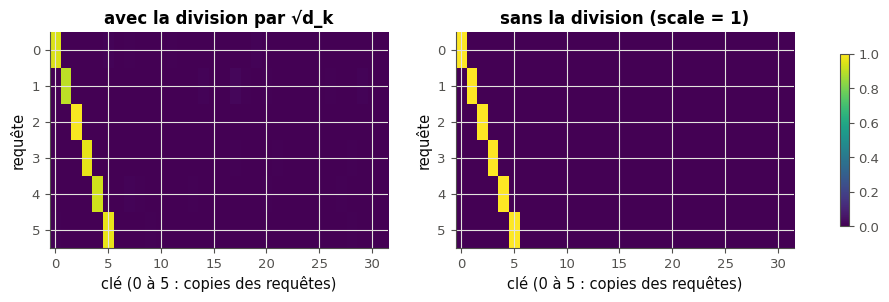

poids de la clé copiée, requête par requête : {'avec la division par √d_k': [0.944, 0.9, 0.989, 0.963, 0.926, 0.968], 'sans la division (scale = 1)': [1.0, 1.0, 1.0, 1.0, 1.0, 1.0]}


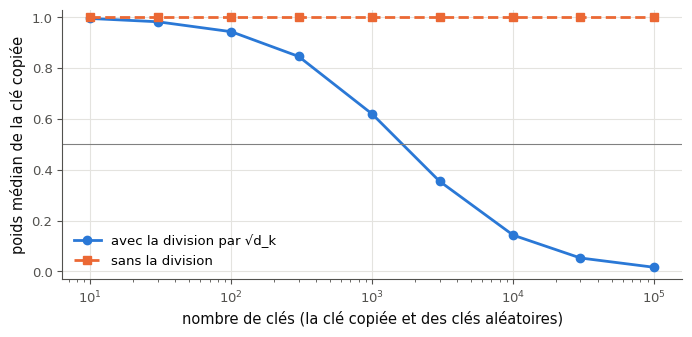

     10 clés : 0,995 avec la division, 1,000000 sans
     30 clés : 0,982 avec la division, 1,000000 sans
    100 clés : 0,943 avec la division, 1,000000 sans
    300 clés : 0,846 avec la division, 1,000000 sans
  1 000 clés : 0,619 avec la division, 1,000000 sans
  3 000 clés : 0,355 avec la division, 1,000000 sans
 10 000 clés : 0,143 avec la division, 1,000000 sans
 30 000 clés : 0,053 avec la division, 1,000000 sans
100 000 clés : 0,017 avec la division, 1,000000 sans
✅ Ex B3.13a : Bravo !
✅ Ex B3.13b : Exact !


In [29]:
if any(answer is ... or answer is None for answer in [exponent_13, keeps_half_13]):
    print("⏳ Ex B3.13 : écris d'abord tes deux prédictions dans la cellule précédente.")
else:
    # 1. the attention map: 6 queries; keys 0 to 5 copy them, keys 6 to 31 are random (your scaled_dot_product_attention)
    rng_13 = np.random.default_rng(130)
    q_13 = rng_13.normal(size=(6, D_13))
    k_13 = np.vstack([q_13, rng_13.normal(size=(26, D_13))])
    maps_13 = None
    with checked("B3.13"):
        maps_13 = {"avec la division par √d_k": np.asarray(mylearn.attention.scaled_dot_product_attention(q_13, k_13, k_13)[1]),
                   "sans la division (scale = 1)": np.asarray(mylearn.attention.scaled_dot_product_attention(q_13, k_13, k_13, scale=1.0)[1])}
    if maps_13 is not None:
        fig, axes = plt.subplots(1, 2, figsize=(12, 2.8))
        for ax, (title, w) in zip(axes, maps_13.items()):
            im = ax.imshow(w, cmap="viridis", vmin=0, vmax=1, aspect="auto")
            ax.set_title(title)
            ax.set_xlabel("clé (0 à 5 : copies des requêtes)")
            ax.set_ylabel("requête")
        fig.colorbar(im, ax=axes, shrink=0.8)
        plt.show()
        print("poids de la clé copiée, requête par requête :",
              {title: np.round(np.diag(w[:, :6]), 3).tolist() for title, w in maps_13.items()})
    else:
        print("⏳ Ex B3.13 : la carte attend ta scaled_dot_product_attention (B3.12) ; la courbe ci-dessous n'en a pas besoin.")

    # 2. the median weight of the copied key over 200 queries, from 10 to 100 000 keys
    medians_13 = {scaled: [float(np.median(copied_weight_13(n, scaled))) for n in KEYS_13] for scaled in (True, False)}
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.semilogx(KEYS_13, medians_13[True], "o-", label="avec la division par √d_k")
    ax.semilogx(KEYS_13, medians_13[False], "s--", label="sans la division")
    ax.axhline(0.5, color="gray", lw=0.8)
    ax.set_xlabel("nombre de clés (la clé copiée et des clés aléatoires)")
    ax.set_ylabel("poids médian de la clé copiée")
    ax.set_ylim(-0.03, 1.03)
    ax.legend()
    plt.show()
    for n_13, with_13, without_13 in zip(KEYS_13, medians_13[True], medians_13[False]):
        print(f"{n_13:>7_} clés : {fr(with_13, 3)} avec la division, {fr(without_13, 6)} sans".replace("_", " "))
    wb.check("B3.13a", exponent_13)
    wb.check("B3.13b", keeps_half_13)

Dans tes notes : pour chaque prédiction ratée, qu'est-ce qui t'a trompé ? Relie la courbe « avec la division » à ∂ B3.6 : quel est le score typique de la clé copiée, celui des autres clés, et que compare la softmax ? Refais la courbe avec `d_k = 16`, puis `d_k = 256` (`copied_weight_13(n, True, d_k=…)`) : où se place la bascule, et que corrige exactement la division par $\sqrt{d_k}$ ?

### Ex B3.14 — split_heads, merge_heads et multi_head_attention 🔨 ★★★ ⏱️ 45 min
**Objectif :** découper en têtes, recoller, puis assembler une attention multi-têtes complète, validée contre `nn.MultiheadAttention`.  
**Prérequis :** Ex B3.12 · ✏️ B3.3 · fiche §203.4 (« Une seule matrice pour toutes les têtes », piège du reshape direct) · **mylearn :** `attention.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/attention.py` (créé par `python tools/start_chapter.py B3`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy seulement. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb3_attention.py -q` les lance tous dans un terminal.

**Contrat**
- `split_heads(x, n_heads)` : `(N, T, D)` → `(N, H, T, D // H)` ; la tête $h$ reçoit les features $h\,d_h$ à $(h + 1)\,d_h - 1$ de chaque token ($d_h = D / H$). `ValueError` si `x` n'est pas 3-D ou si $H$ ne divise pas $D$.
- `merge_heads(x)` : l'inverse, `(N, H, T, d_h)` → `(N, T, H d_h)`, la tête 0 d'abord ; `merge_heads(split_heads(x, H))` redonne `x`. `ValueError` si `x` n'est pas 4-D.
- `multi_head_attention(query, key, value, params, n_heads, mask=None)` rend le couple `(output, weights)`, de formes `(N, L, D)` et `(N, H, L, S)` :
  - $\mathbf{Q} = \text{query}\,\mathbf{W}_q + \mathbf{b}_q$ (de même $\mathbf{K}$ avec `key` et $\mathbf{V}$ avec `value`), le découpage en têtes, ta `scaled_dot_product_attention` (B3.12) dans chaque tête avec son échelle par défaut, le recollage, puis la projection de sortie $\mathbf{W}_o$, $\mathbf{b}_o$ ; l'auto-attention est `query = key = value = x` ;
  - `params` : `W_q`, `W_k`, `W_v`, `W_o` de forme `(D, D)` et `b_q`, `b_k`, `b_v`, `b_o` de forme `(D,)`, dans un mapping quelconque (aussi en lecture seule, `MappingProxyType`) ; ses autres clés sont ignorées (les paramètres d'un bloc entier passent) ; un paramètre manquant lève `ValueError`, pas `KeyError` ;
  - `mask` (`True` = autorisé) de forme `(L, S)`, `(N, 1, 1, S)`, `(N, 1, L, S)` ou `(N, H, L, S)` ; les tests prennent aussi de l'attention croisée, où $L \ne S$.

La première cellule de vérification essaie tes deux fonctions de têtes sur l'exemple de la docstring, contre `view(N, T, H, d_h).transpose(1, 2)` de PyTorch, puis l'aller-retour et deux refus. Elle compare ensuite ton attention multi-têtes à `nn.MultiheadAttention` aux mêmes poids (la fonction `params_from_mha` de la cellule des outils montre la conversion : PyTorch range $\mathbf{W}_q^\top$, $\mathbf{W}_k^\top$, $\mathbf{W}_v^\top$ empilées dans `in_proj_weight`, et attend le masque inversé, `~mask`), en auto-attention causale puis en attention croisée avec un masque de padding, et essaie un paramètre manquant. La seconde lance les 48 tests de l'exercice (`-k "test_split_heads_ or test_merge_heads_ or test_multi_head_attention_"`).

Dans tes notes : un reshape direct `(N, T, D)` → `(N, H, T, d_h)`, sans échange d'axes, donne la bonne forme : quelles features reçoit alors chaque tête (fiche §203.4) ? Pourquoi `params_from_mha` transpose-t-elle chaque bloc de `in_proj_weight` ? Que changerait une échelle $1/\sqrt{D}$ au lieu de $1/\sqrt{d_h}$ ?

In [30]:
with checked("B3.14"):
    A = mylearn.attention
    x_14 = np.arange(12.0).reshape(1, 2, 6)
    h_14 = A.split_heads(x_14, 3)
    if returned("B3.14", "split_heads", h_14):
        verdict("B3.14", np.shape(h_14) == (1, 3, 2, 2) and np.array_equal(np.asarray(h_14)[0, 1], [[2.0, 3.0], [8.0, 9.0]]),
                "split_heads(arange(12).reshape(1, 2, 6), 3) : forme (1, 3, 2, 2), la tête 1 a les features 2 et 3.",
                f"split_heads(x, 3) doit rendre la forme (1, 3, 2, 2) et la tête 1 [[2, 3], [8, 9]] ; reçu la forme "
                f"{np.shape(h_14)} et la tête 1 {np.asarray(h_14)[0, 1].tolist() if np.ndim(h_14) == 4 else '?'}.")
    rng_14 = np.random.default_rng(14)
    x_14 = rng_14.normal(size=(2, 5, 12))
    want_14 = torch.from_numpy(x_14).view(2, 5, 4, 3).transpose(1, 2).numpy()
    same("B3.14", "split_heads(x (2, 5, 12), 4) contre view(2, 5, 4, 3).transpose(1, 2)", A.split_heads(x_14, 4), want_14,
         rtol=0, atol=0)
    same("B3.14", "merge_heads(split_heads(x, 4)), qui doit redonner x", A.merge_heads(A.split_heads(x_14, 4)), x_14, rtol=0, atol=0)
    refuses("B3.14", "split_heads d'un x 2-D", lambda: A.split_heads(np.ones((5, 12)), 4))
    refuses("B3.14", "split_heads avec 5 têtes pour D = 12", lambda: A.split_heads(x_14, 5))

    # multi_head_attention against nn.MultiheadAttention with the same weights (float64)
    torch.manual_seed(14)
    D_14, H_14 = 12, 3
    mha_14 = nn.MultiheadAttention(D_14, H_14, batch_first=True).double()
    params_14 = params_from_mha(mha_14) | {"ln1_gamma": np.ones(D_14)}         # an extra key: ignored
    saved_14 = {name: p.copy() for name, p in params_14.items()}
    xt_14 = torch.from_numpy(x_14)
    with torch.no_grad():
        want_o, want_w = mha_14(xt_14, xt_14, xt_14, attn_mask=torch.from_numpy(~causal_np(5)), average_attn_weights=False)
    out_14, w_14 = pair("B3.14", "multi_head_attention", A.multi_head_attention(x_14, x_14, x_14, MappingProxyType(params_14), H_14,
                                                                             mask=causal_np(5)), names=("output", "weights"))
    same("B3.14", "auto-attention causale (2, 5, 12), 3 têtes, contre nn.MultiheadAttention (masque ~mask)", out_14, want_o.numpy(),
         rtol=1e-6, atol=1e-6)
    same("B3.14", "poids par tête (2, 3, 5, 5)", w_14, want_w.numpy(), rtol=1e-6, atol=1e-6)
    enc_14 = rng_14.normal(size=(2, 9, D_14))
    keys_14 = np.arange(9) < np.array([9, 6])[:, None]                        # sequence 1: 6 real keys out of 9
    with torch.no_grad():
        want_x, _ = mha_14(xt_14, torch.from_numpy(enc_14), torch.from_numpy(enc_14), key_padding_mask=torch.from_numpy(~keys_14))
    out_x, w_x = pair("B3.14", "multi_head_attention", A.multi_head_attention(x_14, enc_14, enc_14, params_14, H_14,
                                                                           mask=keys_14[:, None, None, :]), names=("output", "weights"))
    same("B3.14", "attention croisée (5 requêtes, 9 clés) avec un masque de padding (2, 1, 1, 9)", out_x, want_x.numpy(),
         rtol=1e-6, atol=1e-6)
    verdict("B3.14", all(np.array_equal(params_14[name], saved_14[name]) for name in saved_14),
            "les paramètres reçus n'ont pas changé.", "multi_head_attention a modifié les paramètres reçus.")
    no_wo_14 = {name: p for name, p in params_14.items() if name != "W_o"}
    refuses("B3.14", "multi_head_attention sans W_o (ValueError, pas KeyError)",
            lambda: A.multi_head_attention(x_14, x_14, x_14, no_wo_14, H_14))

✅ Ex B3.14 : split_heads(arange(12).reshape(1, 2, 6), 3) : forme (1, 3, 2, 2), la tête 1 a les features 2 et 3.
✅ Ex B3.14 : split_heads(x (2, 5, 12), 4) contre view(2, 5, 4, 3).transpose(1, 2) : un tableau (2, 4, 5, 3), comme attendu.
✅ Ex B3.14 : merge_heads(split_heads(x, 4)), qui doit redonner x : un tableau (2, 5, 12), comme attendu.
✅ Ex B3.14 : split_heads d'un x 2-D : ValueError levée (x must be 3-D of shape (N, T, D), got shape (5, 12)).
✅ Ex B3.14 : split_heads avec 5 têtes pour D = 12 : ValueError levée (n_heads = 5 must divide D = 12).
✅ Ex B3.14 : auto-attention causale (2, 5, 12), 3 têtes, contre nn.MultiheadAttention (masque ~mask) : un tableau (2, 5, 12), comme attendu.
✅ Ex B3.14 : poids par tête (2, 3, 5, 5) : un tableau (2, 3, 5, 5), comme attendu.
✅ Ex B3.14 : attention croisée (5 requêtes, 9 clés) avec un masque de padding (2, 1, 1, 9) : un tableau (2, 5, 12), comme attendu.
✅ Ex B3.14 : les paramètres reçus n'ont pas changé.
✅ Ex B3.14 : multi_head_attention sans 

In [31]:
if written(lambda: mylearn.attention.split_heads(np.ones((1, 2, 4)), 2)):
    run_pytest_group(TEST_ATT, impl="ref", keyword="test_split_heads_ or test_merge_heads_ or test_multi_head_attention_")   # 48 tests
else:
    print("⏳ Ex B3.14 : les tests attendent tes fonctions.")

pytest: 48 passed, 120 deselected in 1.55s


### Ex B3.15 — positional_encoding et apply_rope 🔨 ★★ ⏱️ 30 min
**Objectif :** écrire l'encodage sinusoïdal et RoPE, et vérifier leurs propriétés et la convention de Hugging Face.  
**Prérequis :** ✏️ B3.4 · ∂ B3.7 · fiche §203.5 (« L'encodage sinusoïdal (2017) », « RoPE : tourner les requêtes et les clés ») · **mylearn :** `attention.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/attention.py` (créé par `python tools/start_chapter.py B3`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy seulement. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb3_attention.py -q` les lance tous dans un terminal.

**Contrat**
- `positional_encoding(seq_len, d_model, base=10000.0)` : le tableau `(T, D)` en float64 de $PE_{p, 2i} = \sin(p / \text{base}^{2i/D})$ et $PE_{p, 2i+1} = \cos(p / \text{base}^{2i/D})$, pour $i = 0 \dots D/2 - 1$. `base = 1` est accepté ; `ValueError` si `d_model` est impair, ou si `seq_len`, `d_model` ou `base` est < 1. Les tests vont jusqu'à $T = 1\,000$ : B5 s'en resservira.
- `apply_rope(x, positions=None, base=10000.0)` : `x` de forme `(..., T, d)`, $d$ pair, une requête ou une clé par position ; la convention **« rotate half »** de Hugging Face (Llama) : la dimension $i$ est appariée avec $i + d/2$ (pour $i < d/2$), pas avec $i + 1$ comme dans l'article de RoFormer, et la paire $(x_1, x_2)$ tourne de l'angle $\theta = \text{position} \cdot \text{base}^{-2i/d}$ :
  $(x_1 \cos\theta - x_2 \sin\theta,\ x_2 \cos\theta + x_1 \sin\theta)$ ;
  - `positions` : exactement $T$ positions (`np.arange(T)` si `None`) ; une seule position pour $T$ vecteurs est refusée, même si NumPy la diffuserait ;
  - rend un tableau de la forme de `x` ; `ValueError` si $d$ est impair ou si `positions` n'a pas la longueur $T$ ;
  - comparé à `LlamaRotaryEmbedding` et `apply_rotary_pos_emb` de transformers, à $10^{-5}$ (ils calculent les angles en float32).

La première cellule de vérification essaie ton encodage sur l'exemple de la docstring, sur 1 000 positions et sur la propriété du décalage (§203.5 : décaler de 7 positions applique la même rotation à chaque paire (sin, cos)), puis RoPE sur l'exemple de la docstring, la conservation des normes, la propriété relative (le produit scalaire ne dépend que de $m - n$, ∂ B3.7) et contre `LlamaRotaryEmbedding` ; enfin quatre refus. La seconde lance les 40 tests de l'exercice (`-k "test_positional_encoding_ or test_apply_rope_"`).

Dans tes notes : pourquoi RoPE tourne-t-il les requêtes et les clés, mais pas les valeurs ? Le produit scalaire d'une requête et d'une clé change-t-il quand on décale toutes les positions de 1 000 (`positions = np.arange(T) + 1000`) ? Mesure-le. Qu'apporte la convention « rotate half » par rapport aux paires $(2i, 2i + 1)$, et que perd-on à confondre les deux ?

In [32]:
with checked("B3.15"):
    A = mylearn.attention
    pos_15 = np.arange(3)[:, None] / 10000.0 ** (np.arange(0, 4, 2) / 4)       # the formula of the docstring
    want_15 = np.stack([np.sin(pos_15), np.cos(pos_15)], axis=-1).reshape(3, 4)
    same("B3.15", "positional_encoding(3, 4)", A.positional_encoding(3, 4), want_15, rtol=1e-6, atol=1e-6)
    pe_15 = np.asarray(A.positional_encoding(1000, 64))
    verdict("B3.15", pe_15.shape == (1000, 64) and pe_15.dtype == np.float64 and np.abs(pe_15).max() <= 1,
            "positional_encoding(1000, 64) : forme (1000, 64), float64, valeurs dans [−1, 1].",
            f"positional_encoding(1000, 64) : attendu un tableau float64 (1000, 64) dans [−1, 1] ; reçu {pe_15.dtype} {pe_15.shape}.")
    omega_15 = 10000.0 ** (-np.arange(32) / 32)                                  # one frequency per (sin, cos) pair
    c_15, s_15 = np.cos(7 * omega_15), np.sin(7 * omega_15)
    sin_15, cos_15 = pe_15[:-7, 0::2], pe_15[:-7, 1::2]
    shifted_15 = np.stack([sin_15 * c_15 + cos_15 * s_15, cos_15 * c_15 - sin_15 * s_15], axis=-1).reshape(993, 64)
    same("B3.15", "un décalage de 7 positions = une rotation fixe de chaque paire (sin, cos) (§203.5)", pe_15[7:], shifted_15,
         rtol=1e-6, atol=1e-6)
    refuses("B3.15", "positional_encoding(4, 5) (d_model impair)", lambda: A.positional_encoding(4, 5))
    refuses("B3.15", "positional_encoding(0, 4)", lambda: A.positional_encoding(0, 4))

    ones_15 = np.ones((3, 4))
    half_15 = 10000.0 ** (-2 * np.arange(2) / 4)                                  # theta = position * base**(-2i/d)
    z_15 = (1 + 1j) * np.exp(1j * np.arange(3)[:, None] * half_15)                # pair (x_i, x_{i+d/2}) as x_i + i x_{i+d/2}
    same("B3.15", "apply_rope(np.ones((3, 4))) (paires (i, i + d/2))", A.apply_rope(ones_15),
         np.concatenate([z_15.real, z_15.imag], axis=1), rtol=1e-6, atol=1e-6)
    rng_15 = np.random.default_rng(15)
    x_15 = rng_15.normal(size=(2, 3, 10, 8))
    same("B3.15", "normes de apply_rope(x (2, 3, 10, 8)), égales à celles de x", np.linalg.norm(A.apply_rope(x_15), axis=-1),
         np.linalg.norm(x_15, axis=-1), rtol=1e-6, atol=1e-6)
    q_15, k_15 = rng_15.normal(size=(1, 8)), rng_15.normal(size=(1, 8))
    dots_15 = [(np.asarray(A.apply_rope(q_15, [m])) @ np.asarray(A.apply_rope(k_15, [n])).T).item()
               for m, n in ((3, 1), (12, 10), (102, 100))]
    verdict("B3.15", np.allclose(dots_15, dots_15[0], rtol=1e-6, atol=1e-6),
            "⟨RoPE(q, m), RoPE(k, n)⟩ ne dépend que de m − n : " + ", ".join(fr(d, 4) for d in dots_15) + " pour (3, 1), (12, 10), (102, 100).",
            "⟨RoPE(q, m), RoPE(k, n)⟩ doit être le même pour (3, 1), (12, 10) et (102, 100) (m − n = 2) ; reçu "
            + ", ".join(fr(d, 4) for d in dots_15) + ".")
    try:
        from transformers.models.llama.configuration_llama import LlamaConfig
        from transformers.models.llama.modeling_llama import LlamaRotaryEmbedding, apply_rotary_pos_emb
    except ImportError:
        print("⏳ Ex B3.15 : la comparaison à LlamaRotaryEmbedding attend la bibliothèque transformers (Colab).")
    else:
        config_15 = LlamaConfig(hidden_size=24, num_attention_heads=3, head_dim=8, max_position_embeddings=128,
                                rope_parameters={"rope_type": "default", "rope_theta": 10000.0})
        cos_hf, sin_hf = LlamaRotaryEmbedding(config_15)(torch.from_numpy(x_15), torch.arange(10)[None, :])
        want_hf, _ = apply_rotary_pos_emb(torch.from_numpy(x_15), torch.from_numpy(x_15), cos_hf, sin_hf)
        same("B3.15", "apply_rope(x) contre LlamaRotaryEmbedding + apply_rotary_pos_emb de transformers (angles en float32 : 1e-5)",
             A.apply_rope(x_15), want_hf.numpy(), rtol=1e-5, atol=1e-5)
    refuses("B3.15", "apply_rope(np.ones((3, 4)), positions=[0]) (une position pour trois vecteurs)",
            lambda: A.apply_rope(ones_15, positions=[0]))
    refuses("B3.15", "apply_rope(np.ones((3, 5))) (d impair)", lambda: A.apply_rope(np.ones((3, 5))))

✅ Ex B3.15 : positional_encoding(3, 4) : un tableau (3, 4), comme attendu.
✅ Ex B3.15 : positional_encoding(1000, 64) : forme (1000, 64), float64, valeurs dans [−1, 1].
✅ Ex B3.15 : un décalage de 7 positions = une rotation fixe de chaque paire (sin, cos) (§203.5) : un tableau (993, 64), comme attendu.
✅ Ex B3.15 : positional_encoding(4, 5) (d_model impair) : ValueError levée (d_model must be even, got 5).
✅ Ex B3.15 : positional_encoding(0, 4) : ValueError levée (seq_len must be >= 1, got 0).
✅ Ex B3.15 : apply_rope(np.ones((3, 4))) (paires (i, i + d/2)) : un tableau (3, 4), comme attendu.
✅ Ex B3.15 : normes de apply_rope(x (2, 3, 10, 8)), égales à celles de x : un tableau (2, 3, 10), comme attendu.
✅ Ex B3.15 : ⟨RoPE(q, m), RoPE(k, n)⟩ ne dépend que de m − n : 1,6224, 1,6224, 1,6224 pour (3, 1), (12, 10), (102, 100).
✅ Ex B3.15 : apply_rope(x) contre LlamaRotaryEmbedding + apply_rotary_pos_emb de transformers (angles en float32 : 1e-5) : un tableau (2, 3, 10, 8), comme attendu.
✅ Ex

In [33]:
if written(lambda: mylearn.attention.positional_encoding(2, 2)):
    run_pytest_group(TEST_ATT, impl="ref", keyword="test_positional_encoding_ or test_apply_rope_")   # 40 tests
else:
    print("⏳ Ex B3.15 : les tests attendent tes fonctions.")

pytest: 40 passed, 128 deselected in 4.53s


### Ex B3.16 — transformer_block en NumPy, validé contre nn.TransformerEncoderLayer 🔨 ★★★★ ⏱️ 100 min
**Objectif :** assembler un bloc Transformer pré-LN complet en NumPy, et le valider au millionième contre PyTorch.  
**Prérequis :** Ex B3.14 · ch. 20 (layer norm, 20.17) · ch. 17 (GELU, 17.14) · fiche §203.6 (« Pré-LN ou post-LN », « Le bloc en équations, et sa vérification ») · **mylearn :** `attention.py` · **Parcours :** C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/attention.py` (créé par `python tools/start_chapter.py B3`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy seulement. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb3_attention.py -q` les lance tous dans un terminal.

**Contrat** de `transformer_block(x, params, n_heads, mask=None, eps=1e-5)`, le bloc pré-LN de GPT-2, sans dropout :
- $\mathbf{h} = \mathbf{x} + \operatorname{MHA}(\operatorname{LN}_1(\mathbf{x}))$ en auto-attention (ta `multi_head_attention`, avec `mask`), puis $\text{out} = \mathbf{h} + \operatorname{gelu}(\operatorname{LN}_2(\mathbf{h})\,\mathbf{W}_1 + \mathbf{b}_1)\,\mathbf{W}_2 + \mathbf{b}_2$ ;
- la GELU **exacte** (avec la fonction d'erreur), pas l'approximation tanh ; `eps` sert aux **deux** layer norms ;
- `params` : les clés de `multi_head_attention`, plus `ln1_gamma`, `ln1_beta`, `ln2_gamma`, `ln2_beta` de forme `(D,)`, `W_1` `(D, F)`, `b_1` `(F,)`, `W_2` `(F, D)` et `b_2` `(D,)` ; la largeur $F$ du MLP se lit dans `W_1` ; un paramètre manquant lève `ValueError` ;
- rend `(N, T, D)` ; `x` et `params` ne sont pas modifiés.

**Tes fonctions des ch. 17 et 20.** Le stub importe ta `gelu` (`nn/activations.py`, Ex 17.14) et ta `layer_norm` (`nn/regularization.py`, Ex 20.17) : réutilise-les. Si l'un de ces fichiers manque dans ta librairie, la référence le remplace (une ligne ℹ️ le dit). S'il existe mais que la fonction n'est pas encore écrite, la première cellule de vérification te le signale : écris-la (son exercice), ou recode la layer norm et la GELU dans `attention.py`, ce que les tests acceptent aussi. Les tests passent par tes fonctions si tu les réutilises : si l'un d'eux échoue, lance d'abord les tests de 17.14 et de 20.17 (le message de l'échec le dit).

La première cellule de vérification construit le même bloc en PyTorch, `nn.TransformerEncoderLayer(16, 4, 64, dropout=0.0, activation="gelu", batch_first=True, norm_first=True)` en float64, recopie ses poids dans ta convention (`block_params_from_torch` dans la cellule des outils : `W = weight.T` pour chaque couche dense), et compare ta sortie à la sienne avec le masque causal (passé à PyTorch en `~mask`), sans masque, puis avec `eps = 0.1` ; elle essaie enfin un paramètre manquant. La seconde lance les 25 tests de l'exercice (`-k "test_transformer_block_"`).

Dans tes notes : avec tous les poids à zéro (l'exemple de la docstring), que rend ton bloc, et que dit ce résultat des connexions résiduelles ? En quoi ton bloc changerait-il pour un post-LN (§203.6) ? Remplace ta GELU par l'approximation tanh : de combien ta sortie s'écarte-t-elle de celle de PyTorch, et le test l'aurait-il vu ?

In [34]:
with checked("B3.16"):
    A = mylearn.attention
    for name_16, probe_16, where_16 in (
            ("gelu", lambda: mylearn.nn.activations.gelu(np.zeros(2)), "nn/activations.py, Ex 17.14"),
            ("layer_norm", lambda: mylearn.nn.regularization.layer_norm(np.zeros((1, 4)), np.ones(4), np.zeros(4)),
             "nn/regularization.py, Ex 20.17")):
        if not written(probe_16):
            print(f"ℹ️ Ex B3.16 : ta {name_16} ({where_16}) n'est pas encore écrite : écris-la, ou recode-la dans "
                  "transformer_block (l'énoncé le permet).")
    # the same block in PyTorch: nn.TransformerEncoderLayer, pre-LN, exact GELU, no dropout, in float64
    torch.manual_seed(16)
    D_16, H_16, F_16 = 16, 4, 64
    layer_16 = nn.TransformerEncoderLayer(D_16, H_16, F_16, dropout=0.0, activation="gelu", batch_first=True,
                                          norm_first=True).double().eval()
    params_16 = block_params_from_torch(layer_16)
    saved_16 = {name: p.copy() for name, p in params_16.items()}
    x_16 = np.random.default_rng(16).normal(size=(2, 7, D_16))
    x_copy_16 = x_16.copy()
    with torch.no_grad():
        want_c16 = layer_16(torch.from_numpy(x_16), src_mask=torch.from_numpy(~causal_np(7))).numpy()
        want_n16 = layer_16(torch.from_numpy(x_16)).numpy()
    same("B3.16", "transformer_block(x (2, 7, 16), 4 têtes, masque causal) contre nn.TransformerEncoderLayer(norm_first=True)",
         A.transformer_block(x_16, params_16, H_16, mask=causal_np(7)), want_c16, rtol=1e-6, atol=1e-6)
    same("B3.16", "le même bloc sans masque (un encodeur)", A.transformer_block(x_16, params_16, H_16), want_n16,
         rtol=1e-6, atol=1e-6)
    layer_e16 = nn.TransformerEncoderLayer(D_16, H_16, F_16, dropout=0.0, activation="gelu", batch_first=True,
                                           norm_first=True, layer_norm_eps=0.1).double().eval()
    layer_e16.load_state_dict(layer_16.state_dict())
    with torch.no_grad():
        want_e16 = layer_e16(torch.from_numpy(x_16)).numpy()
    same("B3.16", "eps=0.1 (les deux layer norms)", A.transformer_block(x_16, params_16, H_16, eps=0.1), want_e16,
         rtol=1e-6, atol=1e-6)
    verdict("B3.16", np.array_equal(x_16, x_copy_16) and all(np.array_equal(params_16[k], saved_16[k]) for k in saved_16),
            "x et les paramètres reçus n'ont pas changé.", "transformer_block a modifié x ou les paramètres reçus.")
    no_w1_16 = {name: p for name, p in params_16.items() if name != "W_1"}
    refuses("B3.16", "transformer_block sans W_1 (ValueError, pas KeyError)", lambda: A.transformer_block(x_16, no_w1_16, H_16))

✅ Ex B3.16 : transformer_block(x (2, 7, 16), 4 têtes, masque causal) contre nn.TransformerEncoderLayer(norm_first=True) : un tableau (2, 7, 16), comme attendu.
✅ Ex B3.16 : le même bloc sans masque (un encodeur) : un tableau (2, 7, 16), comme attendu.
✅ Ex B3.16 : eps=0.1 (les deux layer norms) : un tableau (2, 7, 16), comme attendu.
✅ Ex B3.16 : x et les paramètres reçus n'ont pas changé.
✅ Ex B3.16 : transformer_block sans W_1 (ValueError, pas KeyError) : ValueError levée (missing parameter(s): W_1).


In [35]:
if written(lambda: mylearn.attention.transformer_block(np.zeros((1, 1, 2)), {}, 1)):
    run_pytest_group(TEST_ATT, impl="ref", keyword="test_transformer_block_")   # 25 tests
else:
    print("⏳ Ex B3.16 : les tests attendent ta fonction transformer_block.")

pytest: 25 passed, 143 deselected in 1.28s


### Ex B3.17 — Trois masques qui mentent : convention inversée, masque transposé, padding compté dans la loss 🐛 ★★ ⏱️ 25 min
**Objectif :** trouver et corriger les trois erreurs de masque d'un petit modèle de langue, guidé par des diagnostics enchaînés.  
**Prérequis :** Ex B3.12 · fiche §203.3 (encadrés 🕰️ sur `F.scaled_dot_product_attention` et `nn.MultiheadAttention`), §203.8 (« La loss et la perplexité ») · tableau des pièges ⚠️ · **Fil rouge :** Holmes · **Parcours :** R, C

Une collègue a écrit un petit modèle de langue au niveau caractère : une couche d'attention causale sur les embeddings des caractères et de leurs positions, puis une couche dense. Elle calculait d'abord l'attention avec `F.scaled_dot_product_attention`, puis elle est passée à `nn.MultiheadAttention` pour lire les poids d'attention. Le modèle s'entraîne sur des lignes de Holmes de longueurs différentes, complétées par du padding. Son code contient **trois** erreurs. Corrige-le **sur place**, dans sa cellule, sans changer les noms, les signatures ni ce que rendent les fonctions.

Ce qu'il devrait faire :
- `causal_mask_17(T)` : le masque causal `(T, T)` dans la convention de `F.scaled_dot_product_attention`, `True` là où la requête $i$ peut regarder la clé $j$ ;
- `TinyLM_17` : des ids `(N, T)` → des logits `(N, T, V)`, chaque position ne voyant que les caractères jusqu'à elle ; `self.weights` garde les poids d'attention (la moyenne des deux têtes) ;
- `lm_loss_17(logits, targets)` : la cross-entropy moyenne sur les **vrais** caractères du batch ; les cibles valent `PAD_17` sur le padding.

La cellule donnée prépare les données : `LINES_17` (des lignes de l'entraînement de Holmes, de 24 à 64 caractères), `batch_17` (un batch de lignes, entrées et cibles décalées d'un caractère, complétées par `PAD_17`), `VAL_17` (64 fenêtres de 64 caractères de la validation, sans padding). Elle définit aussi `diagnose_17`. La cellule de vérification lance `diagnose_17`, trois diagnostics enchaînés, chacun ne s'exécutant que si le précédent passe, car une erreur peut en cacher une autre :
- la loss d'un batch est-elle un nombre ?
- le modèle voit-il le futur ? (un caractère changé, puis 200 itérations d'entraînement, quelques secondes)
- la loss d'un batch dépend-elle de son padding ?

Elle tourne dès le premier « Tout exécuter » : ses messages sont ton point de départ. Une fois les trois points passés, la cellule suivante trace les poids d'attention de ta version réparée sur une ligne de Holmes.

Dans tes notes : les trois erreurs, et pour chacune le symptôme qu'elle produirait seule. Pourquoi les `nan` n'apparaissent-ils qu'à une seule position, et laquelle, selon que l'autre erreur de masque est encore là ou non ? Laquelle des trois erreurs fait baisser la loss d'entraînement sans que le modèle prédise mieux le texte ?

In [36]:
PAD_17 = len(DATA.itos)                    # one more id for the padding: 89 ids in all
VOCAB_17, LEN_17 = PAD_17 + 1, 64
LINES_17 = [line for line in DATA.train_text.split("\n") if 24 <= len(line) <= LEN_17]    # lines of Holmes
VAL_17 = DATA.val_ids[:LEN_17 * 64].view(64, LEN_17)                                       # 64 windows, no padding


def batch_17(lines, generator, batch_size=32):
    """A batch of lines of Holmes: inputs ids[:-1] and targets ids[1:], padded with PAD_17 to LEN_17 - 1 positions."""
    picks = torch.randint(len(lines), (batch_size,), generator=generator).tolist()
    width = max(len(lines[i]) for i in picks) - 1
    x = torch.full((batch_size, width), PAD_17)
    y = torch.full((batch_size, width), PAD_17)
    for row, i in enumerate(picks):
        ids = DATA.encode(lines[i])
        x[row, :len(ids) - 1], y[row, :len(ids) - 1] = ids[:-1], ids[1:]
    return x, y


def diagnose_17(model_class, loss_fn, iters=200):
    """Three diagnoses of the small language model, in a row: the first one that fails stops the chain (one error can
    hide another). Returns the trained model when the three pass, else None."""
    torch.manual_seed(17)
    model = model_class(VOCAB_17)
    gen = torch.Generator().manual_seed(17)
    x, y = batch_17(LINES_17, gen)

    def point1():
        with torch.no_grad():
            logits = model(x)
            loss = loss_fn(logits, y)
        if torch.isfinite(loss) and torch.isfinite(logits).all():
            return True, f"la loss d'un batch à l'initialisation est un nombre, {fr(loss.item(), 3)}", ""
        bad = sorted({int(t) for t in torch.nonzero(~torch.isfinite(logits).all(dim=-1))[:, 1]})
        return False, (f"la loss d'un batch vaut {loss.item()} ; les logits sont nan à la position {bad[0]} de chaque séquence"
                       if len(bad) == 1 else f"la loss d'un batch vaut {loss.item()} ; logits nan aux positions {bad[:6]}"), \
            "que voit cette position dans la couche d'attention ?"

    def point2():
        probe = VAL_17[:4].clone()
        changed = probe.clone()
        changed[:, 40] = (changed[:, 40] + 1) % PAD_17                      # change the character 40 of each window
        with torch.no_grad():
            gap = (model(probe)[:, :40] - model(changed)[:, :40]).abs().max().item()
        optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3)
        for _ in range(iters):
            xb, yb = batch_17(LINES_17, gen)
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        with torch.no_grad():
            val = F.cross_entropy(model(VAL_17[:, :-1]).flatten(0, 1), VAL_17[:, 1:].flatten()).item()
        if gap < 1e-6:
            return True, (f"changer le caractère 40 d'une fenêtre ne change aucun logit des positions 0 à 39 ; après "
                          f"{iters} itérations, la loss de validation vaut {fr(val, 2)} nats par caractère"), ""
        return False, (f"changer le caractère 40 d'une fenêtre change les logits des positions 0 à 39 (écart maximal "
                       f"{gap:.2g}) ; après {iters} itérations, la loss de validation tombe à {fr(val, 2)} nat par "
                       "caractère"), "pour un modèle d'une seule couche, est-ce crédible ? D'où vient l'information ?"

    def point3():
        short = [line for line in LINES_17 if len(line) <= 40][:16]
        width = max(len(line) for line in short) - 1
        x_s = torch.full((16, width), PAD_17)
        y_s = torch.full((16, width), PAD_17)
        for row, line in enumerate(short):
            ids = DATA.encode(line)
            x_s[row, :len(ids) - 1], y_s[row, :len(ids) - 1] = ids[:-1], ids[1:]
        extra = 60 - width                                                   # the same lines, 60 positions wide
        x_l = torch.cat([x_s, torch.full((16, extra), PAD_17)], dim=1)
        y_l = torch.cat([y_s, torch.full((16, extra), PAD_17)], dim=1)
        with torch.no_grad():
            short_loss, long_loss = loss_fn(model(x_s), y_s).item(), loss_fn(model(x_l), y_l).item()
        if abs(short_loss - long_loss) < 1e-5:
            return True, (f"la loss d'un même batch ne dépend pas de son padding ({fr(short_loss, 4)} sur {width} "
                          f"positions comme sur 60)"), ""
        return False, (f"la loss d'un même batch de 16 lignes vaut {fr(short_loss, 4)} sur {width} positions et "
                       f"{fr(long_loss, 4)} une fois complété par {extra} positions de padding"), \
            "quelles positions entrent dans la moyenne ?"

    points = [("la loss est un nombre", point1), ("le modèle ne voit pas le futur", point2),
              ("le padding ne compte pas", point3)]
    for k, (name, run) in enumerate(points, start=1):
        ok, measured, why = run()
        if ok:
            print(f"✅ Ex B3.17 : point {k}, {name} ({measured}).")
        else:
            print(f"❌ Ex B3.17 : point {k} : {measured} ; {why}")
            for later in range(k + 1, len(points) + 1):
                print(f"⏳ Ex B3.17 : point {later} : corrige d'abord le point {k}.")
            return None
    print("✅ Ex B3.17 : les trois diagnostics passent.")
    return model

In [37]:
def causal_mask_17(T):
    """Boolean causal mask in the convention of F.scaled_dot_product_attention: True where query i may attend to key j."""
    return torch.ones(T, T, dtype=torch.bool).tril()                           # 2. the lower triangle: j <= i


class TinyLM_17(nn.Module):
    """One causal attention layer over character and position embeddings, then a dense layer: ids (N, T) -> logits
    (N, T, vocab_size)."""

    def __init__(self, vocab_size, d_model=32, n_head=2, max_len=64):
        super().__init__()
        self.tok = nn.Embedding(vocab_size, d_model)
        self.pos = nn.Embedding(max_len, d_model)
        self.attn = nn.MultiheadAttention(d_model, n_head, batch_first=True)
        self.ln = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, ids):
        T = ids.shape[1]
        x = self.tok(ids) + self.pos(torch.arange(T))
        h, self.weights = self.attn(x, x, x, attn_mask=~causal_mask_17(T))    # 1. nn.MultiheadAttention: True = masked
        return self.head(self.ln(x + h))


def lm_loss_17(logits, targets):
    """Mean cross-entropy over the real characters of a batch: logits (N, T, V), targets (N, T) with PAD_17 on the
    padding."""
    return F.cross_entropy(logits.reshape(-1, logits.shape[-1]), targets.reshape(-1),
                           ignore_index=PAD_17)                                # 3. the padding is left out of the mean


with checked("B3.17"):
    model_17 = diagnose_17(TinyLM_17, lm_loss_17)

✅ Ex B3.17 : point 1, la loss est un nombre (la loss d'un batch à l'initialisation est un nombre, 4,581).


✅ Ex B3.17 : point 2, le modèle ne voit pas le futur (changer le caractère 40 d'une fenêtre ne change aucun logit des positions 0 à 39 ; après 200 itérations, la loss de validation vaut 2,76 nats par caractère).
✅ Ex B3.17 : point 3, le padding ne compte pas (la loss d'un même batch ne dépend pas de son padding (2,8388 sur 39 positions comme sur 60)).
✅ Ex B3.17 : les trois diagnostics passent.


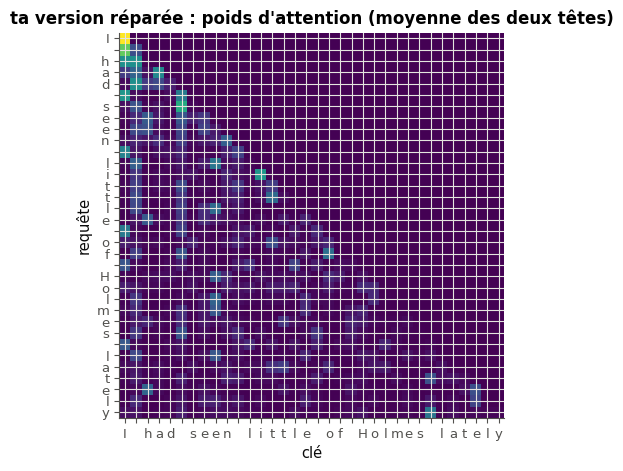

au-dessus de la diagonale, le plus grand poids vaut 0,000000


In [38]:
if globals().get("model_17") is None:
    print("⏳ Ex B3.17 : la carte attend que les trois points de la cellule précédente passent.")
else:
    with checked("B3.17"):
        line_17 = "I had seen little of Holmes lately."                  # a line of the first story
        ids_17 = DATA.encode(line_17)[None, :-1]
        model_17.eval()
        with torch.no_grad():
            logits_17 = model_17(ids_17)
        w_17 = model_17.weights[0].numpy()                                 # (T, T), averaged over the 2 heads
        fig, ax = plt.subplots(figsize=(6, 5))
        ax.imshow(w_17, cmap="viridis")
        ax.set_xticks(range(len(line_17) - 1), list(line_17[:-1]))
        ax.set_yticks(range(len(line_17) - 1), list(line_17[:-1]))
        ax.set_xlabel("clé")
        ax.set_ylabel("requête")
        ax.set_title("ta version réparée : poids d'attention (moyenne des deux têtes)")
        plt.show()
        print("au-dessus de la diagonale, le plus grand poids vaut", fr(float(np.triu(w_17, 1).max()), 6))

## Partie B · Le mini-GPT en PyTorch

Tu passes de NumPy à PyTorch : le module d'attention causale du mini-GPT, comparé à ta version NumPy (B3.18), le modèle complet (B3.19), puis son entraînement sur Holmes, face au LSTM du ch. 22 (B3.20). Le modèle suit la structure de nanoGPT (A. Karpathy, licence MIT, fiche §203.8) ; le contrat interdit `nn.Transformer…` et `nn.MultiheadAttention` dans ton modèle.

Le modèle que B3.20 entraîne est **sauvegardé une fois** (son `state_dict`, sa configuration, le vocabulaire et l'historique de l'entraînement), hors du dépôt, sous une clé qui dit tout ce qui l'a produit (configuration, réglages, graine, mode rapide ou complet, empreinte du découpage) : la suite du chapitre le recharge sans réentraîner. Ton modèle doit donc suivre les noms du contrat de B3.19.

La cellule suivante charge les outils de la partie : `MINI_CONFIG` (4 blocs, 4 têtes, $d = 128$, contexte de 128 caractères, 88 caractères), `n_params`, `forbidden_in` (les modules interdits trouvés dans un modèle), `params_from_qkv` (les poids de ton module d'attention dans la convention de `multi_head_attention`). Le vocabulaire est celui de ton `build_vocab` (ch. 22) : les caractères par fréquence décroissante, à égalité dans l'ordre de `sorted` ; la cellule vérifie que ta fonction donne le même. `wb.gpt` contient aussi une solution de référence de B3.18 à B3.20 (`ReferenceGPT`, `train`) : le notebook ne s'en sert que pour vérifier tes fonctions ou quand ton modèle manque ; ne la lis qu'une fois ta version écrite.

In [39]:
# Tools of part B: the mini-GPT in PyTorch
MINI_CONFIG = dict(wbgpt.MINI_CONFIG)          # 4 blocks, 4 heads, d = 128, context of 128 characters, 88 ids
FORBIDDEN = (nn.MultiheadAttention, nn.Transformer, nn.TransformerEncoder, nn.TransformerDecoder,
             nn.TransformerEncoderLayer, nn.TransformerDecoderLayer)


def n_params(model):
    """The number of parameters of a module, each tied parameter counted once (model.parameters() lists it once)."""
    return sum(p.numel() for p in model.parameters())


def forbidden_in(model):
    """The names of the ready-made attention modules of PyTorch found in a model (the contract forbids them)."""
    return sorted({type(m).__name__ for m in model.modules() if isinstance(m, FORBIDDEN)})


def params_from_qkv(qkv, proj):
    """The parameters of an attention module (qkv: nn.Linear(d, 3d), queries then keys then values; proj:
    nn.Linear(d, d)) in the convention of multi_head_attention (z = x @ W + b, float64): W = weight.T."""
    D = proj.in_features
    W = qkv.weight.detach().double().numpy()
    b = qkv.bias.detach().double().numpy()
    return {"W_q": W[:D].T.copy(), "W_k": W[D:2 * D].T.copy(), "W_v": W[2 * D:].T.copy(),
            "W_o": proj.weight.detach().double().numpy().T.copy(), "b_q": b[:D].copy(), "b_k": b[D:2 * D].copy(),
            "b_v": b[2 * D:].copy(), "b_o": proj.bias.detach().double().numpy().copy()}


try:                                                   # the vocabulary: the rule of your build_vocab (ch. 22, 22.12)
    _, itos_vocab = mylearn.sequences.build_vocab(DATA.train_text + DATA.val_text)
    print("ℹ️ ton build_vocab (ch. 22) donne le vocabulaire de DATA :" if list(itos_vocab) == DATA.itos else
          "⚠️ ton build_vocab (ch. 22) ne donne pas le vocabulaire de DATA (décroissance de la fréquence, ex aequo dans "
          "l'ordre de sorted) : le notebook garde celui de DATA, relance les tests du ch. 22 ;",
          f"{len(DATA.itos)} caractères, les plus fréquents {DATA.itos[:6]}.")
except Exception:                                     # not written yet (NotImplementedError), or no module at all
    print(f"ℹ️ ton build_vocab (ch. 22, 22.12) n'est pas écrit : le notebook prend le vocabulaire de DATA, construit par "
          f"la même règle ({len(DATA.itos)} caractères).")

ℹ️ ton build_vocab (ch. 22) donne le vocabulaire de DATA : 88 caractères, les plus fréquents [' ', 'e', 't', 'a', 'o', 'n'].


### Ex B3.18 — De NumPy à PyTorch : un module CausalSelfAttention avec F.scaled_dot_product_attention 📦 ★★ ⏱️ 30 min
**Objectif :** écrire le module d'attention causale du mini-GPT en PyTorch, et mesurer son écart à ta version NumPy.  
**Prérequis :** Ex B3.14 · ch. 20 (`nn.Module`, dropout) · fiche §203.3 (encadré 🕰️ sur `F.scaled_dot_product_attention`), §203.4 · **Parcours :** R, M, C

**Contrat** de `CausalSelfAttention_18(d_model, n_head, dropout=0.0)`, un `nn.Module` :
- exactement deux couches denses, avec biais : `qkv = nn.Linear(d_model, 3 * d_model)`, dont les sorties sont, dans l'ordre, les requêtes, les clés puis les valeurs ; et `proj = nn.Linear(d_model, d_model)`, la projection de sortie $\mathbf{W}_O$ ; `ValueError` si `n_head` ne divise pas `d_model` ;
- `forward(x)` : `x` de forme `(N, T, d_model)` → `(N, T, d_model)` : le découpage en `n_head` têtes comme ton `split_heads` (B3.14), l'attention causale par `F.scaled_dot_product_attention` avec son échelle par défaut, le recollage des têtes comme `merge_heads`, puis `proj` ;
- dropout : `dropout` sur les poids d'attention (`dropout_p`) et un `nn.Dropout(dropout)` sur la sortie de `proj`, en mode train seulement ; en mode eval, aucun dropout (`dropout_p = 0`, fiche §203.3) ;
- ni `nn.MultiheadAttention` ni `nn.Transformer…`.

La cellule de vérification contrôle les noms et les formes des paramètres, puis compare ta sortie, en mode eval, à celle de `nn.MultiheadAttention` aux mêmes poids, avec le masque causal (l'oracle de PyTorch), et à ta `multi_head_attention` NumPy de B3.14 avec les mêmes poids, convertis par `params_from_qkv` (`W = weight.T`). L'écart maximal entre ton module (float32) et ta version NumPy (float64) est vérifié : il doit rester sous $10^{-5}$ (rien à taper). Elle vérifie enfin la causalité, puis le dropout en mode train et en mode eval.

Dans tes notes : quel écart maximal mesures-tu entre tes deux versions, et d'où vient-il ? Pourquoi `view` juste après `transpose` lève-t-il une erreur, et que fait `reshape` à la place (fiche §203.4) ? Que se passerait-il en passant à la fois un masque et `is_causal=True` à SDPA (fiche §203.3) ?

In [40]:
class CausalSelfAttention_18(nn.Module):
    """Causal multi-head self-attention (contract of Ex B3.18): x (N, T, d_model) -> (N, T, d_model)."""

    def __init__(self, d_model, n_head, dropout=0.0):
        super().__init__()
        if d_model % n_head:
            raise ValueError(f"n_head = {n_head} must divide d_model = {d_model}")
        self.n_head, self.dropout = n_head, dropout
        self.qkv = nn.Linear(d_model, 3 * d_model)       # the three projections in one product: q, then k, then v
        self.proj = nn.Linear(d_model, d_model)          # the output projection W_O
        self.resid_drop = nn.Dropout(dropout)

    def forward(self, x):
        N, T, D = x.shape
        q, k, v = self.qkv(x).split(D, dim=2)                                       # 3 x (N, T, D)
        q, k, v = (t.view(N, T, self.n_head, D // self.n_head).transpose(1, 2) for t in (q, k, v))   # (N, H, T, d_h)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True,
                                           dropout_p=self.dropout if self.training else 0.0)
        y = y.transpose(1, 2).reshape(N, T, D)                                      # merge the heads (reshape: copy)
        return self.resid_drop(self.proj(y))


attn_ok_18 = False
with checked("B3.18"):
    torch.manual_seed(18)
    attn_18 = CausalSelfAttention_18(32, 4)
    shapes_18 = {name: tuple(p.shape) for name, p in attn_18.named_parameters()}
    want_18 = {"qkv.weight": (96, 32), "qkv.bias": (96,), "proj.weight": (32, 32), "proj.bias": (32,)}
    verdict("B3.18", shapes_18 == want_18, "deux couches denses, qkv (32 → 96) et proj (32 → 32), avec leurs biais.",
            f"paramètres attendus {want_18}, reçus {shapes_18} : relis le contrat (noms et formes).")
    if shapes_18 != want_18:
        raise StopCheck
    if forbidden_in(attn_18):
        print(f"❌ Ex B3.18 : ton module contient {forbidden_in(attn_18)} : le contrat demande F.scaled_dot_product_attention.")
        raise StopCheck
    attn_18.eval()
    x_18 = torch.randn(3, 10, 32)
    with torch.no_grad():
        y_18 = attn_18(x_18)
    if tuple(y_18.shape) != (3, 10, 32):
        print(f"❌ Ex B3.18 : x (3, 10, 32) donne une sortie {tuple(y_18.shape)} ; attendu (3, 10, 32).")
        raise StopCheck
    # the same attention in PyTorch's ready-made module, with the same weights: the oracle that is not yours
    params_18 = params_from_qkv(attn_18.qkv, attn_18.proj)
    mha_18 = nn.MultiheadAttention(32, 4, batch_first=True)
    with torch.no_grad():
        mha_18.in_proj_weight.copy_(attn_18.qkv.weight)
        mha_18.in_proj_bias.copy_(attn_18.qkv.bias)
        mha_18.out_proj.weight.copy_(attn_18.proj.weight)
        mha_18.out_proj.bias.copy_(attn_18.proj.bias)
        torch_18, _ = mha_18(x_18, x_18, x_18, attn_mask=torch.from_numpy(~causal_np(10)), need_weights=False)
    gap_torch_18 = (y_18 - torch_18).abs().max().item()
    verdict("B3.18", gap_torch_18 < 1e-5,
            f"ton module donne la sortie de nn.MultiheadAttention aux mêmes poids (écart maximal {gap_torch_18:.1e}).",
            f"ton module s'écarte de {gap_torch_18:.2g} de nn.MultiheadAttention aux mêmes poids (masque causal) : vérifie "
            "l'ordre q, k, v dans qkv, le découpage en têtes (view puis transpose), le masque causal et le recollage des têtes.")
    # your NumPy version (Ex B3.14) with the same weights, in float64
    x64_18 = x_18.double().numpy()
    try:
        out_np_18 = np.asarray(mylearn.attention.multi_head_attention(x64_18, x64_18, x64_18, params_18, 4,
                                                                      mask=causal_np(10))[0], dtype=float)
    except (NotImplementedError, ImportError, AttributeError):      # not written yet, or no attention.py at all
        out_np_18 = None
        print("⏳ Ex B3.18 : l'écart à ta version NumPy attend ta multi_head_attention (B3.14).")
    except Exception as exc:                                         # noqa: BLE001 - a bug of B3.14: say it, go on
        out_np_18 = None
        print(f"❌ Ex B3.18 : ta multi_head_attention (B3.14) lève {type(exc).__name__} : {str(exc)[:160]} ; relance ses tests.")
    if out_np_18 is not None and out_np_18.shape != (3, 10, 32):
        print(f"❌ Ex B3.18 : ta multi_head_attention (B3.14) rend une sortie {out_np_18.shape} au lieu de (3, 10, 32) ; "
              "relance ses tests.")
        out_np_18 = None
    if out_np_18 is not None:
        gap_18 = float(np.abs(y_18.double().numpy() - out_np_18).max())
        print(f"écart maximal entre ton module PyTorch (float32) et ta multi_head_attention NumPy (float64) : {gap_18:.1e}")
        if gap_18 >= 1e-5 and gap_torch_18 < 1e-5:
            print("❌ Ex B3.18 : ton module est d'accord avec nn.MultiheadAttention : c'est ta multi_head_attention (B3.14) "
                  "qui s'en écarte ; relance ses tests.")
        wb.check("B3.18", bool(gap_18 < 1e-5), computed=True)
    # causality, then dropout only in training
    x2_18 = x_18.clone()
    x2_18[:, 6] += 1.0
    with torch.no_grad():
        past_18 = (attn_18(x2_18)[:, :6] - y_18[:, :6]).abs().max().item()
    verdict("B3.18", past_18 == 0, "changer le token 6 ne change aucune sortie des tokens 0 à 5 : le module est causal.",
            f"changer le token 6 change les sorties des tokens 0 à 5 (écart {past_18:.2g}) : le module voit le futur.")
    drop_18 = CausalSelfAttention_18(32, 4, dropout=0.5)
    drop_18.load_state_dict(attn_18.state_dict())
    with torch.no_grad():
        drop_18.train()
        a_18, b_18 = drop_18(x_18), drop_18(x_18)
        drop_18.eval()
        c_18 = drop_18(x_18)
    verdict("B3.18", not torch.allclose(a_18, b_18) and torch.allclose(c_18, y_18),
            "avec dropout=0.5 : deux passes différentes en mode train, la sortie sans dropout en mode eval.",
            "avec dropout=0.5, attendu deux sorties différentes en mode train (dropout actif) et, en mode eval, la sortie "
            "du module sans dropout (dropout_p = 0 hors entraînement).")
    attn_ok_18 = gap_torch_18 < 1e-5 and past_18 == 0

✅ Ex B3.18 : deux couches denses, qkv (32 → 96) et proj (32 → 32), avec leurs biais.
✅ Ex B3.18 : ton module donne la sortie de nn.MultiheadAttention aux mêmes poids (écart maximal 0.0e+00).
écart maximal entre ton module PyTorch (float32) et ta multi_head_attention NumPy (float64) : 1.8e-07
✅ Ex B3.18 : C'est ça !
✅ Ex B3.18 : changer le token 6 ne change aucune sortie des tokens 0 à 5 : le module est causal.
✅ Ex B3.18 : avec dropout=0.5 : deux passes différentes en mode train, la sortie sans dropout en mode eval.


In [41]:
wb.record("B3.18", bool(gap_18 < 1e-5), mistakes={
    "l'écart à ta version NumPy dépasse 1e-5 : relis les lignes ❌ au-dessus (elles disent lequel des deux codes s'écarte de nn.MultiheadAttention)": False})

WB_ANSWER {"hash": "a7d5811ba6d11c1d1e79a1c63bb202480984dcb4d51f79be49119bc594c4e81a", "id": "B3.18", "kind": "bool", "mistakes": {"c25a3aa0e9fa86336c6be4a95db46f6dc42edbf76cd9b733240af10609bdde1e": "l'écart à ta version NumPy dépasse 1e-5 : relis les lignes ❌ au-dessus (elles disent lequel des deux codes s'écarte de nn.MultiheadAttention)"}}
📝 Ex B3.18 : réponse enregistrée (bool).


### Ex B3.19 — Mini-GPT caractère par caractère : embeddings de tokens et de positions, blocs pré-LN, tête liée 📦 ★★★ ⏱️ 60 min
**Objectif :** assembler le mini-GPT complet en PyTorch, avec la structure et l'initialisation de nanoGPT.  
**Prérequis :** Ex B3.18 · Ex B3.15 · ✏️ B3.5 j) · fiche §203.6, §203.7 (« Le décodeur : GPT »), §203.8 (« Le modèle », « La recette d'entraînement ») · **Fil rouge :** Holmes · **Parcours :** R, M, C

**Contrat.** Les noms des modules comptent : B3.20 sauvegarde ton modèle par son `state_dict`, et la suite du chapitre le recharge et lit ses blocs.
- `Block_19(d_model, n_head, dropout=0.0)`, un bloc pré-LN : `ln1` et `ln2` (`nn.LayerNorm(d_model)`), `attn` (ton `CausalSelfAttention_18`), `mlp = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(), nn.Linear(4 * d_model, d_model), nn.Dropout(dropout))` ; `forward(x)` : d'abord `x + attn(ln1(x))`, puis on ajoute `mlp(ln2(·))` du résultat.
- `MiniGPT_19(vocab_size, block_size=128, n_layer=4, n_head=4, d_model=128, dropout=0.0)` :
  - `tok_emb` (`nn.Embedding(vocab_size, d_model)`), `pos_emb` (des positions apprises, `nn.Embedding(block_size, d_model)`), un `nn.Dropout(dropout)` sur leur somme, `blocks` (un `nn.ModuleList` de `n_layer` `Block_19`), `ln_f` (`nn.LayerNorm(d_model)`) et `head` (`nn.Linear(d_model, vocab_size, bias=False)`) ;
  - **poids liés** : `head.weight` **est** `tok_emb.weight`, le même tenseur, compté une fois ;
  - **initialisation de nanoGPT** (fiche §203.8) : les poids des couches denses et des deux tables selon $\mathcal{N}(0;\ 0{,}02^2)$, les biais à zéro, et les deux projections qui écrivent dans le chemin résiduel de chaque bloc, `attn.proj` et `mlp[2]`, selon $\mathcal{N}\big(0;\ (0{,}02 / \sqrt{2\,n_{\text{layer}}})^2\big)$ ; les layer norms gardent $\gamma = 1$ et $\beta = 0$ ;
  - `self.block_size` garde `block_size` ; `forward(idx)` : des ids `(N, T)` int64 → des logits `(N, T, vocab_size)` ; `ValueError` si `T > block_size` ;
  - le `state_dict` a les noms et les formes de `wbgpt.expected_state_shapes()` (affiche-le pour comparer).
- Ni `nn.Transformer…` ni `nn.MultiheadAttention`.

La cellule de vérification construit ton modèle avec la configuration du contrat (`MINI_CONFIG`) et contrôle : les noms et les formes de son `state_dict`, les poids liés, son nombre de paramètres (celui que tu as calculé en ✏️ B3.5 j ; la cellule ne le redonne pas), la présence de tes `Block_19` et `CausalSelfAttention_18`, le bloc pré-LN, l'initialisation, la forme des logits, l'usage des positions, la loss à l'initialisation (le contrôle de départ de la fiche), la causalité et le refus d'une séquence trop longue.

Dans tes notes : mesure la loss de départ d'un modèle dont les tables gardent l'initialisation par défaut de PyTorch, $\mathcal{N}(0;\ 1)$ pour `nn.Embedding` : que se passe-t-il, et pourquoi la tête liée l'aggrave-t-elle ? Pourquoi réduire l'initialisation des deux projections résiduelles quand le nombre de blocs grandit ?

In [42]:
class Block_19(nn.Module):
    """Pre-LN Transformer block of the mini-GPT (contract of Ex B3.19): x (N, T, d_model) -> (N, T, d_model)."""

    def __init__(self, d_model, n_head, dropout=0.0):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = CausalSelfAttention_18(d_model, n_head, dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(), nn.Linear(4 * d_model, d_model),
                                 nn.Dropout(dropout))

    def forward(self, x):
        x = x + self.attn(self.ln1(x))                  # each sub-layer ADDS to the residual path
        return x + self.mlp(self.ln2(x))


class MiniGPT_19(nn.Module):
    """Character-level mini-GPT (contract of Ex B3.19): idx (N, T) int64 with T <= block_size -> logits
    (N, T, vocab_size)."""

    def __init__(self, vocab_size, block_size=128, n_layer=4, n_head=4, d_model=128, dropout=0.0):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(block_size, d_model)            # learned positions
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([Block_19(d_model, n_head, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight                      # tied: the same tensor, counted once
        for module in self.modules():                               # nanoGPT: N(0, 0.02²), zero biases
            if isinstance(module, (nn.Linear, nn.Embedding)):
                nn.init.normal_(module.weight, std=0.02)
            if isinstance(module, nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)
        for block in self.blocks:                                   # the projections that add to the residual path
            nn.init.normal_(block.attn.proj.weight, std=0.02 / math.sqrt(2 * n_layer))
            nn.init.normal_(block.mlp[2].weight, std=0.02 / math.sqrt(2 * n_layer))

    def forward(self, idx):
        N, T = idx.shape
        if T > self.block_size:
            raise ValueError(f"{T} tokens, more than block_size = {self.block_size}")
        x = self.drop(self.tok_emb(idx) + self.pos_emb(torch.arange(T, device=idx.device)))
        for block in self.blocks:
            x = block(x)
        return self.head(self.ln_f(x))


model_ok_19 = False
with checked("B3.19"):
    torch.manual_seed(19)
    gpt_19 = MiniGPT_19(**MINI_CONFIG)
    if forbidden_in(gpt_19):
        print(f"❌ Ex B3.19 : ton modèle contient {forbidden_in(gpt_19)} : le contrat interdit les modules d'attention tout faits.")
        raise StopCheck
    got_19 = {name: tuple(t.shape) for name, t in gpt_19.state_dict().items()}
    want_19 = wbgpt.expected_state_shapes(MINI_CONFIG)
    missing_19 = [n for n in want_19 if n not in got_19]
    extra_19 = [n for n in got_19 if n not in want_19]
    wrong_19 = [f"{n} {got_19[n]} au lieu de {want_19[n]}" for n in want_19 if n in got_19 and got_19[n] != want_19[n]]
    verdict("B3.19", not (missing_19 or extra_19 or wrong_19),
            f"les {len(want_19)} tenseurs du state_dict ont les noms et les formes du contrat.",
            "le state_dict ne suit pas le contrat : " + "; ".join(filter(None, [
                f"manquants {missing_19[:4]}" if missing_19 else "", f"en trop {extra_19[:4]}" if extra_19 else "",
                f"formes {wrong_19[:3]}" if wrong_19 else ""])) + ".")
    if missing_19 or extra_19 or wrong_19:
        raise StopCheck
    tied_19 = gpt_19.head.weight is gpt_19.tok_emb.weight
    verdict("B3.19", tied_19, "la couche de sortie et la table des tokens sont le même tenseur (poids liés).",
            "head.weight doit être le tenseur tok_emb.weight lui-même (poids liés), pas une copie.")
    verdict("B3.19", n_params(gpt_19) == wbgpt.count_params(MINI_CONFIG),
            "le même nombre de paramètres que ton calcul de ✏️ B3.5 j) (la tête liée comptée une fois).",
            f"ton modèle a {n_params(gpt_19):_} paramètres : ce n'est pas le compte de ✏️ B3.5 j) ; relis le contrat (biais, "
            "positions apprises, layer norm finale, tête liée sans biais).".replace("_", " "))
    kinds_19 = {type(b).__name__ for b in gpt_19.blocks} | {type(b.attn).__name__ for b in gpt_19.blocks}
    verdict("B3.19", kinds_19 == {"Block_19", "CausalSelfAttention_18"},
            "4 blocs Block_19, chacun avec ton CausalSelfAttention_18.",
            f"blocks doit contenir des Block_19, dont attn est un CausalSelfAttention_18 (B3.18) ; reçu {sorted(kinds_19)}.")
    blk_19 = gpt_19.blocks[0].eval()
    xb_19 = torch.randn(2, 5, MINI_CONFIG["d_model"])
    with torch.no_grad():
        h_19 = xb_19 + blk_19.attn(blk_19.ln1(xb_19))
        pre_ln_19 = torch.allclose(blk_19(xb_19), h_19 + blk_19.mlp(blk_19.ln2(h_19)), atol=1e-6)
    verdict("B3.19", pre_ln_19, "Block_19 est pré-LN : h = x + attn(ln1(x)), puis h + mlp(ln2(h)).",
            "Block_19(x) ne vaut pas h + mlp(ln2(h)) avec h = x + attn(ln1(x)) : relis le bloc pré-LN du contrat (§203.6).")
    std_19 = {"tok_emb": gpt_19.tok_emb.weight.std().item(), "attn.qkv": gpt_19.blocks[0].attn.qkv.weight.std().item(),
              "attn.proj": gpt_19.blocks[0].attn.proj.weight.std().item(), "mlp.2": gpt_19.blocks[0].mlp[2].weight.std().item()}
    want_std_19 = {"tok_emb": 0.02, "attn.qkv": 0.02, "attn.proj": 0.02 / math.sqrt(8), "mlp.2": 0.02 / math.sqrt(8)}
    zero_bias_19 = all(m.bias.detach().abs().max().item() == 0 for m in gpt_19.modules() if isinstance(m, nn.Linear) and m.bias is not None)
    verdict("B3.19", all(abs(std_19[k] / want_std_19[k] - 1) < 0.1 for k in std_19) and zero_bias_19,
            "initialisation de nanoGPT : écarts-types 0,02 et 0,02/√8 pour les deux projections résiduelles, biais nuls.",
            "l'initialisation n'est pas celle du contrat : écarts-types mesurés "
            + ", ".join(f"{k} {fr(v, 4)}" for k, v in std_19.items()) + (", biais non nuls" if not zero_bias_19 else "") + ".")
    x_19, y_19 = wbgpt.get_batch(DATA.train_ids, 4, 128, torch.Generator().manual_seed(19))
    gpt_19.eval()
    with torch.no_grad():
        logits_19 = gpt_19(x_19)
        shape_ok_19 = tuple(logits_19.shape) == (4, 128, 88)
        verdict("B3.19", shape_ok_19, "des ids (4, 128) donnent des logits (4, 128, 88).",
                f"des ids (4, 128) donnent {tuple(logits_19.shape)} : attendu (4, 128, 88), un vecteur de logits par position.")
        if not shape_ok_19:
            raise StopCheck
        loss0_19 = F.cross_entropy(logits_19.flatten(0, 1), y_19.flatten()).item()
        verdict("B3.19", abs(loss0_19 - math.log(88)) < 0.1,
                "à l'initialisation, la loss est celle d'une prédiction presque uniforme (le contrôle de départ, §203.8).",
                f"à l'initialisation, la loss d'un batch vaut {fr(loss0_19, 2)} : loin d'une prédiction presque uniforme ; "
                "relis le contrôle de départ (§203.8) et l'initialisation du contrat.")
        repeated_19 = gpt_19(torch.zeros(1, 16, dtype=torch.long))[0]
        positions_19 = (repeated_19[1:] - repeated_19[:1]).abs().max().item() > 1e-6
        verdict("B3.19", positions_19,
                "les positions apprises servent : un même caractère répété 16 fois donne des logits qui changent d'une "
                "position à l'autre.",
                "un même caractère répété 16 fois donne les mêmes logits à chaque position : les positions apprises "
                "sont-elles ajoutées aux embeddings des tokens ?")
        changed_19 = x_19.clone()
        changed_19[:, 100] = (changed_19[:, 100] + 1) % 88
        future_19 = (gpt_19(changed_19)[:, :100] - logits_19[:, :100]).abs().max().item()
    verdict("B3.19", future_19 == 0, "changer le caractère 100 ne change aucun logit des positions 0 à 99 : le modèle est causal.",
            f"changer le caractère 100 change les logits des positions 0 à 99 (écart {future_19:.2g}) : le modèle voit le futur.")
    refuses("B3.19", "129 caractères pour un contexte de 128", lambda: gpt_19(torch.zeros(1, 129, dtype=torch.long)))
    model_ok_19 = all([tied_19, n_params(gpt_19) == wbgpt.count_params(MINI_CONFIG), pre_ln_19, positions_19,
                       kinds_19 == {"Block_19", "CausalSelfAttention_18"}, abs(loss0_19 - math.log(88)) < 0.1,
                       future_19 == 0])

✅ Ex B3.19 : les 53 tenseurs du state_dict ont les noms et les formes du contrat.
✅ Ex B3.19 : la couche de sortie et la table des tokens sont le même tenseur (poids liés).
✅ Ex B3.19 : le même nombre de paramètres que ton calcul de ✏️ B3.5 j) (la tête liée comptée une fois).
✅ Ex B3.19 : 4 blocs Block_19, chacun avec ton CausalSelfAttention_18.
✅ Ex B3.19 : Block_19 est pré-LN : h = x + attn(ln1(x)), puis h + mlp(ln2(h)).
✅ Ex B3.19 : initialisation de nanoGPT : écarts-types 0,02 et 0,02/√8 pour les deux projections résiduelles, biais nuls.
✅ Ex B3.19 : des ids (4, 128) donnent des logits (4, 128, 88).
✅ Ex B3.19 : à l'initialisation, la loss est celle d'une prédiction presque uniforme (le contrôle de départ, §203.8).
✅ Ex B3.19 : les positions apprises servent : un même caractère répété 16 fois donne des logits qui changent d'une position à l'autre.
✅ Ex B3.19 : changer le caractère 100 ne change aucun logit des positions 0 à 99 : le modèle est causal.
✅ Ex B3.19 : 129 caractères pou

### Ex B3.20 — Entraîner le mini-GPT sur Holmes : AdamW, warmup + cosinus, clipping, perplexité, face au LSTM du ch. 22 📦 ★★★ ⏱️ 60 min 🚀
**Objectif :** entraîner le mini-GPT avec la recette de nanoGPT, mesurer sa perplexité de validation et la comparer à celle du LSTM du ch. 22.  
**Prérequis :** Ex B3.19 · ch. 19 (AdamW, warmup + cosinus, clipping ; 19.19) · ch. 22 (22.25, 22.26) · fiche §203.8 (« Les données », « La loss et la perplexité », « La recette d'entraînement ») · **Fil rouge :** Holmes · **Parcours :** R, M, C

Les données : `DATA.train_ids` et `DATA.val_ids`, deux tenseurs 1-D d'ids (le découpage figé de `wb.text.train_val("holmes")` : 90 % puis 10 %, coupé à une fin de ligne, jamais mélangé : la validation n'est jamais vue) ; `get_batch`, celui de la fiche ; `CONFIG_20`, la configuration du modèle (celle de B3.19, avec un dropout de 0,2 en mode complet : 5 000 itérations font environ 40 passages sur le texte d'entraînement, aucun en mode rapide) ; `TRAIN_20`, les réglages (affichés par la cellule suivante).

**Contrat**
- `configure_optimizer_20(model, lr, weight_decay, betas=(0.9, 0.99))` : un `torch.optim.AdamW` à deux groupes, `weight_decay` sur les paramètres à deux axes ou plus (les matrices et les tables d'embedding), 0 sur les autres (les biais, les $\gamma$ et $\beta$ des layer norms) ; chaque paramètre une seule fois.
- `estimate_loss_20(model, data, n_batches, batch_size, block_size, generator)` : la moyenne, en float Python, des loss de `n_batches` batches `get_batch(data, batch_size, block_size, generator)`, en mode eval et sans gradient ; le modèle revient ensuite en mode train.
- `train_20(model, train_ids, val_ids, settings, generator, block_size=128)` entraîne `model` sur place :
  - avec l'optimiseur de `configure_optimizer_20(model, settings["lr"], settings["weight_decay"], (0.9, settings["beta2"]))` ;
  - à chaque itération `it`, de 0 à `iters − 1`, dans cet ordre : le learning rate de tous les groupes, `cosine_lr(it, iters, lr, warmup, min_lr)` de ton ch. 19 (19.19 : montée linéaire depuis 0 pendant `warmup` itérations, puis cosinus jusqu'à `min_lr` ; `mylearn.optim.cosine_lr`, ou la même formule) ; un batch `get_batch(train_ids, batch_size, block_size, generator)` ; la loss, la cross-entropy moyenne sur les $N \times T$ positions (fiche §203.8) ; les gradients ; le clipping à la norme `settings["clip"]` ; le pas de l'optimiseur ;
  - l'évaluation, `estimate_loss_20` sur `val_ids` avec `eval_batches` batches, avant la première itération, après chaque multiple de `eval_interval` itérations et après la dernière ; chacune tire ses batches avec un générateur neuf, `torch.Generator().manual_seed(settings["eval_seed"])` (les mêmes batches de validation à chaque fois ; le générateur de l'entraînement ne sert jamais à l'évaluation) ;
  - rend l'historique, un dictionnaire de listes : `"train_loss"` et `"lr"` (une valeur par itération), `"val_iter"` (le nombre d'itérations faites à chaque évaluation : 0, 50, 100…) et `"val_loss"`.

La cellule de vérification contrôle d'abord tes trois fonctions sur un petit modèle (celui de référence de `wb.gpt`, pour ne pas dépendre de B3.19) : les groupes de l'optimiseur, paramètre par paramètre ; `estimate_loss_20` (le mode, le gradient, la valeur) ; puis 6 itérations de `train_20`, comparées à la recette du contrat, avec un clipping qui agit à chaque itération. La cellule suivante entraîne ton `MiniGPT_19` sur Holmes : 2 à 3 min sur un CPU à deux cœurs en mode rapide (600 itérations) ; 🚀 en mode complet (5 000 itérations avec dropout, environ 35 min sur CPU), un GPU de Colab est conseillé. La dernière mesure ensuite sa loss sur **toute** la validation (`wbgpt.char_loss` : chaque caractère à partir du 129ᵉ, prédit à partir des 97 à 128 caractères qui le précèdent), la compare au seuil `TARGET_20` et au LSTM du ch. 22 sur les mêmes caractères de validation (le tableau `LSTM_20`, précalculé), puis **sauvegarde** ton modèle (un nouvel entraînement efface d'abord l'ancienne sauvegarde : un essai qui échoue n'en laisse aucune) dans `wbgpt.checkpoints_dir()` (sur ta machine, `data/downloads/gpt/`, hors du suivi de git ; sur Colab, `/content/wb_cache/gpt/`, qui s'efface avec la session). Le temps affiché est une mesure, pas une réponse : il dépend de la machine.

Dans tes notes : le mini-GPT bat-il le LSTM du ch. 22 à temps de calcul voisin ? Qu'est-ce qui rend la comparaison inégale (paramètres, contexte, caractères vus) ? Pourquoi la dernière loss estimée pendant l'entraînement (8 batches de validation) et celle de `char_loss` (toute la validation) diffèrent-elles un peu ?

In [43]:
CONFIG_20 = wbgpt.mini_config(FAST_MODE)             # the model of B3.19; dropout 0.2 in full mode
TRAIN_20 = wbgpt.train_settings(FAST_MODE)           # 600 iterations in fast mode, 5 000 in full mode
SEED_20 = wbgpt.SEED                                 # seed of the initialisation and of the training batches
get_batch = wbgpt.get_batch                          # the get_batch of the fiche (§203.8)
print(CONFIG_20)
print(TRAIN_20)
TARGET_20 = 1.7 if FAST_MODE else 1.45   # nats per character on the whole validation (char_loss)
# The comparison (precomputed by tools/chapters/history_chB3.py on the same split, the same vocabulary and the same
# validation targets, every character from index 128 on): (model, parameters, budget, nats per character)
LSTM_20 = [
    ('LSTM du ch. 22, mode rapide', 255064, '2 epochs sur 240 000 car., 1,4 min', 1.7499665121943868),
    ('LSTM du ch. 22, mode complet (meilleure epoch)', 255064, "7 epochs sur tout l'entraînement, 9 min", 1.5431814462445237),
    ('mini-GPT de référence, mode complet (dropout 0,2)', 820992, '5 000 itérations, 34 min (CPU)', 1.3269839673867643),
]

{'vocab_size': 88, 'block_size': 128, 'n_layer': 4, 'n_head': 4, 'd_model': 128, 'dropout': 0.0}
{'iters': 600, 'batch_size': 32, 'lr': 0.005, 'min_lr': 0.0005, 'warmup': 50, 'weight_decay': 0.1, 'beta2': 0.99, 'clip': 1.0, 'eval_interval': 50, 'eval_batches': 8, 'seed': 2320, 'eval_seed': 2321}


In [44]:
CKPT_SOURCE_20 = "solution"   # the solutions notebook saves its model apart: it never overwrites, nor reloads, the learner's checkpoint

def configure_optimizer_20(model, lr, weight_decay, betas=(0.9, 0.99)):
    """torch.optim.AdamW with two parameter groups: weight_decay on the parameters with 2 axes or more, 0.0 on the
    others; each parameter exactly once."""
    params = list(model.parameters())                      # lists the tied table once
    groups = [{"params": [p for p in params if p.dim() >= 2], "weight_decay": weight_decay},
              {"params": [p for p in params if p.dim() < 2], "weight_decay": 0.0}]
    return torch.optim.AdamW(groups, lr=lr, betas=betas)


@torch.no_grad()
def estimate_loss_20(model, data, n_batches, batch_size, block_size, generator):
    """Mean cross-entropy (nats per token, a Python float) of model on n_batches batches
    get_batch(data, batch_size, block_size, generator), in eval mode without gradient; model back in train mode."""
    model.eval()
    total = 0.0
    for _ in range(n_batches):
        x, y = get_batch(data, batch_size, block_size, generator)
        total += F.cross_entropy(model(x).flatten(0, 1), y.flatten()).item()
    model.train()
    return total / n_batches


def train_20(model, train_ids, val_ids, settings, generator, block_size=128):
    """Train model in place (contract of Ex B3.20) and return its history: {"train_loss": [...], "lr": [...],
    "val_iter": [...], "val_loss": [...]}."""
    s = settings
    optimizer = configure_optimizer_20(model, s["lr"], s["weight_decay"], (0.9, s["beta2"]))
    history = {"train_loss": [], "lr": [], "val_iter": [], "val_loss": []}

    def evaluate(done):                                    # the same validation batches at every evaluation
        history["val_iter"].append(done)
        history["val_loss"].append(estimate_loss_20(model, val_ids, s["eval_batches"], s["batch_size"], block_size,
                                                    torch.Generator().manual_seed(s["eval_seed"])))

    model.train()
    evaluate(0)
    for it in range(s["iters"]):
        if it < s["warmup"]:                               # linear warmup, then cosine down to min_lr (ch. 19)
            lr = s["lr"] * it / s["warmup"]
        else:
            progress = (it - s["warmup"]) / (s["iters"] - s["warmup"])
            lr = s["min_lr"] + (s["lr"] - s["min_lr"]) * 0.5 * (1 + math.cos(math.pi * progress))
        for group in optimizer.param_groups:
            group["lr"] = lr
        x, y = get_batch(train_ids, s["batch_size"], block_size, generator)
        loss = F.cross_entropy(model(x).flatten(0, 1), y.flatten())
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), s["clip"])
        optimizer.step()
        history["train_loss"].append(loss.item())
        history["lr"].append(lr)
        if (it + 1) % s["eval_interval"] == 0 or it + 1 == s["iters"]:
            evaluate(it + 1)
    return history


probes_ok_20 = False
SMALL_20 = {"vocab_size": 88, "block_size": 16, "n_layer": 2, "n_head": 2, "d_model": 16, "dropout": 0.0}
with checked("B3.20"):
    # 1. the two groups of AdamW, parameter by parameter (on the reference model of wb.gpt, so that B3.19 is not needed)
    torch.manual_seed(20)
    small_20 = wbgpt.ReferenceGPT(**SMALL_20)
    opt_20 = configure_optimizer_20(small_20, 1e-3, 0.1)
    if not isinstance(opt_20, torch.optim.AdamW):
        print(f"❌ Ex B3.20 : configure_optimizer_20 doit rendre un torch.optim.AdamW ; reçu {type(opt_20).__name__}.")
        raise StopCheck
    seen_20 = [id(p) for g in opt_20.param_groups for p in g["params"]]
    decay_20 = {id(p): g["weight_decay"] for g in opt_20.param_groups for p in g["params"]}
    wrong_20 = [n for n, p in small_20.named_parameters() if decay_20.get(id(p)) != (0.1 if p.dim() >= 2 else 0.0)]
    groups_ok_20 = sorted(seen_20) == sorted(id(p) for p in small_20.parameters()) and not wrong_20
    verdict("B3.20", groups_ok_20,
            "AdamW : chaque paramètre une fois, weight decay 0,1 sur les matrices et les tables, 0 sur les biais et les layer norms.",
            (f"weight decay mal réglé pour {wrong_20[:4]} : 0,1 sur les paramètres à deux axes ou plus, 0 sur les autres."
             if wrong_20 else "chaque paramètre du modèle doit être dans un groupe, et une seule fois (la tête liée est la "
             "table des tokens)."))
    verdict("B3.20", all(tuple(g["betas"]) == (0.9, 0.99) and g["lr"] == 1e-3 for g in opt_20.param_groups),
            "β = (0,9 ; 0,99) et le learning rate reçu.", "les groupes doivent avoir betas=(0.9, 0.99) et le learning rate reçu.")

    # 2. estimate_loss_20: eval mode and no gradient during the measure, train mode afterwards, the right value
    class Spy_20(nn.Module):
        def __init__(self, inner):
            super().__init__()
            self.inner, self.calls = inner, []

        def forward(self, idx):
            self.calls.append((self.training, torch.is_grad_enabled()))
            return self.inner(idx)

    spy_20 = Spy_20(copy.deepcopy(small_20)).train()
    est_20 = estimate_loss_20(spy_20, DATA.val_ids, 3, 4, 16, torch.Generator().manual_seed(5))
    want_est_20 = wbgpt.estimate_loss(copy.deepcopy(small_20), DATA.val_ids, 3, 4, 16, torch.Generator().manual_seed(5))
    est_ok_20 = type(est_20) is float and math.isclose(est_20, want_est_20, rel_tol=1e-6)
    verdict("B3.20", est_ok_20,
            f"estimate_loss_20 : la moyenne des loss de 3 batches, un float ({fr(est_20, 4)}).",
            f"estimate_loss_20 doit rendre un float Python, la moyenne des loss de 3 batches de get_batch(..., generator) : "
            f"attendu {fr(want_est_20, 4)}, reçu {est_20!r}.")
    mode_ok_20 = len(spy_20.calls) == 3 and all(not t and not g for t, g in spy_20.calls) and spy_20.training
    verdict("B3.20", mode_ok_20,
            "pendant la mesure : mode eval et sans gradient ; le modèle revient en mode train.",
            f"pendant la mesure, attendu 3 passes en mode eval sans gradient, puis le modèle en mode train ; vu "
            f"{[('train' if t else 'eval') + (', gradient' if g else '') for t, g in spy_20.calls]}, mode final "
            f"{'train' if spy_20.training else 'eval'}.")

    # 3. train_20 against the recipe of the contract: 6 iterations of a small model, a clipping that acts at every step
    probe_20 = TRAIN_20 | {"iters": 6, "warmup": 2, "eval_interval": 4, "eval_batches": 2, "batch_size": 4, "clip": 0.05}
    mine_20, ref_20 = copy.deepcopy(small_20), copy.deepcopy(small_20)
    hist_20 = train_20(mine_20, DATA.train_ids, DATA.val_ids, probe_20, torch.Generator().manual_seed(7), block_size=16)
    if not returned("B3.20", "train_20", hist_20):
        raise StopCheck
    want_hist_20 = wbgpt.train(ref_20, DATA.train_ids, DATA.val_ids, probe_20, torch.Generator().manual_seed(7), block_size=16)
    keys_ok_20 = isinstance(hist_20, dict) and all(k in hist_20 for k in want_hist_20)
    hist_ok_20 = keys_ok_20 and len(hist_20["train_loss"]) == len(hist_20["lr"]) == 6 and list(hist_20["val_iter"]) == [0, 4, 6]
    verdict("B3.20", hist_ok_20,
            "historique : 6 loss et 6 learning rates, la validation avant la 1ʳᵉ itération, après la 4ᵉ et après la dernière.",
            "train_20 doit rendre un dict de listes train_loss et lr (une valeur par itération), val_iter et val_loss (avant "
            "la première itération, toutes les eval_interval itérations et après la dernière) ; avec 6 itérations et "
            f"eval_interval = 4, val_iter = [0, 4, 6] ; reçu {hist_20 if not keys_ok_20 else hist_20['val_iter']!r:.200}.")
    if not keys_ok_20:
        raise StopCheck
    lr_ok_20 = len(hist_20["lr"]) == 6 and np.allclose(hist_20["lr"], want_hist_20["lr"], rtol=1e-9, atol=1e-12)
    verdict("B3.20", lr_ok_20,
            "learning rate : montée linéaire de 0, puis cosinus jusqu'à min_lr (ton cosine_lr du ch. 19).",
            f"learning rates attendus {np.round(want_hist_20['lr'], 6).tolist()}, reçus {np.round(hist_20['lr'], 6).tolist()}.")
    same_20 = all(torch.allclose(a, b, rtol=1e-4, atol=1e-7) for a, b in zip(mine_20.parameters(), ref_20.parameters()))
    if same_20:
        print("✅ Ex B3.20 : après 6 itérations, les poids sont ceux de la recette du contrat (AdamW à deux groupes, "
              "learning rate de chaque itération, clipping, un get_batch par itération).")
    else:
        noclip_20 = copy.deepcopy(small_20)
        wbgpt.train(noclip_20, DATA.train_ids, DATA.val_ids, probe_20 | {"clip": 1e9}, torch.Generator().manual_seed(7), block_size=16)
        unclipped_20 = all(torch.allclose(a, b, rtol=1e-4, atol=1e-7) for a, b in zip(mine_20.parameters(), noclip_20.parameters()))
        print("❌ Ex B3.20 : après 6 itérations, tes poids ne sont pas ceux de la recette du contrat : "
              + ("ils sont ceux d'un entraînement sans clipping (la norme des gradients dépasse ici 0,05 à chaque itération)."
                 if unclipped_20 else "vérifie l'ordre de chaque itération (learning rate, get_batch, loss, gradients, "
                 "clipping, pas de l'optimiseur) et que l'évaluation tire ses batches avec un générateur à part."))
    probes_ok_20 = all([groups_ok_20, est_ok_20, mode_ok_20, hist_ok_20, lr_ok_20, same_20])

✅ Ex B3.20 : AdamW : chaque paramètre une fois, weight decay 0,1 sur les matrices et les tables, 0 sur les biais et les layer norms.
✅ Ex B3.20 : β = (0,9 ; 0,99) et le learning rate reçu.


✅ Ex B3.20 : estimate_loss_20 : la moyenne des loss de 3 batches, un float (4,4853).
✅ Ex B3.20 : pendant la mesure : mode eval et sans gradient ; le modèle revient en mode train.


✅ Ex B3.20 : historique : 6 loss et 6 learning rates, la validation avant la 1ʳᵉ itération, après la 4ᵉ et après la dernière.
✅ Ex B3.20 : learning rate : montée linéaire de 0, puis cosinus jusqu'à min_lr (ton cosine_lr du ch. 19).
✅ Ex B3.20 : après 6 itérations, les poids sont ceux de la recette du contrat (AdamW à deux groupes, learning rate de chaque itération, clipping, un get_batch par itération).


In [45]:
model_20 = history_20 = val_char_20 = None
if not (globals().get("probes_ok_20") and globals().get("model_ok_19")):
    print("⏳ Ex B3.20 : l'entraînement attend ton modèle de B3.19 et les contrôles de la cellule précédente.")
else:
    with checked("B3.20"):
        KEY_20 = wbgpt.learner_key(FAST_MODE, globals().get("CKPT_SOURCE_20", "learner"))
        if wbgpt.delete_checkpoint(KEY_20):                # a new training: the old model goes, even if this run fails
            print("ℹ️ l'ancienne sauvegarde de ton mini-GPT est effacée : la suite du chapitre relira celui-ci.")
        torch.manual_seed(SEED_20)
        trained_20 = MiniGPT_19(**CONFIG_20)
        started_20 = time.perf_counter()
        history_20 = train_20(trained_20, DATA.train_ids, DATA.val_ids, TRAIN_20, torch.Generator().manual_seed(SEED_20))
        seconds_20 = time.perf_counter() - started_20
        if returned("B3.20", "train_20", history_20):
            model_20 = trained_20
            print(f"{TRAIN_20['iters']} itérations en {seconds_20:.0f} s ; dernière loss de validation estimée "
                  f"{fr(history_20['val_loss'][-1], 3)} nats par caractère.")

ℹ️ l'ancienne sauvegarde de ton mini-GPT est effacée : la suite du chapitre relira celui-ci.


600 itérations en 131 s ; dernière loss de validation estimée 1,599 nats par caractère.


In [46]:
if model_20 is None:
    print("⏳ Ex B3.20 : la mesure et la sauvegarde attendent l'entraînement de la cellule précédente.")
else:
    with checked("B3.20"):
        val_char_20 = wbgpt.char_loss(model_20, DATA.val_ids)       # every character of the validation from index 128 on
        path_20 = wbgpt.save_checkpoint(KEY_20, model_20, history_20, DATA.itos,
                                        extra={"char_loss": val_char_20, "seconds": seconds_20})
        print(f"modèle sauvegardé : {path_20.name}, dans wbgpt.checkpoints_dir()")
        verdict("B3.20", val_char_20 < TARGET_20,
                f"sur toute la validation, {fr(val_char_20, 3)} nats par caractère (perplexité {fr(math.exp(val_char_20), 2)}, "
                f"{fr(val_char_20 / math.log(2), 3)} bits par caractère) : sous {fr(TARGET_20, 2)}.",
                f"sur toute la validation, {fr(val_char_20, 3)} nats par caractère : attendu moins de {fr(TARGET_20, 2)} ; "
                "relance les contrôles de la cellule de vérification, puis ceux de B3.19.")
        rows_20 = [(name, params, budget, loss) for name, params, budget, loss in LSTM_20]
        rows_20.append(("ton mini-GPT (" + ("mode rapide" if FAST_MODE else "mode complet") + ")", n_params(model_20),
                        f"{TRAIN_20['iters']} itérations, {fr(seconds_20 / 60, 1)} min", val_char_20))
        print(f"\n{'modèle':<50} {'paramètres':>10}  {'budget':<38} {'nats/car.':>9} {'perplexité':>10}")
        for name, params, budget, loss in rows_20:
            print(f"{name:<50} {fr(params / 1e6, 2) + ' M':>10}  {budget:<38} {fr(loss, 3):>9} {fr(math.exp(loss), 2):>10}")

modèle sauvegardé : minigpt-solution-fast-fe91650eddc02001.pt, dans wbgpt.checkpoints_dir()
✅ Ex B3.20 : sur toute la validation, 1,590 nats par caractère (perplexité 4,90, 2,293 bits par caractère) : sous 1,70.

modèle                                             paramètres  budget                                 nats/car. perplexité
LSTM du ch. 22, mode rapide                            0,26 M  2 epochs sur 240 000 car., 1,4 min         1,750       5,75
LSTM du ch. 22, mode complet (meilleure epoch)         0,26 M  7 epochs sur tout l'entraînement, 9 min     1,543       4,68
mini-GPT de référence, mode complet (dropout 0,2)      0,82 M  5 000 itérations, 34 min (CPU)             1,327       3,77
ton mini-GPT (mode rapide)                             0,82 M  600 itérations, 2,2 min                    1,590       4,90


## Partie C · Ton mini-GPT entraîné : courbes, génération, KV cache, cartes d'attention

La partie C ne réentraîne rien : elle recharge le mini-GPT que B3.20 a sauvegardé. Tu lis ses courbes d'entraînement (B3.21), tu prédis ce qu'il fait d'un prompt en français (B3.22), tu le fais générer vite avec un KV cache (B3.23) et tu lis les cartes d'attention de ses têtes (B3.24).

La cellule suivante recharge le modèle : `GPT` (ton `MiniGPT_19`, en mode eval), `CKPT` (sa sauvegarde ; `CKPT["history"]` est l'historique de l'entraînement) et `N_HEAD` (4). Si la sauvegarde manque (une session Colab qui se termine l'efface), relance les cellules de B3.19 et B3.20, ou mets `REFERENCE_FALLBACK = True` dans la cellule : le mini-GPT de référence de `wb.gpt`, entraîné une fois avec la recette de B3.20, remplace alors le tien.

In [47]:
# Tools of part C: the mini-GPT trained by B3.20, reloaded from its checkpoint (never retrained here)
import re
import unicodedata

REFERENCE_FALLBACK = False   # True: if your model of B3.20 is missing, use the reference mini-GPT of wb.gpt (trained
                             # once with the recipe of B3.20, 2 to 3 min on CPU in fast mode, then reloaded)
N_HEAD = MINI_CONFIG["n_head"]
CKPT = wbgpt.load_checkpoint(wbgpt.learner_key(FAST_MODE, globals().get("CKPT_SOURCE_20", "learner")))
GPT = None
if CKPT is not None:
    try:
        GPT = wbgpt.build_from_checkpoint(MiniGPT_19, CKPT)
        where_c = ""
    except Exception:  # noqa: BLE001 - MiniGPT_19 not defined in this session (a restarted kernel), or not the contract
        GPT = wbgpt.build_from_checkpoint(wbgpt.ReferenceGPT, CKPT)
        where_c = (" dans la classe ReferenceGPT de wb.gpt (ta classe MiniGPT_19 n'est pas définie dans cette session : "
                   "mêmes noms, mêmes poids)")
    print(f"ℹ️ ton mini-GPT de B3.20, sauvegardé le {CKPT['saved_at']}, relu de {CKPT['path'].name}{where_c}.")
elif REFERENCE_FALLBACK:
    GPT, CKPT = wbgpt.reference_model(FAST_MODE)
    print(f"ℹ️ ton mini-GPT de B3.20 manque : le mini-GPT de RÉFÉRENCE de wb.gpt (sauvegardé le {CKPT['saved_at']}) le "
          "remplace dans la partie C.")
else:
    print("⏳ aucune sauvegarde de ton mini-GPT de B3.20 (" + ("mode rapide" if FAST_MODE else "mode complet") + ") : "
          "exécute les cellules de B3.19 et B3.20, ou mets REFERENCE_FALLBACK = True dans cette cellule pour prendre le "
          "mini-GPT de référence (2 à 3 min la première fois). Sur Colab, la sauvegarde s'efface avec la session.")


def need_gpt(ex_id):
    """Stop a check cell with ⏳ while no trained mini-GPT is loaded."""
    if GPT is None:
        print(f"⏳ Ex {ex_id} : cet exercice attend ton mini-GPT entraîné (B3.20), ou REFERENCE_FALLBACK = True dans la "
              "cellule des outils de la partie C.")
        raise StopCheck


def need(ex_id, *names):
    """Stop a check cell with ⏳ while a function or a class of the exercise is not defined yet."""
    for name in names:
        if globals().get(name) is None:
            print(f"⏳ Ex {ex_id} : définis d'abord {name}.")
            raise StopCheck

ℹ️ ton mini-GPT de B3.20, sauvegardé le 2026-11-02 02:38:47, relu de minigpt-solution-fast-fe91650eddc02001.pt.


### Ex B3.21 — Lire les courbes d'entraînement du mini-GPT et poser un diagnostic 📈 ★★ ⏱️ 15 min
**Objectif :** lire les courbes d'entraînement de trois mini-GPT et dire ce qu'elles montrent : le départ, l'apprentissage, l'overfitting et l'effet du dropout.  
**Prérequis :** Ex B3.20 · fiche §203.8 (« La loss et la perplexité », « La recette d'entraînement ») · ch. 20 (courbes, overfitting, dropout) · **Fil rouge :** Holmes · **Parcours :** C

La cellule suivante trace trois graphiques :
1. **ton entraînement** de B3.20, relu dans sa sauvegarde : la loss d'entraînement (moyennée par blocs de 10 itérations), la loss de validation estimée toutes les 50 itérations et le learning rate (en pointillés, axe de droite) ;
2. deux entraînements du mini-GPT de référence **en mode complet** (5 000 itérations, environ 40 passages sur le texte d'entraînement), précalculés : l'un **sans dropout** (la configuration du mode rapide), l'autre avec un **dropout de 0,2** (celle de `CONFIG_20` en mode complet) ; la loss d'entraînement est moyennée par blocs de 50 itérations, la validation estimée toutes les 250 ;
3. leurs deux courbes de validation à partir de 1 000 itérations, sur une échelle resserrée.

Les loss sont en nats par caractère. Écris tes cinq lectures :
- a) `vocab_21` : à l'itération 0, la loss de validation est proche de $\log V$ (le contrôle de départ, fiche §203.8) : que vaut $V$ ? Un entier.
- b) `fast_21` : ton entraînement (graphique 1) : `"A"` la validation baisse encore à la fin, le modèle pourrait apprendre davantage ; `"B"` overfitting, la validation remonte ; `"C"` instable, la loss saute ou diverge.
- c) `best_21` : sans dropout, à quelle itération la loss de validation est-elle la plus basse : 1 000, 2 500, 4 000 ou 5 000 ?
- d) `early_21` : `True` ou `False` : arrêté à sa meilleure itération (early stopping, ch. 20), l'entraînement **sans** dropout aurait-il une loss de validation plus basse que celui **avec** dropout à 5 000 itérations ?
- e) `close_21` : `True` ou `False` : avec dropout, les courbes d'entraînement et de validation finissent-elles à moins de 0,1 nat l'une de l'autre ?

Dans tes notes : ton diagnostic de chacun des trois entraînements, en une phrase. Que change le dropout à la courbe d'entraînement, et pourquoi ? Où vois-tu le warmup et la décroissance du learning rate sur le graphique 1, et que font-ils à la loss ? Sans dropout, que ferais-tu de l'entraînement complet si tu ne pouvais pas en changer la configuration ?

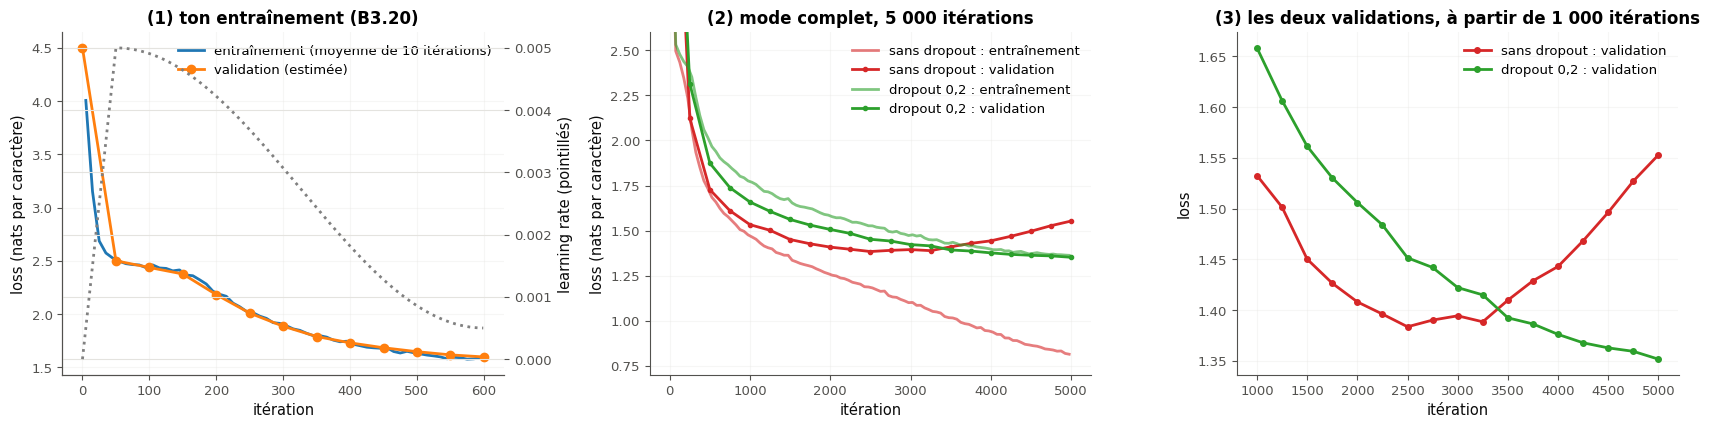

In [48]:
# Two full-mode trainings of the reference mini-GPT (5 000 iterations, precomputed by tools/chapters/history_chB3.py):
# the training loss averaged over blocks of 50 iterations, and the validation loss estimated every 250 iterations
FULL_21 = {"sans dropout": {"train_iter": [25, 75, 125, 175, 225, 275, 325, 375, 425, 475, 525, 575, 625, 675, 725, 775, 825, 875, 925, 975, 1025, 1075, 1125, 1175, 1225, 1275, 1325, 1375, 1425, 1475, 1525, 1575, 1625, 1675, 1725, 1775, 1825, 1875, 1925, 1975, 2025, 2075, 2125, 2175, 2225, 2275, 2325, 2375, 2425, 2475, 2525, 2575, 2625, 2675, 2725, 2775, 2825, 2875, 2925, 2975, 3025, 3075, 3125, 3175, 3225, 3275, 3325, 3375, 3425, 3475, 3525, 3575, 3625, 3675, 3725, 3775, 3825, 3875, 3925, 3975, 4025, 4075, 4125, 4175, 4225, 4275, 4325, 4375, 4425, 4475, 4525, 4575, 4625, 4675, 4725, 4775, 4825, 4875, 4925, 4975], "train": [3.293, 2.4954, 2.4343, 2.3467, 2.2342, 2.0625, 1.9344, 1.8512, 1.7769, 1.7332, 1.6843, 1.6581, 1.6232, 1.5951, 1.5773, 1.5545, 1.5317, 1.5054, 1.4958, 1.4762, 1.4643, 1.4519, 1.4312, 1.4143, 1.4046, 1.3983, 1.3785, 1.3718, 1.3632, 1.3629, 1.3351, 1.3269, 1.3175, 1.3111, 1.3055, 1.2992, 1.288, 1.2788, 1.2682, 1.2606, 1.2522, 1.2481, 1.2371, 1.2333, 1.2246, 1.2131, 1.2079, 1.2024, 1.1883, 1.1869, 1.1816, 1.172, 1.1626, 1.1642, 1.1394, 1.1316, 1.1293, 1.1182, 1.11, 1.1, 1.101, 1.0849, 1.0854, 1.0709, 1.0619, 1.0514, 1.0483, 1.042, 1.0229, 1.0167, 1.015, 1.0082, 0.9907, 0.9834, 0.9798, 0.97, 0.9597, 0.9622, 0.9454, 0.943, 0.9363, 0.9243, 0.9234, 0.9042, 0.9034, 0.8901, 0.8894, 0.8799, 0.8688, 0.8655, 0.8611, 0.8582, 0.8518, 0.8432, 0.8406, 0.8371, 0.8307, 0.8318, 0.8181, 0.8138], "val_iter": [0, 250, 500, 750, 1000, 1250, 1500, 1750, 2000, 2250, 2500, 2750, 3000, 3250, 3500, 3750, 4000, 4250, 4500, 4750, 5000], "val": [4.4998, 2.1229, 1.727, 1.6101, 1.5326, 1.5014, 1.4502, 1.4265, 1.4081, 1.3961, 1.3836, 1.3902, 1.3944, 1.3885, 1.4098, 1.4289, 1.443, 1.4683, 1.4963, 1.5271, 1.5529]}, "dropout 0,2": {"train_iter": [25, 75, 125, 175, 225, 275, 325, 375, 425, 475, 525, 575, 625, 675, 725, 775, 825, 875, 925, 975, 1025, 1075, 1125, 1175, 1225, 1275, 1325, 1375, 1425, 1475, 1525, 1575, 1625, 1675, 1725, 1775, 1825, 1875, 1925, 1975, 2025, 2075, 2125, 2175, 2225, 2275, 2325, 2375, 2425, 2475, 2525, 2575, 2625, 2675, 2725, 2775, 2825, 2875, 2925, 2975, 3025, 3075, 3125, 3175, 3225, 3275, 3325, 3375, 3425, 3475, 3525, 3575, 3625, 3675, 3725, 3775, 3825, 3875, 3925, 3975, 4025, 4075, 4125, 4175, 4225, 4275, 4325, 4375, 4425, 4475, 4525, 4575, 4625, 4675, 4725, 4775, 4825, 4875, 4925, 4975], "train": [3.3494, 2.5321, 2.4781, 2.4378, 2.4098, 2.352, 2.2399, 2.1385, 2.0601, 2.0157, 1.9663, 1.9389, 1.9033, 1.8821, 1.8655, 1.8441, 1.8255, 1.8016, 1.793, 1.7757, 1.7678, 1.7559, 1.7357, 1.7175, 1.7149, 1.705, 1.6891, 1.6771, 1.6717, 1.6773, 1.6532, 1.6407, 1.6334, 1.63, 1.6248, 1.6202, 1.6095, 1.5986, 1.5897, 1.5856, 1.5767, 1.571, 1.5712, 1.5652, 1.5561, 1.5459, 1.5461, 1.5415, 1.5343, 1.5266, 1.5261, 1.5187, 1.5152, 1.5128, 1.4954, 1.4915, 1.4958, 1.4844, 1.4802, 1.4724, 1.4765, 1.4696, 1.4729, 1.4585, 1.4498, 1.4479, 1.4493, 1.4403, 1.4301, 1.4292, 1.435, 1.4278, 1.4187, 1.4225, 1.4144, 1.4148, 1.4089, 1.4061, 1.4033, 1.3993, 1.3938, 1.3937, 1.395, 1.3868, 1.3876, 1.379, 1.3823, 1.3843, 1.3771, 1.3703, 1.3737, 1.3773, 1.3728, 1.3698, 1.3677, 1.3697, 1.3662, 1.3657, 1.3639, 1.3626], "val_iter": [0, 250, 500, 750, 1000, 1250, 1500, 1750, 2000, 2250, 2500, 2750, 3000, 3250, 3500, 3750, 4000, 4250, 4500, 4750, 5000], "val": [4.4998, 2.3145, 1.8738, 1.7378, 1.6583, 1.6064, 1.5614, 1.5303, 1.506, 1.4839, 1.4515, 1.442, 1.4222, 1.415, 1.3924, 1.3864, 1.3761, 1.3678, 1.3628, 1.3594, 1.3517]}}


def block_means_21(values, width):
    """(centres, means) of consecutive blocks of `width` values: a smoothed training curve."""
    values = np.asarray(values, dtype=float)
    n = len(values) // width
    means = values[:n * width].reshape(n, width).mean(axis=1)
    return (np.arange(n) * width + width / 2), means


fig_21, axes_21 = plt.subplots(1, 3, figsize=(17, 4.4))
ax = axes_21[0]
if CKPT is None:
    ax.text(0.5, 0.5, "en attente de ton entraînement (B3.20)", ha="center", va="center", transform=ax.transAxes)
else:
    h_21 = CKPT["history"]
    x_21, m_21 = block_means_21(h_21["train_loss"], 10)
    ax.plot(x_21, m_21, color="tab:blue", label="entraînement (moyenne de 10 itérations)")
    ax.plot(h_21["val_iter"], h_21["val_loss"], "o-", color="tab:orange", label="validation (estimée)")
    lr_ax = ax.twinx()
    lr_ax.plot(np.arange(len(h_21["lr"])), h_21["lr"], ":", color="gray")
    lr_ax.set_ylabel("learning rate (pointillés)")
    ax.legend(loc="upper right")
ax.set(title="(1) ton entraînement (B3.20)", xlabel="itération", ylabel="loss (nats par caractère)")
ax.grid(alpha=0.3)
for name, color in (("sans dropout", "tab:red"), ("dropout 0,2", "tab:green")):
    run = FULL_21[name]
    axes_21[1].plot(run["train_iter"], run["train"], color=color, alpha=0.6, label=f"{name} : entraînement")
    axes_21[1].plot(run["val_iter"], run["val"], "o-", color=color, ms=3, label=f"{name} : validation")
    later = [i for i, it in enumerate(run["val_iter"]) if it >= 1000]
    axes_21[2].plot([run["val_iter"][i] for i in later], [run["val"][i] for i in later], "o-", color=color, ms=4,
                    label=f"{name} : validation")
axes_21[1].set(title="(2) mode complet, 5 000 itérations", xlabel="itération", ylabel="loss (nats par caractère)",
               ylim=(0.7, 2.6))
axes_21[2].set(title="(3) les deux validations, à partir de 1 000 itérations", xlabel="itération", ylabel="loss")
for ax in axes_21[1:]:
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

In [49]:
vocab_21, fast_21, best_21, early_21, close_21 = 88, "A", 2500, False, True

In [50]:
wb.record("B3.21a", 88, mistakes={"c'est le vocabulaire du quiz Q10 : combien de caractères distincts a Holmes (la cellule des outils de la partie A le dit) ?": 65, "c'est le nombre d'ids de B3.17, padding compris : combien de caractères distincts le modèle prédit-il ?": 89, "c'est le vocabulaire de GPT-2 : ici, le modèle prédit des caractères": 50257, "la loss de départ n'est qu'à peu près log V : combien de caractères distincts le modèle prédit-il ?": 90, "on demande V, pas la loss": 4}, fractional="on demande un nombre de caractères, un entier")
wb.record("B3.21b", "A", mistakes={"regarde la courbe de validation du graphique 1 sur ses dernières itérations : remonte-t-elle ?": "B", "regarde la courbe d'entraînement du graphique 1 : saute-t-elle, ou diverge-t-elle ?": "C"})
wb.record("B3.21c", 2500, mistakes={"graphique 3 : la courbe rouge (sans dropout) est-elle à son plus bas vers 1 000 itérations ?": 1000, "graphique 3 : où la courbe rouge (sans dropout) atteint-elle son plus bas ?": 4000, "graphique 3 : la courbe rouge (sans dropout) finit-elle à son plus bas ?": 5000}, fractional="choisis l'une des quatre itérations proposées", choices=[1000, 2500, 4000, 5000])
wb.record("B3.21d", False, mistakes={"graphique 3 : compare le point le plus bas de la courbe rouge à la fin de la courbe verte": True})
wb.record("B3.21e", True, mistakes={"graphique 2 : à 5 000 itérations, mesure l'écart entre les deux courbes vertes (entraînement et validation avec dropout)": False})

WB_ANSWER {"fractional": "on demande un nombre de caractères, un entier", "hash": "74cd4dba45f76d0ef8f61254c3fa638d7034c266923c03b085cfd75cd6b77969", "id": "B3.21a", "kind": "int", "magnitude": 1, "mistakes": {"2560a6a2fbedffecd7cdea128304005baccd5b7e664fc949416cd096add17190": "on demande V, pas la loss", "ab27a7084130915c29f610aeed854c41d115b56252b143aa908edf5fb89c0694": "c'est le nombre d'ids de B3.17, padding compris : combien de caractères distincts le modèle prédit-il ?", "bbb52c64194e3708fd6b909a5da33959570e48a943a2d423192b2df945f86dab": "c'est le vocabulaire de GPT-2 : ici, le modèle prédit des caractères", "c6c092c25bd59f1332b971aa7dde68a330455e24d132c228d6bb8e571f5e3e5e": "c'est le vocabulaire du quiz Q10 : combien de caractères distincts a Holmes (la cellule des outils de la partie A le dit) ?", "dda1e5d97cba3635b93697d5e6596f2b66ede12b3021936cf7f9ee2d1c7e2c70": "la loss de départ n'est qu'à peu près log V : combien de caractères distincts le modèle prédit-il ?"}, "sign": 1}


### Ex B3.22 — Prédire : le mini-GPT de Holmes amorcé avec une phrase de Verne 🔮 ★ ⏱️ 10 min
**Objectif :** prédire ce que fait un modèle de langue entraîné sur de l'anglais quand on lui donne un prompt en français.  
**Prérequis :** Ex B3.20 · fiche §203.8 (« La loss et la perplexité »), §203.9 (« La boucle de génération ») · ch. 22 (Holmes et Verne) · **Fil rouge :** Holmes/Verne · **Parcours :** C

Ton mini-GPT n'a lu que Holmes, en anglais. La cellule suivante prépare `PROMPT_FR_22`, une phrase de Verne (*Le Tour du monde en quatre-vingts jours*, ch. 22), et `FRENCH_22`, toute la validation de Verne, écrites avec les caractères de Holmes (`to_holmes_22` : l'apostrophe et les guillemets deviennent ceux de Holmes, un accent que Holmes n'emploie jamais disparaît, ê → e, ç → c). `languages_22(texte)` compte les mots anglais (ceux que seul le texte d'entraînement de Holmes contient) et les mots français (ceux que seul celui de Verne contient) d'un texte.

L'expérience tire 10 continuations de 120 caractères après le prompt français (température 1, `wbgpt.generate`), et 10 après un prompt anglais de même style, pour comparer ; puis elle mesure la loss par caractère de ton modèle sur toute la validation de Verne. **Avant d'exécuter**, écris tes deux prédictions :
- a) `french_22` : `True` ou `False` : sur les 10 continuations du prompt français, **plus de la moitié** ont-elles plus de mots français que de mots anglais ?
- b) `uniform_22` : `True` ou `False` : sur le texte français de Verne, la loss par caractère de ton modèle est-elle **plus basse** que celle d'une prédiction uniforme sur les 88 caractères ($\log 88$ nats par caractère) ?

La cellule d'expérience n'affiche rien tant que tes deux prédictions ne sont pas écrites ; elle les vérifie à la fin.

In [51]:
VERNE = wbgpt.char_data("verne")             # Verne, « Le Tour du monde en quatre-vingts jours » (B2, ch. 22)
_TO_ENGLISH_22 = {"'": "’", "«": "“", "»": "”"}


def to_holmes_22(text):
    """The text in the vocabulary of Holmes: the apostrophe and the French quotes become those of Holmes, an accented
    letter that Holmes never uses loses its accent (ê -> e, ç -> c), any other unknown character is dropped."""
    out = []
    for ch in text:
        ch = _TO_ENGLISH_22.get(ch, ch)
        if ch not in DATA.stoi:
            ch = unicodedata.normalize("NFD", ch)[0]
        if ch in DATA.stoi:
            out.append(ch)
    return "".join(out)


PROMPT_FR_22 = to_holmes_22("Toutefois le vent ne fraîchit pas autant qu'on aurait pu le craindre. Ce ne fut pas un de "
                            "ces ouragans qui passent avec une vitesse de quatre-vingt-dix milles à l'heure. Il ")
PROMPT_EN_22 = ("“You have erred, perhaps,” he observed, taking up a glowing cinder with the tongs and lighting with it "
                "the long cherry-wood pipe. He ")
FRENCH_22 = DATA.encode(to_holmes_22(VERNE.val_text))      # the validation of Verne, in the vocabulary of Holmes
_words_h = set(re.findall(r"[^\W\d_]+", DATA.train_text.lower()))
_words_v = set(re.findall(r"[^\W\d_]+", to_holmes_22(VERNE.train_text).lower()))
ENGLISH_ONLY_22, FRENCH_ONLY_22 = _words_h - _words_v, _words_v - _words_h   # words seen in one novel only


def languages_22(text):
    """(English words, French words) of a text: the words seen in the training text of Holmes only, and those seen
    in the training text of Verne only (a word of both novels, such as « a » or « Fogg », counts for neither)."""
    words = re.findall(r"[^\W\d_]+", text.lower())
    return sum(w in ENGLISH_ONLY_22 for w in words), sum(w in FRENCH_ONLY_22 for w in words)


@torch.no_grad()
def loss_by_position_22(model, ids, block_size=128, n_windows=64):
    """The mean loss (nats per character) of `model` at the positions 0 to 15, 16 to 63 and 64 to 127 of
    `n_windows` consecutive windows of `ids`: how the loss changes as the context of the window grows."""
    x = torch.stack([ids[i * block_size:(i + 1) * block_size] for i in range(n_windows)])
    y = torch.stack([ids[i * block_size + 1:(i + 1) * block_size + 1] for i in range(n_windows)])
    nll = F.cross_entropy(model(x).flatten(0, 1), y.flatten(), reduction="none").view(n_windows, -1)
    return [nll[:, a:b].mean().item() for a, b in ((0, 16), (16, 64), (64, block_size))]


print(f"amorce française ({len(PROMPT_FR_22)} caractères) : {PROMPT_FR_22!r}")
print(f"Verne en caractères de Holmes : {len(FRENCH_22):_} caractères de validation ; mots propres à Holmes "
      f"{len(ENGLISH_ONLY_22):_}, propres à Verne {len(FRENCH_ONLY_22):_}.".replace("_", " "))

amorce française (173 caractères) : 'Toutefois le vent ne fraichit pas autant qu’on aurait pu le craindre. Ce ne fut pas un de ces ouragans qui passent avec une vitesse de quatre-vingt-dix milles à l’heure. Il '
Verne en caractères de Holmes : 42 203 caractères de validation ; mots propres à Holmes 6 881, propres à Verne 7 873.


In [52]:
french_22, uniform_22 = False, True

In [53]:
wb.record("B3.22a", False, mistakes={"compte les continuations où les mots français l'emportent, dans la ligne affichée pour le prompt français": True})
wb.record("B3.22b", True, mistakes={"compare la loss sur Verne à celle d'une prédiction uniforme, affichées l'une à côté de l'autre": False})

WB_ANSWER {"hash": "10b8567922f7de7642c0b4324e78f14de87c3482cf6a0f27956759b840d906ec", "id": "B3.22a", "kind": "bool", "mistakes": {"9013a7c956fb653f9a8ad854a365cc3dab6581ca7a756173983a48ce5412d80b": "compte les continuations où les mots français l'emportent, dans la ligne affichée pour le prompt français"}}
📝 Ex B3.22a : réponse enregistrée (bool).
WB_ANSWER {"hash": "08cfe4551c72291a74c4ae60b9c7825fc15e5732395f8011cd0f747ae3874f9d", "id": "B3.22b", "kind": "bool", "mistakes": {"30ca66ffa8ad6d709b87702e129af686600d6c8e8756a02579ac7aebfe168115": "compare la loss sur Verne à celle d'une prédiction uniforme, affichées l'une à côté de l'autre"}}
📝 Ex B3.22b : réponse enregistrée (bool).


In [54]:
if any(answer is ... or answer is None for answer in [french_22, uniform_22]):
    print("⏳ Ex B3.22 : écris d'abord tes deux prédictions dans la cellule précédente.")
else:
    with checked("B3.22"):
        need_gpt("B3.22")
        rows_22 = {}
        for name, prompt in (("amorce française", PROMPT_FR_22), ("amorce anglaise (témoin)", PROMPT_EN_22)):
            start_22 = DATA.encode(prompt)[None].repeat(10, 1)                       # 10 copies, 10 different draws
            out_22 = wbgpt.generate(GPT, start_22, 120, temperature=1.0, generator=torch.Generator().manual_seed(22))
            texts_22 = [DATA.decode(row[len(prompt):]) for row in out_22]
            counts_22 = [languages_22(t) for t in texts_22]
            rows_22[name] = sum(fr_ > en for en, fr_ in counts_22)
            print(f"{name} : {rows_22[name]} continuation(s) sur 10 ont plus de mots français que de mots anglais "
                  f"(en moyenne {fr(np.mean([c[0] for c in counts_22]), 1)} mots anglais et "
                  f"{fr(np.mean([c[1] for c in counts_22]), 1)} mots français par continuation). Les deux premières :")
            for t in texts_22[:2]:
                print("   ", repr(t[:160]))
        fr_loss_22 = wbgpt.char_loss(GPT, FRENCH_22)
        en_loss_22 = (CKPT.get("extra") or {}).get("char_loss") or wbgpt.char_loss(GPT, DATA.val_ids)
        print(f"\nloss sur toute la validation : Holmes {fr(en_loss_22, 3)}, Verne {fr(fr_loss_22, 3)} nats par caractère "
              f"(uniforme sur les {len(DATA.itos)} caractères : {fr(math.log(len(DATA.itos)), 3)})")
        for name, ids in (("Holmes", DATA.val_ids), ("Verne", FRENCH_22)):
            a, b, c = loss_by_position_22(GPT, ids)
            print(f"{name:>6} : loss aux positions 0-15 {fr(a, 3)}, 16-63 {fr(b, 3)}, 64-127 {fr(c, 3)}")
        wb.check("B3.22a", french_22)
        wb.check("B3.22b", uniform_22)

amorce française : 0 continuation(s) sur 10 ont plus de mots français que de mots anglais (en moyenne 10,4 mots anglais et 0,2 mots français par continuation). Les deux premières :
    'had\nfinder that I hardreet the bsake oven eet from sogring.\n\n“Oh, there and\nI take cerect town.”—said I inso that. But W'
    'thought!” I doorness it was\nI problity visious that dogulars lying, by that hour are\ntrouses of the pasticurithering and'


amorce anglaise (témoin) : 0 continuation(s) sur 10 ont plus de mots français que de mots anglais (en moyenne 10,8 mots anglais et 0,4 mots français par continuation). Les deux premières :
    'had\nfindlow, and had trade the bsake oven eet frizes.”\n\n“Then a quitterning\nhand thest he have with\nwithink it, Mr. Her '
    'never, and in\nthere of the cloppened our more the padent sundly,” saved\npal pul and through angrance whites. He finad no'



loss sur toute la validation : Holmes 1,590, Verne 3,467 nats par caractère (uniforme sur les 88 caractères : 4,477)
Holmes : loss aux positions 0-15 1,786, 16-63 1,665, 64-127 1,600


 Verne : loss aux positions 0-15 3,496, 16-63 3,347, 64-127 3,523
✅ Ex B3.22a : Bravo !
✅ Ex B3.22b : Exact !


Dans tes notes : pour chaque prédiction ratée, qu'est-ce qui t'a trompé ? Compare les continuations des deux prompts : en quoi diffèrent-elles, et à partir de combien de caractères ? Qu'est-ce qu'un modèle de Holmes peut savoir qui vaille aussi pour un texte français ? Compare, dans le tableau des positions, la loss du début et de la fin d'une fenêtre sur Holmes, puis sur Verne : que te dit cet écart sur ce que le modèle fait de son contexte ?

### Ex B3.23 — Générer vite : le KV cache, et le gain de vitesse mesuré selon la longueur 📦 ★★★ ⏱️ 45 min
**Objectif :** écrire la génération gloutonne du mini-GPT sans cache puis avec un KV cache, vérifier qu'elles donnent les mêmes tokens, et mesurer le gain.  
**Prérequis :** Ex B3.20 · fiche §203.9 (« Pourquoi c'est lent sans cache », « Le KV cache ») · 🧠 Q11 · 🧮 B3.8 · **Fil rouge :** Holmes · **Parcours :** R, C

**Contrat**
- `generate_23(model, idx, n_new)` : la génération **gloutonne** sans cache (fiche §203.9) : `idx` (N, T0) int64 → un nouveau tenseur (N, T0 + n_new), `idx` suivi de `n_new` tokens ; à chaque pas, les logits de la **dernière** position, calculés sur les `model.block_size` derniers tokens de la séquence, et le token le plus probable (l'argmax) ; sans gradient, le modèle en mode eval.
- `generate_cached_23(model, idx, n_new, n_head)` : **les mêmes tokens**, avec un KV cache :
  - un **prefill** : le prompt passe une fois, en entier, dans les blocs, et remplit pour chaque bloc les clés et les valeurs de ses tokens, de forme (N, n_head, T0, d_h) ;
  - puis un token par pas : **seul** le nouveau token passe dans le modèle, avec l'embedding de **sa** position ; sa clé et sa valeur s'ajoutent au cache de chaque bloc, et sa requête regarde tout le cache ;
  - écrit avec les sous-modules du modèle, aux noms de B3.19 : `tok_emb`, `pos_emb`, puis pour chaque bloc `ln1`, `attn.qkv`, `attn.proj`, `ln2`, `mlp`, enfin `ln_f` et `head` ; jamais `model(...)`, un bloc ou un module d'attention appelé en entier : ils recalculeraient toute la séquence ;
  - `n_head` donne le nombre de têtes (ton module n'a pas à l'exposer) ; `ValueError` si `T0 + n_new > model.block_size` : au-delà, il n'y a plus de position apprise.

La cellule de vérification essaie tes deux fonctions sur un petit mini-GPT de `wb.gpt` (2 blocs, 2 têtes, un contexte de 32 tokens) : `generate_23` contre `wbgpt.generate`, la génération sans cache de référence (40 tokens après 5 : le contexte doit être coupé), puis `generate_cached_23` jusqu'au contexte plein, avec des *hooks* de PyTorch (`register_forward_hook`) qui comptent les tokens que voit chaque `attn.qkv` et vérifient que ni le modèle, ni un bloc, ni un module d'attention ne sont appelés ; enfin un refus. La cellule suivante mesure, sur **ton** mini-GPT et 4 prompts de 32 caractères, le temps des deux générations pour 16 à 96 nouveaux tokens (le meilleur de trois essais), vérifie que les tokens sont les mêmes et trace les temps. Un temps est une mesure, pas une réponse : il dépend de la machine.

Dans tes notes : le gain grandit-il avec le nombre de tokens générés, et pourquoi reste-t-il modeste ici (pense au contexte de 128 et à ce que coûte un appel de module sur CPU) ? Combien de mémoire ton cache occupe-t-il à 128 tokens pour les 4 prompts (🧮 B3.8) ? Pourquoi le token **tiré au dernier pas** n'a-t-il pas besoin de passer dans le modèle ? Avec un tirage aléatoire au lieu de l'argmax, que faudrait-il pour que les deux générations restent identiques ?

In [55]:
@torch.no_grad()
def generate_23(model, idx, n_new):
    """Greedy generation WITHOUT cache (contract of Ex B3.23): idx (N, T0) int64 -> (N, T0 + n_new)."""
    model.eval()
    for _ in range(n_new):
        logits = model(idx[:, -model.block_size:])[:, -1]           # the whole window again, at every step
        idx = torch.cat([idx, logits.argmax(dim=-1, keepdim=True)], dim=1)
    return idx


@torch.no_grad()
def generate_cached_23(model, idx, n_new, n_head):
    """The same tokens as generate_23, with a KV cache (contract of Ex B3.23); T0 + n_new <= model.block_size."""
    N, T0 = idx.shape
    if T0 + n_new > model.block_size:
        raise ValueError(f"{T0} + {n_new} tokens: more than block_size = {model.block_size} learned positions")
    model.eval()
    cache = [None] * len(model.blocks)                                # (keys, values) of each block, (N, H, t, d_h)

    def forward_new(tokens, start):
        """Logits of the last new token; the keys and values of the new tokens are appended to the cache."""
        T = tokens.shape[1]
        x = model.tok_emb(tokens) + model.pos_emb(torch.arange(start, start + T, device=tokens.device))
        for i, block in enumerate(model.blocks):
            D = x.shape[-1]
            q, k, v = block.attn.qkv(block.ln1(x)).split(D, dim=2)
            q, k, v = (t.view(N, T, n_head, D // n_head).transpose(1, 2) for t in (q, k, v))
            if cache[i] is not None:
                k, v = torch.cat([cache[i][0], k], dim=2), torch.cat([cache[i][1], v], dim=2)
            cache[i] = (k, v)
            S = k.shape[2]                                            # the prompt: causal; then 1 query, every key
            mask = torch.ones(T, S, dtype=torch.bool, device=x.device).tril(diagonal=S - T)
            y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask)
            x = x + block.attn.proj(y.transpose(1, 2).reshape(N, T, D))
            x = x + block.mlp(block.ln2(x))
        return model.head(model.ln_f(x[:, -1]))

    out = [idx]
    logits = forward_new(idx, 0)                                      # the prefill: the whole prompt at once
    for j in range(n_new):
        nxt = logits.argmax(dim=-1, keepdim=True)
        out.append(nxt)
        if j < n_new - 1:
            logits = forward_new(nxt, T0 + j)                         # one token, at its position
    return torch.cat(out, dim=1)


cache_ok_23 = False
with checked("B3.23"):
    # 1. a small model of wb.gpt (not your B3.19), with large weights: well-separated logits (no near tie), and
    #    positions and attention that change the tokens
    torch.manual_seed(23)
    small_23 = wbgpt.ReferenceGPT(vocab_size=88, block_size=32, n_layer=2, n_head=2, d_model=16).eval()
    with torch.no_grad():
        for module in small_23.modules():
            if isinstance(module, (nn.Linear, nn.Embedding)):
                nn.init.normal_(module.weight, std=0.5)
    prompt_23 = torch.randint(0, 88, (3, 5), generator=torch.Generator().manual_seed(23))
    plain_23 = generate_23(small_23, prompt_23.clone(), 40)
    if not returned("B3.23", "generate_23", plain_23):
        raise StopCheck
    want_23 = wbgpt.generate(small_23, prompt_23.clone(), 40)
    plain_ok_23 = isinstance(plain_23, torch.Tensor) and tuple(plain_23.shape) == (3, 45) and torch.equal(plain_23, want_23)
    verdict("B3.23", plain_ok_23,
            "generate_23 : 40 tokens gloutons après 5, le contexte coupé aux 32 derniers tokens (block_size).",
            f"generate_23(model, idx (3, 5), 40) doit rendre les ids (3, 45) du tirage glouton (l'argmax des logits de la "
            f"dernière position, sur les block_size = 32 derniers tokens) ; reçu "
            f"{tuple(plain_23.shape) if isinstance(plain_23, torch.Tensor) else type(plain_23).__name__}"
            + (", d'autres tokens" if isinstance(plain_23, torch.Tensor) and tuple(plain_23.shape) == (3, 45) else "") + ".")
    # 2. the cache: the same tokens, and a cache really used (qkv sees the prompt once, then one token at a time)
    calls_23, hooks_23 = {"qkv": [], "whole": 0}, []
    for block in small_23.blocks:
        hooks_23.append(block.attn.qkv.register_forward_hook(lambda m, inp, out: calls_23["qkv"].append(inp[0].shape[1])))
        for module in (block, block.attn):
            hooks_23.append(module.register_forward_hook(lambda m, inp, out: calls_23.__setitem__("whole", calls_23["whole"] + 1)))
    hooks_23.append(small_23.register_forward_hook(lambda m, inp, out: calls_23.__setitem__("whole", calls_23["whole"] + 1)))
    try:
        cached_23 = generate_cached_23(small_23, prompt_23.clone(), 27, 2)
    finally:
        for hook in hooks_23:
            hook.remove()
    if not returned("B3.23", "generate_cached_23", cached_23):
        raise StopCheck
    want_c_23 = wbgpt.generate(small_23, prompt_23.clone(), 27)
    same_23 = isinstance(cached_23, torch.Tensor) and tuple(cached_23.shape) == (3, 32) and torch.equal(cached_23, want_c_23)
    verdict("B3.23", same_23, "generate_cached_23 : les mêmes 27 tokens que sans cache (contexte plein : 32 tokens).",
            "generate_cached_23(model, idx (3, 5), 27, 2) doit rendre les mêmes ids (3, 32) que le tirage glouton sans "
            "cache ; reçu " + (f"{tuple(cached_23.shape)}" if isinstance(cached_23, torch.Tensor) else type(cached_23).__name__)
            + (", d'autres tokens : vérifie la position de chaque nouveau token, le masque du prefill et de chaque pas, et ce que chaque bloc ajoute au chemin résiduel"
               if isinstance(cached_23, torch.Tensor) and tuple(cached_23.shape) == (3, 32) else "") + ".")
    want_calls_23 = [(sorted([5] * 2 + [1] * 2 * steps)) for steps in (26, 27)]   # per block: the prompt, then 1 token
    used_23 = calls_23["whole"] == 0 and sorted(calls_23["qkv"]) in want_calls_23     # per step (the last one optional)
    verdict("B3.23", used_23,
            "le cache sert : chaque attn.qkv voit le prompt une fois (5 tokens), puis un seul token par pas ; le modèle, "
            "les blocs et les modules d'attention ne sont jamais appelés sur la séquence.",
            f"avec un KV cache, chaque attn.qkv doit voir le prompt une fois (5 tokens), puis 1 token à chacun des 26 pas "
            f"suivants, et ni le modèle, ni un bloc, ni un module d'attention ne doivent être appelés ; vu {calls_23['whole']} "
            f"appel(s) de modèle, de bloc ou d'attention, et des appels de qkv sur {sorted(set(calls_23['qkv']))} tokens.")
    refuses("B3.23", "5 + 28 tokens pour un contexte de 32", lambda: generate_cached_23(small_23, prompt_23, 28, 2))
    cache_ok_23 = plain_ok_23 and same_23 and used_23

✅ Ex B3.23 : generate_23 : 40 tokens gloutons après 5, le contexte coupé aux 32 derniers tokens (block_size).
✅ Ex B3.23 : generate_cached_23 : les mêmes 27 tokens que sans cache (contexte plein : 32 tokens).
✅ Ex B3.23 : le cache sert : chaque attn.qkv voit le prompt une fois (5 tokens), puis un seul token par pas ; le modèle, les blocs et les modules d'attention ne sont jamais appelés sur la séquence.
✅ Ex B3.23 : 5 + 28 tokens pour un contexte de 32 : ValueError levée (5 + 28 tokens: more than block_size = 32 learned positions).


 tokens générés   sans cache   avec cache   gain  mêmes tokens
             16        64 ms        30 ms    2,1  True
             32       151 ms        71 ms    2,1  True
             64       374 ms       121 ms    3,1  True
             96       638 ms       193 ms    3,3  True
✅ Ex B3.23 : avec et sans cache, les mêmes tokens à toutes les longueurs.
✅ Ex B3.23 : à 96 tokens, le cache va 3,3 fois plus vite (une mesure : elle dépend de la machine).


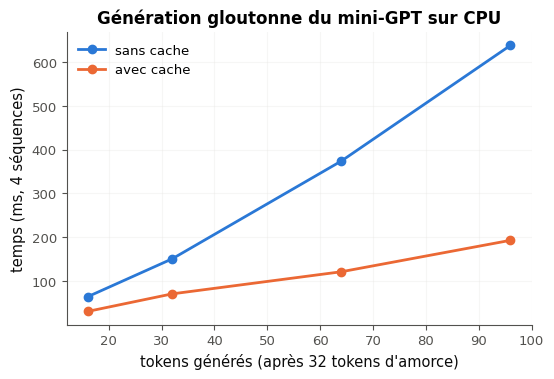

génération gloutonne, amorce 0 : 'ly, at the expense of six shilling of the street of the stand the\nstation the street of the strange of the station. I have the s'


In [56]:
with checked("B3.23"):
    need_gpt("B3.23")
    if not cache_ok_23:
        print("⏳ Ex B3.23 : la mesure attend les contrôles de la cellule précédente.")
        raise StopCheck
    starts_23 = DATA.val_ids[1000:1000 + 4 * 32].view(4, 32)                 # 4 prompts of 32 characters
    rows_23 = []
    for n_new in (16, 32, 64, 96):
        timings_23 = {}
        for name, fn in (("sans cache", lambda: generate_23(GPT, starts_23.clone(), n_new)),
                         ("avec cache", lambda: generate_cached_23(GPT, starts_23.clone(), n_new, N_HEAD))):
            best_23, ids_23 = math.inf, None
            for _ in range(3):                                                # the best of three runs
                t0_23 = time.perf_counter()
                ids_23 = fn()
                best_23 = min(best_23, time.perf_counter() - t0_23)
            timings_23[name] = (best_23, ids_23)
        same_ids_23 = torch.equal(timings_23["sans cache"][1], timings_23["avec cache"][1])
        rows_23.append((n_new, timings_23["sans cache"][0], timings_23["avec cache"][0], same_ids_23))
    print(f"{'tokens générés':>15} {'sans cache':>12} {'avec cache':>12} {'gain':>6}  mêmes tokens")
    for n_new, plain, cached, same_ids in rows_23:
        print(f"{n_new:>15} {fr(1000 * plain, 0) + ' ms':>12} {fr(1000 * cached, 0) + ' ms':>12} "
              f"{fr(plain / cached, 1):>6}  {same_ids}")
    verdict("B3.23", all(r[3] for r in rows_23), "avec et sans cache, les mêmes tokens à toutes les longueurs.",
            "à une longueur au moins, les tokens générés avec et sans cache diffèrent : relis les contrôles ci-dessus.")
    verdict("B3.23", rows_23[-1][1] > rows_23[-1][2],
            f"à {rows_23[-1][0]} tokens, le cache va {fr(rows_23[-1][1] / rows_23[-1][2], 1)} fois plus vite (une mesure : "
            "elle dépend de la machine).",
            f"à {rows_23[-1][0]} tokens, la génération avec cache n'est pas plus rapide : la machine est-elle chargée ? "
            "Relance la cellule.")
    plt.figure(figsize=(6, 3.8))
    plt.plot([r[0] for r in rows_23], [1000 * r[1] for r in rows_23], "o-", label="sans cache")
    plt.plot([r[0] for r in rows_23], [1000 * r[2] for r in rows_23], "o-", label="avec cache")
    plt.xlabel("tokens générés (après 32 tokens d'amorce)")
    plt.ylabel("temps (ms, 4 séquences)")
    plt.title("Génération gloutonne du mini-GPT sur CPU")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()
    print("génération gloutonne, amorce 0 :", repr(DATA.decode(timings_23["avec cache"][1][0])))

### Ex B3.24 — Les cartes d'attention de chaque tête sur une phrase de Holmes 📈 ★★ ⏱️ 20 min
**Objectif :** lire les cartes d'attention des 16 têtes du mini-GPT et vérifier sur leurs poids ce que l'on croit y voir.  
**Prérequis :** Ex B3.20 · fiche §203.3 (« Le masque causal »), §203.4 (« Plusieurs questions à la fois ») · Ex B3.17 (une carte d'attention) · **Fil rouge :** Holmes · **Parcours :** C

La cellule suivante trace les cartes d'attention des 16 têtes de ton mini-GPT (4 blocs × 4 têtes) sur une phrase de Holmes : une ligne par requête, une colonne par clé, du violet (poids 0) au jaune (poids 1), les caractères sur les axes (␣ pour un espace). Le module d'attention ne rend pas ses poids (il appelle SDPA) : `attention_maps_24(model, ids)` les recalcule à partir de l'entrée de chaque attention, de `attn.qkv`, de l'échelle $1/\sqrt{d_h}$ et du masque causal.

Écris, pour chaque affirmation, la tête qui la vérifie le mieux, un couple `(bloc, tête)` d'entiers comptés à partir de 0 :
- a) `previous_24` : la tête qui regarde le plus le **caractère précédent** ;
- b) `spaces_24` : la tête qui regarde le plus les **espaces** (des colonnes claires sous chaque espace) ;
- c) `spread_24` : la tête dont l'attention est la plus **étalée** sur les clés (la moins concentrée).

La cellule de vérification mesure chaque affirmation sur les poids de 16 fenêtres de 128 caractères de la validation : a) le poids moyen de la clé $i - 1$ pour la requête $i$ ; b) le poids total des clés qui sont des espaces, sur les requêtes 32 à 127 ; c) l'entropie moyenne d'une ligne de poids, $-\sum_j \alpha_{ij} \ln \alpha_{ij}$, sur les requêtes 32 à 127. Ta tête est acceptée si sa mesure atteint au moins 90 % de la plus forte des 16. Ton modèle n'est pas celui d'un autre : les têtes qui portent ces motifs changent d'un entraînement à l'autre, c'est pourquoi la cellule les mesure sur tes poids au lieu de comparer à une réponse.

Dans tes notes : décris deux autres motifs que tu vois (deux caractères en arrière, la ponctuation, les majuscules…) et vérifie-les sur les poids, avec un calcul du même genre. Les têtes du bloc 0 et celles du bloc 3 se ressemblent-elles ? Pourquoi une tête « caractère précédent » est-elle utile à un modèle de caractères, et pourquoi aucune carte n'a-t-elle de poids au-dessus de la diagonale ?

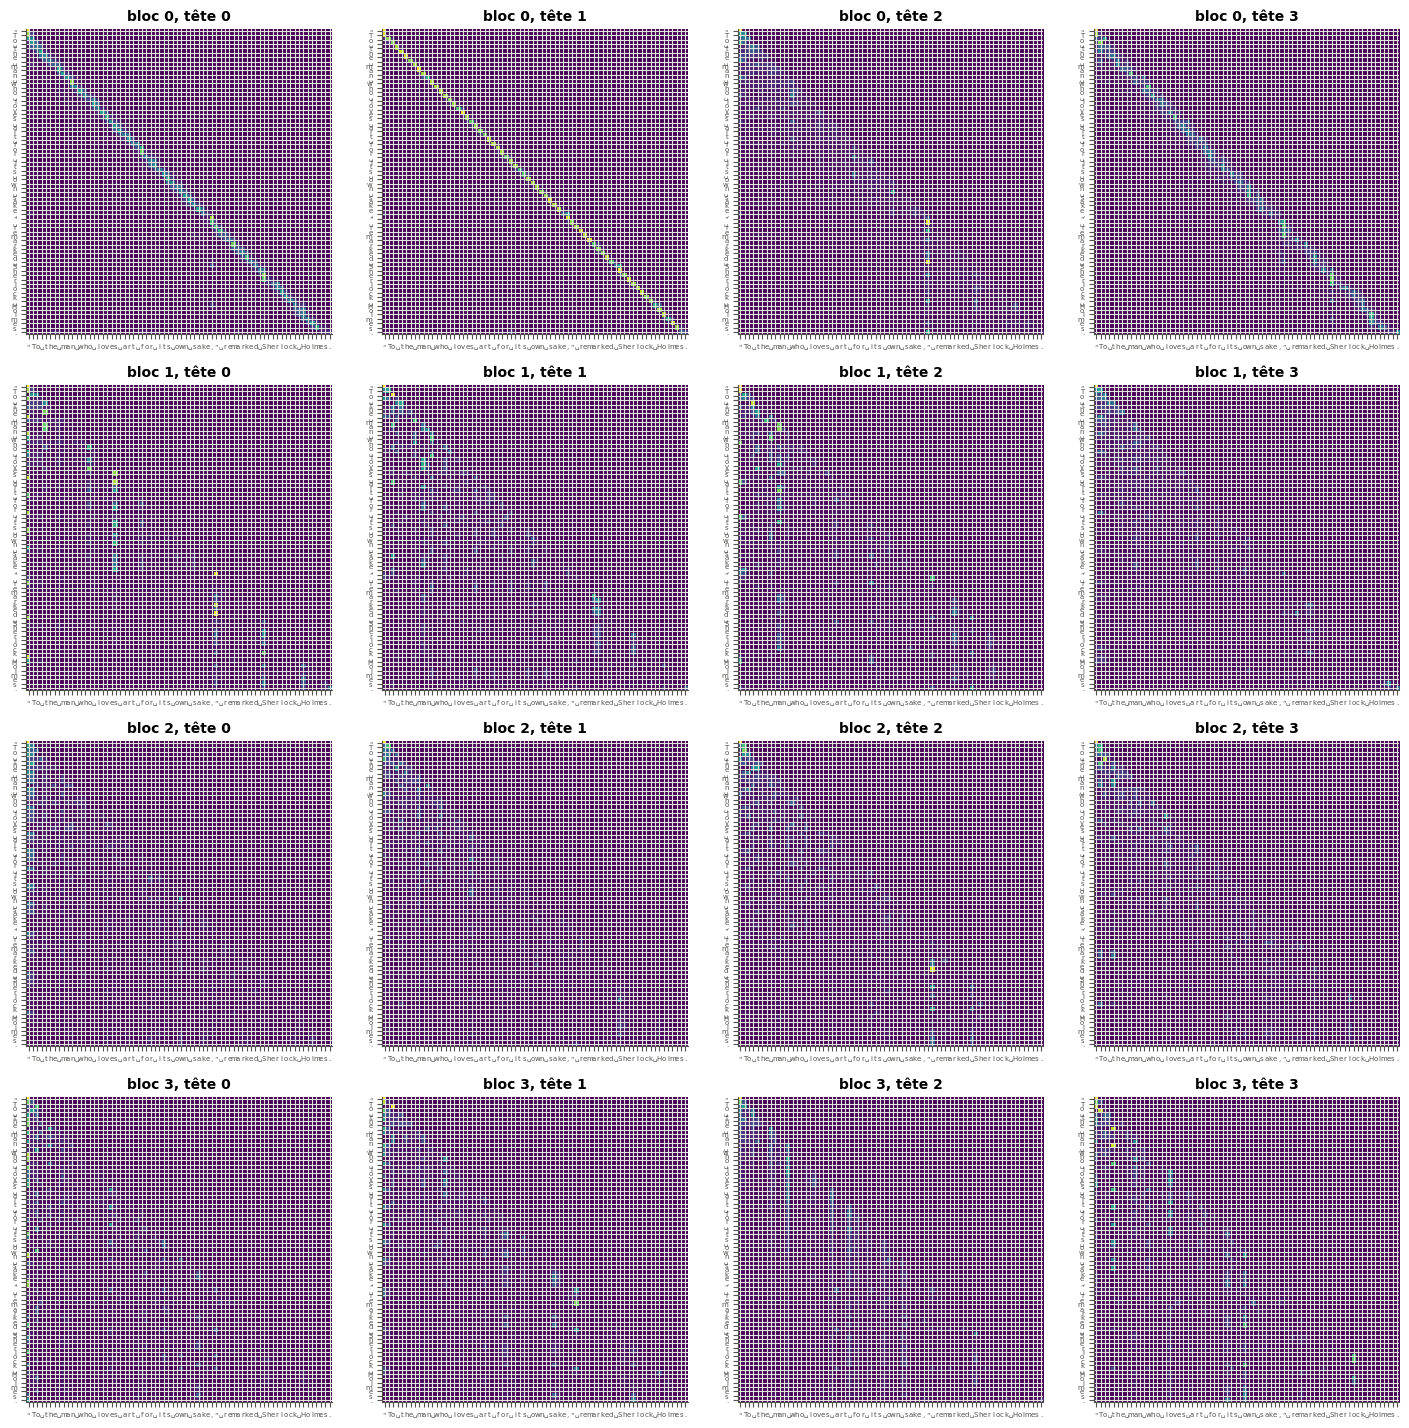

In [57]:
SENTENCE_24 = "“To the man who loves art for its own sake,” remarked Sherlock Holmes."
WINDOWS_24 = DATA.val_ids[:16 * 128].view(16, 128)        # 16 windows of the validation, for the measures
SPACES_24 = (WINDOWS_24 == DATA.stoi[" "]).float()         # 1 on the keys that are a space


@torch.no_grad()
def attention_maps_24(model, ids, n_head=N_HEAD):
    """The attention weights of every head of every block: ids (N, T) -> (N, n_layer, n_head, T, T). The attention
    module calls SDPA, which does not return its weights: they are recomputed from the input of each attention (the
    output of ln1, read by a hook), attn.qkv (queries, keys), the scale 1/sqrt(d_h) and the causal mask."""
    inputs, hooks = {}, []
    for i, block in enumerate(model.blocks):
        hooks.append(block.ln1.register_forward_hook(lambda m, inp, out, i=i: inputs.__setitem__(i, out)))
    try:
        model.eval()(ids)
    finally:
        for hook in hooks:
            hook.remove()
    N, T = ids.shape
    causal = torch.ones(T, T, dtype=torch.bool).tril()
    maps = []
    for i, block in enumerate(model.blocks):
        D = inputs[i].shape[-1]
        q, k, _ = block.attn.qkv(inputs[i]).split(D, dim=2)
        q, k = (t.view(N, T, n_head, D // n_head).transpose(1, 2) for t in (q, k))
        scores = (q @ k.transpose(-2, -1)) / math.sqrt(D // n_head)
        maps.append(torch.softmax(scores.masked_fill(~causal, float("-inf")), dim=-1))
    return torch.stack(maps, dim=1)


def plot_maps_24(maps, text):
    """The (n_layer, n_head) grid of the attention maps of one sequence: a row per query, a column per key."""
    n_layer, n_head = maps.shape[:2]
    fig, axes = plt.subplots(n_layer, n_head, figsize=(3.6 * n_head, 3.6 * n_layer))
    chars = [c if c != " " else "␣" for c in text]
    for l in range(n_layer):
        for h in range(n_head):
            ax = axes[l, h]
            ax.imshow(maps[l, h].numpy(), cmap="viridis", vmin=0, vmax=1)
            ax.set_title(f"bloc {l}, tête {h}", fontsize=10)
            ax.set_xticks(range(len(chars)))
            ax.set_xticklabels(chars, fontsize=5)
            ax.set_yticks(range(len(chars)))
            ax.set_yticklabels(chars, fontsize=5)
    plt.tight_layout()
    plt.show()


if GPT is None:
    print("⏳ Ex B3.24 : les cartes attendent ton mini-GPT entraîné (B3.20), ou REFERENCE_FALLBACK = True dans la cellule "
          "des outils de la partie C.")
else:
    ids_24 = DATA.encode(SENTENCE_24)[None]
    plot_maps_24(attention_maps_24(GPT, ids_24)[0], SENTENCE_24)

In [58]:
previous_24, spaces_24, spread_24 = (0, 1), (3, 2), (2, 1)   # read on the maps of the model of the solution


with checked("B3.24"):
    need_gpt("B3.24")
    maps_24 = attention_maps_24(GPT, WINDOWS_24)                             # (16, n_layer, H, 128, 128)
    rows_24 = torch.arange(1, 128)
    scores_24 = {
        "previous": maps_24[..., rows_24, rows_24 - 1].mean(dim=(0, -1)),     # (n_layer, H): weight on j = i - 1
        "spaces": (maps_24 * SPACES_24[:, None, None, None, :]).sum(-1)[..., 32:].mean(dim=(0, -1)),   # on spaces
        "spread": -(maps_24 * maps_24.clamp_min(1e-12).log()).sum(-1)[..., 32:].mean(dim=(0, -1)),   # entropy, rows >= 32
    }
    n_layer_24, n_head_24 = scores_24["previous"].shape
    what_24 = {"previous": ("a)", "de poids moyen au caractère précédent"),
               "spaces": ("b)", "de poids total aux espaces (les espaces font 17,5 % des caractères de ces fenêtres)"),
               "spread": ("c)", "nats d'entropie moyenne (une attention uniforme sur 64 clés : 4,16)")}
    claims_24 = {"previous": previous_24, "spaces": spaces_24, "spread": spread_24}
    good_24 = 0
    for key, claim in claims_24.items():
        letter, unit = what_24[key]
        if claim is ... or claim is None:
            print(f"⏳ Ex B3.24 {letter} : écris ton choix (bloc, tête).")
            continue
        try:
            l_24, h_24 = (int(v) for v in claim)
            if not (0 <= l_24 < n_layer_24 and 0 <= h_24 < n_head_24):
                raise ValueError
        except (TypeError, ValueError):
            print(f"❌ Ex B3.24 {letter} : attendu un couple (bloc, tête) d'entiers, bloc de 0 à {n_layer_24 - 1} et tête de "
                  f"0 à {n_head_24 - 1} ; reçu {claim!r}.")
            continue
        s_24, best_24 = scores_24[key][l_24, h_24].item(), scores_24[key].max().item()
        ok_24 = s_24 >= 0.9 * best_24
        good_24 += ok_24
        verdict("B3.24", ok_24,
                f"{letter} la tête ({l_24}, {h_24}) : {fr(s_24, 2)} {unit} sur 16 fenêtres de la validation, la plus forte des "
                f"{n_layer_24 * n_head_24} (à 10 % près).",
                f"{letter} la tête ({l_24}, {h_24}) : {fr(s_24, 2)} {unit} sur 16 fenêtres de la validation ; une autre tête "
                "en a nettement plus : relis les cartes.")
    if good_24 == 3:
        print("\nLes trois mesures, tête par tête (lignes : blocs ; colonnes : têtes) :")
        for key, (letter, unit) in what_24.items():
            print(f"{letter} {unit} :")
            print(np.round(scores_24[key].numpy(), 2))

✅ Ex B3.24 : a) la tête (0, 1) : 0,82 de poids moyen au caractère précédent sur 16 fenêtres de la validation, la plus forte des 16 (à 10 % près).
✅ Ex B3.24 : b) la tête (3, 2) : 0,41 de poids total aux espaces (les espaces font 17,5 % des caractères de ces fenêtres) sur 16 fenêtres de la validation, la plus forte des 16 (à 10 % près).
✅ Ex B3.24 : c) la tête (2, 1) : 3,74 nats d'entropie moyenne (une attention uniforme sur 64 clés : 4,16) sur 16 fenêtres de la validation, la plus forte des 16 (à 10 % près).

Les trois mesures, tête par tête (lignes : blocs ; colonnes : têtes) :
a) de poids moyen au caractère précédent :
[[0.21 0.82 0.08 0.18]
 [0.03 0.06 0.05 0.03]
 [0.04 0.04 0.05 0.04]
 [0.04 0.04 0.05 0.05]]
b) de poids total aux espaces (les espaces font 17,5 % des caractères de ces fenêtres) :
[[0.21 0.18 0.12 0.21]
 [0.17 0.27 0.15 0.13]
 [0.13 0.13 0.27 0.1 ]
 [0.24 0.16 0.41 0.19]]
c) nats d'entropie moyenne (une attention uniforme sur 64 clés : 4,16) :
[[1.51 0.67 3.24 1.88]


## Partie D · Expériences : ablations, tokens, contexte long

Trois expériences : ce que coûte chaque pièce du bloc (B3.25), des tokens BPE au lieu de caractères (B3.26), et le prix d'un long contexte pour l'attention (B3.27). Les deux premières entraînent plusieurs modèles : en mode rapide, un petit modèle (2 blocs, $d = 64$, des contextes de 64 caractères, 200 itérations, environ une minute par exercice), à côté des résultats du protocole complet (le mini-GPT de B3.20, 600 itérations, trois graines), précalculés avec la solution par `tools/chapters/history_chB3.py` ; le mode complet (🚀) refait ce protocole avec ton code, environ 35 minutes sur CPU pour B3.25. Elles entraînent avec ton `train_20` (B3.20) s'il a passé ses contrôles dans la session, sinon avec la recette de `wb.gpt` (une ligne ℹ️ le dit).

### Ex B3.25 — Ablations : sans position, sans résiduel, post-LN, une seule tête 🔬 ★★★ ⏱️ 60 min 🚀
**Objectif :** mesurer ce que coûte chacune de quatre ablations du mini-GPT, avec sa dispersion d'une graine à l'autre, et les classer.  
**Prérequis :** Ex B3.19, B3.20 · fiche §203.5 (« L'attention ne voit pas l'ordre »), §203.6 (« Deux sous-couches », « Pré-LN ou post-LN »), §203.4 · ch. 20 (connexions résiduelles) · **Fil rouge :** Holmes · **Parcours :** C

La fiche dit déjà dans quel sens vont ces ablations : sans encodage de position, un modèle causal retrouve une partie de l'ordre (§203.5) ; le post-LN réclame un warmup soigné (§203.6) ; les connexions résiduelles rendent un réseau profond entraînable (ch. 20). La question est **de combien** : l'écart de loss de validation de chaque ablation, en nats par caractère, comparé à sa dispersion d'une graine à l'autre.

**Contrat** de `make_variant_25(name, config)`, qui rend un **nouveau** modèle :
- `name` dans `VARIANTS_25` : `"reference"`, le mini-GPT de B3.19 ; `"no_position"`, sans positions apprises (pas de `pos_emb` du tout : son `state_dict` n'a pas de `pos_emb.weight`) ; `"no_residual"`, chaque sous-couche remplace son entrée au lieu de s'y ajouter : $\mathbf{h} = \operatorname{attn}(\operatorname{LN}_1(\mathbf{x}))$, puis $\mathbf{y} = \operatorname{mlp}(\operatorname{LN}_2(\mathbf{h}))$ ; `"post_ln"`, le bloc de 2017 : $\mathbf{h} = \operatorname{LN}_1(\mathbf{x} + \operatorname{attn}(\mathbf{x}))$, puis $\mathbf{y} = \operatorname{LN}_2(\mathbf{h} + \operatorname{mlp}(\mathbf{h}))$ ; `"one_head"`, une attention à **une** tête de `d_model` features au lieu de `config["n_head"]` ; `ValueError` pour un autre nom ;
- `config` : un dictionnaire comme `MINI_CONFIG` (`vocab_size`, `block_size`, `n_layer`, `n_head`, `d_model`, `dropout`, ici 0) ;
- pour le reste, le modèle de B3.19 : les mêmes noms (`tok_emb`, `pos_emb`, `blocks[i]` avec `ln1`, `attn` et ses `qkv` et `proj`, `ln2`, `mlp`, puis `ln_f` et `head`), la tête liée, l'initialisation de nanoGPT, `forward(idx)` → logits `(N, T, vocab_size)`, la causalité. Tu peux réutiliser tes classes `Block_19`, `CausalSelfAttention_18` et `MiniGPT_19`.

La première cellule de vérification construit les cinq variantes sur un petit modèle (2 blocs, $d = 16$) et contrôle pour chacune les noms et les formes du `state_dict`, le calcul d'un bloc à partir de ses propres sous-modules, le nombre de têtes de l'attention (recalculée à partir de `qkv`), l'usage des positions (un même caractère répété), la causalité, la tête liée et l'initialisation. La cellule suivante entraîne les cinq variantes avec les réglages de `PROTOCOL_25` et chaque graine, mesure leur loss sur la validation (`wbgpt.char_loss`), puis affiche pour chacune la loss moyenne, son écart à la référence graine par graine (moyenne ± écart-type) et les mêmes chiffres du protocole complet (`FULL_25`), avec un graphique des écarts. Puis réponds, d'après le **protocole complet** :
- a) `stuck_25` : les lettres des ablations dont la loss reste au-dessus de 3 nats par caractère, à peu près celle d'un modèle qui n'aurait appris que la fréquence de chaque caractère : `"P"` sans position, `"R"` sans résiduel, `"L"` post-LN, `"H"` une seule tête (par exemple `"PH"`) ;
- b) `mildest_25` : l'ablation qui perd le moins (mêmes lettres) ;
- c) `clear_25` : combien des quatre ablations ont un écart moyen supérieur au double de sa dispersion (l'écart-type de l'écart sur les trois graines) ? Un entier de 0 à 4.

Dans tes notes : ton classement, avec les écarts et leurs dispersions. Ton protocole rapide donne-t-il le même classement que le protocole complet, et qu'est-ce qui peut les séparer (taille du modèle, nombre d'itérations, nombre de graines) ? Pourquoi le modèle sans position ne s'effondre-t-il pas ? Que ferais-tu pour savoir si le post-LN souffre du warmup trop court de la recette (50 itérations) ? Pourquoi trois graines suffisent-elles à peine à conclure ?

In [59]:
VARIANTS_25 = ("reference", "no_position", "no_residual", "post_ln", "one_head")
LABELS_25 = {"reference": "référence", "no_position": "sans position", "no_residual": "sans résiduel",
             "post_ln": "post-LN", "one_head": "une seule tête"}
# The protocol of this notebook: fast mode, a small model (2 blocks, d = 64, contexts of 64 characters), 200 iterations,
# 2 seeds (≈ 1 min); full mode (🚀), the mini-GPT of B3.20, 600 iterations, 3 seeds (≈ 35 min on CPU)
PROTOCOL_25 = ({'config': {'vocab_size': 88, 'block_size': 64, 'n_layer': 2, 'n_head': 4, 'd_model': 64, 'dropout': 0.0}, 'settings': {'iters': 200, 'batch_size': 32, 'lr': 0.005, 'min_lr': 0.0005, 'warmup': 20, 'weight_decay': 0.1, 'beta2': 0.99, 'clip': 1.0, 'eval_interval': 1000, 'eval_batches': 2, 'seed': 2320, 'eval_seed': 2321}, 'seeds': [2501, 2502], 'val_chars': 20000} if FAST_MODE else {'config': {'vocab_size': 88, 'block_size': 128, 'n_layer': 4, 'n_head': 4, 'd_model': 128, 'dropout': 0.0}, 'settings': {'iters': 600, 'batch_size': 32, 'lr': 0.005, 'min_lr': 0.0005, 'warmup': 50, 'weight_decay': 0.1, 'beta2': 0.99, 'clip': 1.0, 'eval_interval': 1000, 'eval_batches': 2, 'seed': 2320, 'eval_seed': 2321}, 'seeds': [2501, 2502, 2503], 'val_chars': 56237})
# The full protocol, precomputed by tools/chapters/history_chB3.py with the solution: nats per character on the whole
# validation of Holmes, one value per seed
FULL_25 = {'reference': [1.5978, 1.6178, 1.6224], 'no_position': [2.1779, 2.1615, 2.1615], 'no_residual': [3.1039, 3.104, 3.1033], 'post_ln': [3.1037, 3.1033, 3.1033], 'one_head': [1.6447, 1.6338, 1.6293]}

In [60]:
class AblatedBlock_25(Block_19):
    """Block_19 (pre-LN, residual), post-LN (residual after each sub-layer, then the layer norm), or without residual."""

    def __init__(self, d_model, n_head, residual=True, pre_ln=True):
        super().__init__(d_model, n_head)
        self.residual, self.pre_ln = residual, pre_ln

    def forward(self, x):
        if not self.pre_ln:                                  # post-LN (2017): the layer norm after the addition
            x = self.ln1(x + self.attn(x))
            return self.ln2(x + self.mlp(x))
        if not self.residual:                                # each sub-layer replaces its input
            x = self.attn(self.ln1(x))
            return self.mlp(self.ln2(x))
        return super().forward(x)


class AblatedGPT_25(nn.Module):
    """MiniGPT_19 with optional learned positions and AblatedBlock_25 blocks."""

    def __init__(self, vocab_size, block_size, n_layer, n_head, d_model, positions=True, residual=True, pre_ln=True,
                 dropout=0.0):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(block_size, d_model) if positions else None    # None: no parameter at all
        self.blocks = nn.ModuleList([AblatedBlock_25(d_model, n_head, residual, pre_ln) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight
        for module in self.modules():                                              # nanoGPT initialisation
            if isinstance(module, (nn.Linear, nn.Embedding)):
                nn.init.normal_(module.weight, std=0.02)
            if isinstance(module, nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)
        for block in self.blocks:
            nn.init.normal_(block.attn.proj.weight, std=0.02 / math.sqrt(2 * n_layer))
            nn.init.normal_(block.mlp[2].weight, std=0.02 / math.sqrt(2 * n_layer))

    def forward(self, idx):
        T = idx.shape[1]
        if T > self.block_size:
            raise ValueError(f"{T} tokens, more than block_size = {self.block_size}")
        x = self.tok_emb(idx)
        if self.pos_emb is not None:
            x = x + self.pos_emb(torch.arange(T, device=idx.device))
        for block in self.blocks:
            x = block(x)
        return self.head(self.ln_f(x))


def make_variant_25(name, config):
    """The mini-GPT of B3.19 with one ablation (contract of Ex B3.25): name in VARIANTS_25, config a dict like
    MINI_CONFIG; returns a new model, nanoGPT initialisation, forward(idx) -> logits (N, T, vocab_size)."""
    if name not in VARIANTS_25:
        raise ValueError(f"unknown variant {name!r}: expected one of {VARIANTS_25}")
    c = {k: config[k] for k in ("vocab_size", "block_size", "n_layer", "n_head", "d_model")}
    if name == "one_head":
        c["n_head"] = 1
    return AblatedGPT_25(**c, positions=name != "no_position", residual=name != "no_residual",
                         pre_ln=name != "post_ln")


variants_ok_25 = False
SMALL_25 = {"vocab_size": 88, "block_size": 16, "n_layer": 2, "n_head": 2, "d_model": 16, "dropout": 0.0}
with checked("B3.25"):
    need("B3.25", "make_variant_25")
    x_25 = torch.randn(2, 6, 16)
    ids_25 = torch.randint(0, 88, (2, 12), generator=torch.Generator().manual_seed(25))
    ok_25 = []
    for name in VARIANTS_25:
        torch.manual_seed(25)
        model = make_variant_25(name, SMALL_25)
        if not isinstance(model, nn.Module):
            print(f"❌ Ex B3.25 : make_variant_25({name!r}, …) doit rendre un nn.Module ; reçu {type(model).__name__}.")
            ok_25.append(False)
            continue
        model.eval()
        want_25 = wbgpt.expected_state_shapes(SMALL_25)
        if name == "no_position":
            want_25.pop("pos_emb.weight")
        got_25 = {n: tuple(t.shape) for n, t in model.state_dict().items()}
        names_ok_25 = got_25 == want_25
        problems_25 = [] if names_ok_25 else [f"state_dict : manquants {sorted(set(want_25) - set(got_25))[:3]}, en trop "
                                              f"{sorted(set(got_25) - set(want_25))[:3]}"]
        if forbidden_in(model):
            problems_25.append(f"modules interdits {forbidden_in(model)}")
        with torch.no_grad():
            if names_ok_25:
                b = model.blocks[0]
                if name == "post_ln":
                    h = b.ln1(x_25 + b.attn(x_25))
                    want_b, rule = b.ln2(h + b.mlp(h)), "h = ln1(x + attn(x)), puis ln2(h + mlp(h))"
                elif name == "no_residual":
                    want_b, rule = b.mlp(b.ln2(b.attn(b.ln1(x_25)))), "mlp(ln2(attn(ln1(x)))), sans addition"
                else:
                    h = x_25 + b.attn(b.ln1(x_25))
                    want_b, rule = h + b.mlp(b.ln2(h)), "h = x + attn(ln1(x)), puis h + mlp(ln2(h))"
                if not torch.allclose(b(x_25), want_b, atol=1e-6):
                    problems_25.append(f"un bloc doit calculer {rule}")
                heads_25 = 1 if name == "one_head" else 2                       # the attention, recomputed from qkv
                q, k, v = b.attn.qkv(x_25).split(16, dim=2)
                q, k, v = (t.view(2, 6, heads_25, 16 // heads_25).transpose(1, 2) for t in (q, k, v))
                ref_attn = b.attn.proj(F.scaled_dot_product_attention(q, k, v, is_causal=True).transpose(1, 2).reshape(2, 6, 16))
                if not torch.allclose(b.attn(x_25), ref_attn, atol=1e-6):
                    problems_25.append(f"l'attention doit avoir {heads_25} tête(s)")
            logits = model(ids_25)
            if tuple(logits.shape) != (2, 12, 88):
                problems_25.append(f"logits {tuple(logits.shape)} au lieu de (2, 12, 88)")
            else:
                rep = model(torch.full((1, 12), 7))[0]
                flat = (rep[1:] - rep[:1]).abs().max().item() < 1e-5
                if name == "no_position" and not flat:
                    problems_25.append("sans position, un même caractère répété doit donner les mêmes logits partout")
                if name != "no_position" and flat:
                    problems_25.append("les positions apprises doivent servir")
                changed = ids_25.clone()
                changed[:, 8] = (changed[:, 8] + 1) % 88
                if (model(changed)[:, :8] - logits[:, :8]).abs().max().item() != 0:
                    problems_25.append("le modèle voit le futur")
        if abs(model.tok_emb.weight.std().item() / 0.02 - 1) > 0.15 or model.head.weight is not model.tok_emb.weight:
            problems_25.append("tête liée et initialisation de nanoGPT attendues")
        verdict("B3.25", not problems_25, f"{LABELS_25[name]} ({name!r}) : conforme au contrat.",
                f"{LABELS_25[name]} ({name!r}) : " + " ; ".join(problems_25) + ".")
        ok_25.append(not problems_25)
    variants_ok_25 = all(ok_25)

✅ Ex B3.25 : référence ('reference') : conforme au contrat.
✅ Ex B3.25 : sans position ('no_position') : conforme au contrat.
✅ Ex B3.25 : sans résiduel ('no_residual') : conforme au contrat.
✅ Ex B3.25 : post-LN ('post_ln') : conforme au contrat.
✅ Ex B3.25 : une seule tête ('one_head') : conforme au contrat.


10 entraînements en 58 s (200 itérations chacun).

variante           ce notebook : loss   écart à la référence    protocole complet (3 graines)
référence               2,469 ± 0,015          0,000 ± 0,000          1,613 ± 0,011 écart 0,000 ± 0,000
sans position           2,471 ± 0,007          0,003 ± 0,008          2,167 ± 0,008 écart 0,554 ± 0,018
sans résiduel           3,118 ± 0,003          0,649 ± 0,018          3,104 ± 0,000 écart 1,491 ± 0,011
post-LN                 3,132 ± 0,000          0,663 ± 0,015          3,103 ± 0,000 écart 1,491 ± 0,011
une seule tête          2,505 ± 0,059          0,037 ± 0,044          1,636 ± 0,006 écart 0,023 ± 0,017


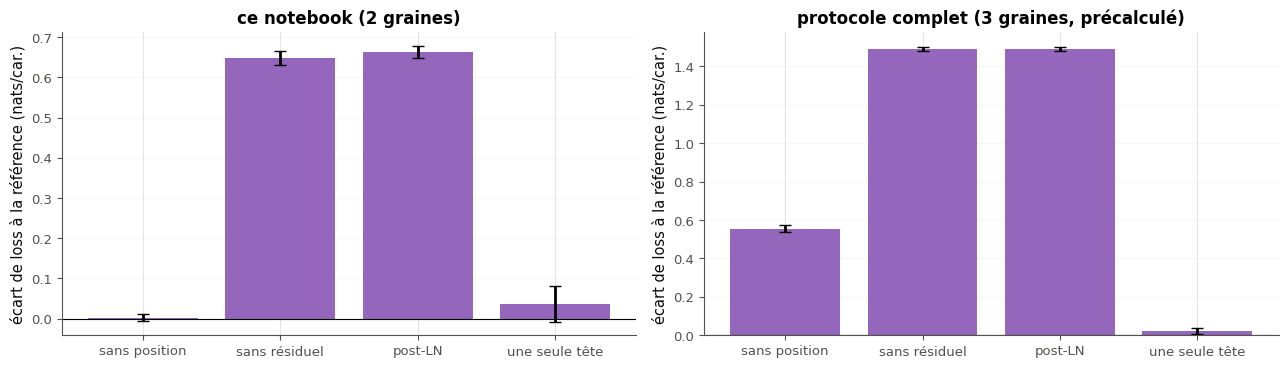

In [61]:
results_25 = None
if not globals().get("variants_ok_25"):
    print("⏳ Ex B3.25 : l'expérience attend tes cinq variantes (la cellule précédente).")
else:
    with checked("B3.25"):
        train_25 = train_20 if globals().get("probes_ok_20") else wbgpt.train
        if train_25 is wbgpt.train:
            print("ℹ️ ton train_20 (B3.20) n'a pas passé ses contrôles dans cette session : la recette de wb.gpt le remplace.")
        P = PROTOCOL_25
        results_25 = {name: [] for name in VARIANTS_25}
        started_25 = time.perf_counter()
        for seed in P["seeds"]:
            for name in VARIANTS_25:
                torch.manual_seed(seed)
                model = make_variant_25(name, P["config"])
                train_25(model, DATA.train_ids, DATA.val_ids, P["settings"], torch.Generator().manual_seed(seed),
                         block_size=P["config"]["block_size"])
                loss = wbgpt.char_loss(model, DATA.val_ids[:P["val_chars"]], block_size=P["config"]["block_size"])
                results_25[name].append(loss)
        print(f"{len(P['seeds']) * len(VARIANTS_25)} entraînements en {time.perf_counter() - started_25:.0f} s "
              f"({P['settings']['iters']} itérations chacun).\n")
        print(f"{'variante':<16} {'ce notebook : loss':>20} {'écart à la référence':>22}   {'protocole complet (3 graines)':>30}")
        base_25, base_full_25 = np.mean(results_25["reference"]), np.mean(FULL_25["reference"])
        for name in VARIANTS_25:
            mine, full = np.array(results_25[name]), np.array(FULL_25[name])
            gap = mine - np.array(results_25["reference"])
            gap_full = full - np.array(FULL_25["reference"])
            print(f"{LABELS_25[name]:<16} {fr(mine.mean(), 3):>12} ± {fr(mine.std(), 3):<5} {fr(gap.mean(), 3):>14} ± "
                  f"{fr(gap.std(), 3):<5}   {fr(full.mean(), 3):>12} ± {fr(full.std(), 3):<5} écart {fr(gap_full.mean(), 3)} "
                  f"± {fr(gap_full.std(), 3)}")
        fig_25, axes_25 = plt.subplots(1, 2, figsize=(13, 3.8), sharey=False)
        for ax, res, title in ((axes_25[0], results_25, f"ce notebook ({len(P['seeds'])} graines)"),
                               (axes_25[1], FULL_25, "protocole complet (3 graines, précalculé)")):
            gaps = [np.array(res[n]) - np.array(res["reference"]) for n in VARIANTS_25[1:]]
            ax.bar(range(4), [g.mean() for g in gaps], yerr=[g.std() for g in gaps], capsize=4, color="tab:purple")
            ax.set_xticks(range(4))
            ax.set_xticklabels([LABELS_25[n] for n in VARIANTS_25[1:]])
            ax.axhline(0, color="k", lw=0.8)
            ax.set(title=title, ylabel="écart de loss à la référence (nats/car.)")
            ax.grid(alpha=0.3, axis="y")
        plt.tight_layout()
        plt.show()

In [62]:
stuck_25, mildest_25, clear_25 = "LR", "H", 3

In [63]:
wb.record("B3.25a", "LR", mistakes={"il en manque une : compare chaque loss moyenne du protocole complet à 3 nats": "R", "il en manque une : relis chaque ligne du protocole complet et compare sa loss moyenne à 3 nats": "L", "une de trop : une ablation ne compte que si sa loss moyenne du protocole complet dépasse 3 nats": "HLR", "il y en a une de trop : relis chaque ligne du protocole complet et compare sa loss moyenne à 3 nats": "LPR"})
wb.record("B3.25b", "H", mistakes={"relis la colonne « protocole complet » : est-ce bien sans position que l'écart est le plus petit ?": "P", "relis la colonne « protocole complet » : est-ce bien sans résiduel que l'écart est le plus petit ?": "R", "relis la colonne « protocole complet » : est-ce bien en post-LN que l'écart est le plus petit ?": "L"})
wb.record("B3.25c", 3, mistakes={"compare, ligne par ligne, l'écart moyen du protocole complet au double de sa dispersion (tu en comptes 0)": 0, "compare, ligne par ligne, l'écart moyen du protocole complet au double de sa dispersion (tu en comptes 1)": 1, "compare, ligne par ligne, l'écart moyen du protocole complet au double de sa dispersion (tu en comptes 2)": 2, "compare, ligne par ligne, l'écart moyen du protocole complet au double de sa dispersion (tu en comptes 4)": 4}, fractional="on demande un nombre d'ablations, un entier", choices=[0, 1, 2, 3, 4])

WB_ANSWER {"hash": "4f08be04652b76a537316c82eaba37393559636c1d74a713e4b2d1dd9048a7a0", "id": "B3.25a", "kind": "str", "mistakes": {"3f10805620f96292f33ee8cd764c2bf8fecd49f635d3a4b086c8fb341d05dc1c": "il en manque une : relis chaque ligne du protocole complet et compare sa loss moyenne à 3 nats", "75317ed8eb69243f512c89b7c4a6a2e6dc152dfafacc673eeafcc5135c0c80fd": "une de trop : une ablation ne compte que si sa loss moyenne du protocole complet dépasse 3 nats", "9c4a9debf32420de3a6eb3ba66eb29113c40a96855b3d22f4f97e7bb3d19a99e": "il y en a une de trop : relis chaque ligne du protocole complet et compare sa loss moyenne à 3 nats", "eb85e315585d05ec6c91b915cb0b2fca8436cc447cdceb9a5c79fb9647f7f94d": "il en manque une : compare chaque loss moyenne du protocole complet à 3 nats"}}
📝 Ex B3.25a : réponse enregistrée (str).
WB_ANSWER {"hash": "c82edaf828e264a47284ffeda88bb485545e0dfeba4c5f70eb03868100ec68b5", "id": "B3.25b", "kind": "str", "mistakes": {"8c68879d9be47cd9f45c1ad4eee6555640bc6fb65a8

### Ex B3.26 — Tokens BPE du B2 contre caractères : perplexité par caractère à budget égal 🔬 ★★★ ⏱️ 45 min 🚀
**Objectif :** comparer, à budget égal et en nats par caractère, un mini-GPT de caractères et un mini-GPT de tokens BPE.  
**Prérequis :** Ex B3.20 · B2 (BPE au niveau octet, B2.16, B2.17, B2.20) · fiche §203.8 (« La loss et la perplexité ») · 🧠 R1 · **Fil rouge :** Holmes · **Parcours :** M, C

Une loss par token ne se compare pas d'un tokenizer à l'autre : un token BPE porte plusieurs caractères. La fiche (§203.8) ramène tout au **caractère** : la loss par caractère vaut la loss par token multipliée par le nombre de tokens et divisée par le nombre de caractères du même texte.

La cellule suivante prépare `TOK_26` : **ton** `BPETokenizer` de B2, au niveau octet, avec le pré-tokenizer `'gpt2'` et 512 tokens, appris sur le texte d'entraînement de Holmes (ses fusions viennent de la bibliothèque `tokenizers`, qui suit la règle de ton `fit`, comme en B2.20 ; ton `encode` fait le reste ; si ta classe n'est pas écrite, ou si ton `encode` ne donne pas les ids de la référence pour les mêmes fusions, la référence la remplace et une ligne le dit).

**Budget égal**, ici : **le même texte vu**. Les deux modèles ont les mêmes blocs, les mêmes têtes et le même $d$, le même nombre d'itérations et de séquences par batch, et un contexte qui couvre le même nombre de caractères : `char_block` caractères (128 dans le protocole complet, 64 en mode rapide) pour le modèle de caractères, `budget_block_26(caractères par token, char_block)` tokens pour le modèle BPE. Ils voient donc à peu près les mêmes caractères d'entraînement, mais ils ne font pas le même calcul : le modèle BPE a moins de positions par séquence et une table de 512 tokens au lieu de 88.

**Contrat**
- `chars_per_token_26(tok, text)` : le nombre moyen de caractères par token de `text` encodé par `tok`, un float ;
- `budget_block_26(chars_per_token, char_block)` : l'entier le plus proche de `char_block / chars_per_token` ;
- `nats_per_char_26(model, ids, tok, block_size)` : la loss d'un modèle BPE en nats par **caractère** sur les ids `ids` (un tenseur 1-D) : `wbgpt.char_loss(model, ids, block_size=block_size, stride=block_size // 4)` rend une moyenne **par token** sur les cibles `ids[block_size:]` ; convertis-la avec le nombre de ces tokens et le nombre de caractères qu'ils écrivent (`tok.decode`).

La première cellule de vérification essaie tes trois fonctions (dont `nats_per_char_26` sur un modèle uniforme, dont on connaît la loss par token : $\log 512$), puis vérifie le nombre de caractères par token de `TOK_26` sur toute la validation de Holmes (B3.26a, rien à taper). La cellule suivante entraîne, pour chaque graine de `PROTOCOL_26`, un mini-GPT de caractères et un mini-GPT BPE (ta classe `MiniGPT_19` si elle a passé ses contrôles), et affiche pour chacun le contexte, le nombre de paramètres, le temps d'entraînement et la loss par caractère sur la validation, avec les mêmes chiffres du protocole complet (`FULL_26`). Puis réponds :
- b) `better_26` : dans le protocole complet, lequel a la loss par caractère la plus basse : `"C"` les caractères, `"B"` le BPE, ou `"E"` à égalité (l'écart des moyennes est plus petit que le double de la plus grande des deux dispersions) ?

Dans tes notes : pourquoi la loss par token du modèle BPE ne se compare-t-elle à rien ? Combien de caractères chaque modèle a-t-il vus, et combien de positions a-t-il calculées par itération ? Le résultat changerait-il à **calcul** égal (le même nombre de positions par batch), ou avec 2 000 tokens (B2.20) ? Pourquoi les grands modèles de langue prennent-ils des tokens BPE alors qu'un modèle de caractères n'a ni token inconnu ni table énorme ?

In [64]:
# The tokenizer: YOUR BPETokenizer of B2 (byte level, pre-tokenizer 'gpt2', 512 tokens), learned on the training text of
# Holmes; its merges come from the library tokenizers (Rust, the rule of your fit, B2.19), your encode does the rest
VOCAB_26 = 512
try:
    _tok_class_26 = mylearn.tokenizer.BPETokenizer
    _probe_26 = _tok_class_26(vocab_size=258, pre_tokenizer="gpt2").fit("aa aa")
    _probe_26.encode("aa aa")
except Exception:  # noqa: BLE001 - B2 not done (not written, or no tokenizer.py): the reference library
    _tok_class_26 = wb.load_mylearn("ref").tokenizer.BPETokenizer
    print("ℹ️ ton BPETokenizer (B2.16, B2.17) n'est pas écrit : celui de la référence le remplace pour cet exercice.")


def bpe_26(text, vocab_size, tok_class=_tok_class_26):
    """A byte-level BPETokenizer(vocab_size, pre_tokenizer='gpt2') of tok_class with the merges of wbtext.byte_bpe_merges
    (those of fit, 50 to 200 times faster): its four learned attributes set as in B2.20."""
    tok = tok_class(vocab_size=vocab_size, pre_tokenizer="gpt2")
    tok.n_base_, tok.merges_, tok.special_ids_ = 256, wbtext.byte_bpe_merges(text, vocab_size), {}
    tok.vocab_ = {i: bytes([i]) for i in range(256)}
    for r, (a, b) in enumerate(tok.merges_):
        tok.vocab_[256 + r] = tok.vocab_[a] + tok.vocab_[b]
    return tok


from wb import text as wbtext  # noqa: E402

TOK_26 = bpe_26(DATA.train_text, VOCAB_26)
_ref_ids_26 = bpe_26(DATA.train_text, VOCAB_26, wb.load_mylearn("ref").tokenizer.BPETokenizer).encode(DATA.val_text[:3000])
if TOK_26.encode(DATA.val_text[:3000]) != _ref_ids_26:
    print("❌ Ex B3.26 : ton encode (B2.17) ne donne pas les ids de la référence pour les mêmes fusions : relance les tests "
          "de B2 ; la référence le remplace pour cet exercice.")
    TOK_26 = bpe_26(DATA.train_text, VOCAB_26, wb.load_mylearn("ref").tokenizer.BPETokenizer)
# The protocol of this notebook: fast mode, the small model of B3.25 (contexts of 64 characters), 200 iterations,
# 2 seeds; full mode (🚀), the mini-GPT of B3.20 (contexts of 128 characters), 600 iterations, 3 seeds
PROTOCOL_26 = ({'config': {'vocab_size': 88, 'block_size': 64, 'n_layer': 2, 'n_head': 4, 'd_model': 64, 'dropout': 0.0}, 'settings': {'iters': 200, 'batch_size': 32, 'lr': 0.005, 'min_lr': 0.0005, 'warmup': 20, 'weight_decay': 0.1, 'beta2': 0.99, 'clip': 1.0, 'eval_interval': 1000, 'eval_batches': 2, 'seed': 2320, 'eval_seed': 2321}, 'seeds': [2601, 2602], 'val_chars': 20000, 'char_block': 64} if FAST_MODE else {'config': {'vocab_size': 88, 'block_size': 128, 'n_layer': 4, 'n_head': 4, 'd_model': 128, 'dropout': 0.0}, 'settings': {'iters': 600, 'batch_size': 32, 'lr': 0.005, 'min_lr': 0.0005, 'warmup': 50, 'weight_decay': 0.1, 'beta2': 0.99, 'clip': 1.0, 'eval_interval': 1000, 'eval_batches': 2, 'seed': 2320, 'eval_seed': 2321}, 'seeds': [2320, 2321, 2322], 'val_chars': 56237, 'char_block': 128})
FULL_26 = {'caractères': [1.5897, 1.6, 1.6063], 'BPE 512': [1.4672, 1.4684, 1.4781]}       # the full protocol, precomputed: nats per character on the validation, one value per seed

In [65]:
def chars_per_token_26(tok, text):
    """The mean number of characters per token of `text` encoded by `tok` (a float)."""
    return len(text) / len(tok.encode(text))


def budget_block_26(chars_per_token, char_block):
    """The context in BPE tokens that covers about char_block characters: an int (equal budget, contract of B3.26)."""
    return round(char_block / chars_per_token)


def nats_per_char_26(model, ids, tok, block_size):
    """The loss of a BPE model in nats per CHARACTER on ids (1-D int64): wbgpt.char_loss(model, ids, block_size) is a
    mean per token over the targets ids[block_size:]; convert it with the characters of those same targets."""
    per_token = wbgpt.char_loss(model, ids, block_size=block_size, stride=max(1, block_size // 4))
    targets = ids[block_size:]
    n_chars = len(tok.decode(targets.tolist()))           # the characters that these tokens write
    return per_token * len(targets) / n_chars


conv_ok_26 = False
with checked("B3.26"):
    text_26 = DATA.val_text[:5000]
    cpt_26 = chars_per_token_26(TOK_26, text_26)
    want_cpt_26 = len(text_26) / len(TOK_26.encode(text_26))
    verdict("B3.26", isinstance(cpt_26, float) and math.isclose(cpt_26, want_cpt_26, rel_tol=1e-9),
            f"chars_per_token_26 : {fr(cpt_26, 3)} caractères par token sur 5 000 caractères de la validation.",
            f"chars_per_token_26 doit rendre un float, le nombre de caractères du texte divisé par son nombre de tokens ; "
            f"reçu {cpt_26!r}.")
    blocks_26 = {(2.0, 64): 32, (2.6, 128): 49, (3.9, 128): 33}
    got_blocks_26 = {k: budget_block_26(*k) for k in blocks_26}
    verdict("B3.26", all(type(v) is int for v in got_blocks_26.values()) and got_blocks_26 == blocks_26,
            "budget_block_26 : le contexte en tokens qui couvre autant de caractères (un entier).",
            f"budget_block_26(caractères par token, contexte en caractères) doit rendre l'entier le plus proche du rapport "
            f"des deux : attendu {blocks_26}, reçu {got_blocks_26}.")
    # a model whose loss is known exactly: uniform logits, log V nats per token
    class Uniform_26(nn.Module):
        def __init__(self):
            super().__init__()
            self.block_size, self.dummy = 8, nn.Parameter(torch.zeros(1))

        def forward(self, idx):
            return torch.zeros(*idx.shape, VOCAB_26)

    ids_26 = torch.tensor(TOK_26.encode(text_26))
    got_26 = nats_per_char_26(Uniform_26(), ids_26, TOK_26, 8)
    want_26 = math.log(VOCAB_26) * (len(ids_26) - 8) / len(TOK_26.decode(ids_26[8:].tolist()))
    verdict("B3.26", isinstance(got_26, float) and math.isclose(got_26, want_26, rel_tol=1e-6),
            f"nats_per_char_26 : un modèle uniforme, log 512 = {fr(math.log(VOCAB_26), 3)} nats par token, fait "
            f"{fr(want_26, 3)} nats par caractère.",
            f"un modèle uniforme fait log 512 = {fr(math.log(VOCAB_26), 3)} nats par token, donc {fr(want_26, 3)} nats par "
            f"caractère sur ce texte (multiplié par le nombre de tokens notés, divisé par leurs caractères) ; reçu {got_26!r}.")
    conv_ok_26 = math.isclose(got_26, want_26, rel_tol=1e-6) and got_blocks_26 == blocks_26
    cpt_val_26 = chars_per_token_26(TOK_26, DATA.val_text)
    print(f"sur toute la validation de Holmes : {fr(cpt_val_26, 4)} caractères par token BPE (512 tokens)")
    wb.check("B3.26a", cpt_val_26, computed=True)

✅ Ex B3.26 : chars_per_token_26 : 2,131 caractères par token sur 5 000 caractères de la validation.
✅ Ex B3.26 : budget_block_26 : le contexte en tokens qui couvre autant de caractères (un entier).
✅ Ex B3.26 : nats_per_char_26 : un modèle uniforme, log 512 = 6,238 nats par token, fait 2,924 nats par caractère.
sur toute la validation de Holmes : 2,1180 caractères par token BPE (512 tokens)
✅ Ex B3.26a : Parfait !


In [66]:
results_26 = None
if not globals().get("conv_ok_26"):
    print("⏳ Ex B3.26 : l'expérience attend tes trois fonctions (la cellule précédente).")
else:
    with checked("B3.26"):
        P = PROTOCOL_26
        cpt_26 = chars_per_token_26(TOK_26, DATA.train_text[:100_000])
        bpe_block_26 = budget_block_26(cpt_26, P["char_block"])
        train_bpe_26 = torch.tensor(TOK_26.encode(DATA.train_text))
        val_bpe_26 = torch.tensor(TOK_26.encode(DATA.val_text[:P["val_chars"]]))
        model_class_26 = MiniGPT_19 if globals().get("model_ok_19") else wbgpt.ReferenceGPT
        train_26 = train_20 if globals().get("probes_ok_20") else wbgpt.train
        print(f"{fr(cpt_26, 2)} caractères par token : un contexte de {P['char_block']} caractères vaut {bpe_block_26} "
              f"tokens BPE ; par itération, {P['settings']['batch_size']} × {P['char_block']} = "
              f"{P['settings']['batch_size'] * P['char_block']} caractères contre {P['settings']['batch_size']} × "
              f"{bpe_block_26} × {fr(cpt_26, 2)} ≈ {P['settings']['batch_size'] * bpe_block_26 * cpt_26:.0f}.")
        results_26 = {"caractères": [], "BPE 512": []}
        seconds_26 = {"caractères": 0.0, "BPE 512": 0.0}
        sizes_26 = {}
        for seed in P["seeds"]:
            for name, vocab, block, train_ids in (("caractères", len(DATA.itos), P["char_block"], DATA.train_ids),
                                                  ("BPE 512", VOCAB_26, bpe_block_26, train_bpe_26)):
                torch.manual_seed(seed)
                model = model_class_26(**(P["config"] | {"vocab_size": vocab, "block_size": block}))
                sizes_26[name] = n_params(model)
                t0 = time.perf_counter()
                train_26(model, train_ids, DATA.val_ids if name == "caractères" else val_bpe_26, P["settings"],
                         torch.Generator().manual_seed(seed), block_size=block)
                seconds_26[name] += time.perf_counter() - t0
                if name == "caractères":
                    loss = wbgpt.char_loss(model, DATA.val_ids[:P["val_chars"]], block_size=block)
                else:
                    loss = nats_per_char_26(model, val_bpe_26, TOK_26, block)
                results_26[name].append(loss)
        print(f"\n{'modèle':<12} {'contexte':>9} {'paramètres':>11} {'temps':>8}   {'nats/car. (ce notebook)':>24}   "
              f"{'protocole complet (3 graines)':>30}")
        for name, block in (("caractères", P["char_block"]), ("BPE 512", bpe_block_26)):
            mine, full = np.array(results_26[name]), np.array(FULL_26[name])
            print(f"{name:<12} {block:>9} {sizes_26[name]:>11_} {seconds_26[name] / len(P['seeds']):>6.0f} s   "
                  f"{fr(mine.mean(), 3):>16} ± {fr(mine.std(), 3):<5}   {fr(full.mean(), 3):>22} ± {fr(full.std(), 3)}"
                  .replace("_", " "))

2,08 caractères par token : un contexte de 64 caractères vaut 31 tokens BPE ; par itération, 32 × 64 = 2048 caractères contre 32 × 31 × 2,08 ≈ 2059.



modèle        contexte  paramètres    temps    nats/car. (ce notebook)    protocole complet (3 graines)
caractères          64     109 824      6 s              2,465 ± 0,008                    1,599 ± 0,007
BPE 512             31     134 848      4 s              2,327 ± 0,109                    1,471 ± 0,005


In [67]:
better_26 = "B"

In [68]:
wb.record("B3.26a", 2.1179948779752937, decimals=4)
wb.record("B3.26b", "B", mistakes={"relis les deux lignes du protocole complet : le modèle de caractères est-il le plus bas, au-delà de la dispersion ?": "C", "relis les deux lignes du protocole complet : l'écart des moyennes est-il plus petit que la dispersion des graines ?": "E"})

WB_ANSWER {"decimals": 4, "hash": "4a1509e751b202491c0e0811fc8cb2933f0bec204d562fbe33da0dbb252e6fce", "hash_coarse": "d2f3649d552d32c3c9d741c6f699f26dc84402c87ae9ee5776a07f56ba0665c4", "id": "B3.26a", "kind": "float", "magnitude": 0, "sign": 1}
📝 Ex B3.26a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"hash": "467dce6dfabd3b32b3cdc8354b933e25a150cea7c41abc8d521c81f6ec6c89c5", "id": "B3.26b", "kind": "str", "mistakes": {"9e3e56d776f6cfd09b44a66c08b42e17a4db062fad6fb4e91b2b770e0e38d166": "relis les deux lignes du protocole complet : le modèle de caractères est-il le plus bas, au-delà de la dispersion ?", "ce122a6ea4952d2f22d6077954ea173fdb13fa4daa30a7d69c14bd6ed928ee38": "relis les deux lignes du protocole complet : l'écart des moyennes est-il plus petit que la dispersion des graines ?"}}
📝 Ex B3.26b : réponse enregistrée (str).


### Ex B3.27 — Temps et mémoire de l'attention selon la longueur du contexte (64 à 2 048) 🔬 ★★ ⏱️ 25 min
**Objectif :** mesurer le temps et la mémoire d'une attention de 64 à 2 048 tokens avec les deux noyaux de SDPA sur CPU, et relier les mesures à la formule $T^2$.  
**Prérequis :** Ex B3.18 · fiche §203.10 (« La mémoire : la matrice $T \times T$ », « FlashAttention ») · 🧠 Q12 · **Parcours :** C

`F.scaled_dot_product_attention` choisit un **noyau** (*kernel*) selon le matériel et les arguments. Sur CPU, torch 2.11 en a deux : `SDPBackend.MATH`, qui écrit la matrice des poids $T \times T$ en entier, et `SDPBackend.FLASH_ATTENTION`, un noyau de type FlashAttention écrit pour CPU (fiche §203.10), qui parcourt les clés par blocs ; `torch.nn.attention.sdpa_kernel(backend)` impose l'un ou l'autre dans un bloc `with`.

**Contrat**
- `attention_time_27(T, backend, n_head=4, d_head=32, repeats=5)` : des requêtes, clés et valeurs aléatoires de forme `(1, n_head, T, d_head)` en float32, puis, dans `with sdpa_kernel(backend):`, un premier appel causal de `F.scaled_dot_product_attention` non mesuré, puis `repeats` appels mesurés (`time.perf_counter`) ; rend **le meilleur** des `repeats` temps, en millisecondes (un float) ;
- `weights_bytes_27(T, n_head=4, bytes_per_value=4)` : la mémoire, en octets (un int), des poids d'attention `(n_head, T, T)` d'une séquence.

La cellule de vérification essaie ta formule, puis ta mesure avec une sonde : les trois premiers appels de SDPA y sont ralentis de 50 ms, et seul le meilleur de plusieurs essais les ignore. La cellule suivante affiche le noyau que PyTorch choisit par défaut sur ce CPU, essaie le troisième noyau, `EFFICIENT_ATTENTION`, puis mesure pour $T$ = 64, 128, …, 2 048 et chaque noyau le temps (ta fonction) et la plus grosse allocation d'un opérateur (`profiled_bytes_27`, le profileur de PyTorch : `tracemalloc` ne voit pas la mémoire de PyTorch), à côté de ta formule ; elle calcule la pente du temps en échelles logarithmiques au-delà de 512 tokens et trace les deux graphiques. Les temps dépendent de la machine : donne-les en fourchettes.

Dans tes notes : le noyau choisi par défaut, et ce que dit l'essai d'`EFFICIENT_ATTENTION`. Tes temps à 2 048 tokens pour les deux noyaux, en fourchette, et leur rapport. La pente du noyau MATH vaut-elle 2, et pourquoi pas tout à fait ? Que mesure le profileur pour FLASH, et pourquoi si peu ? D'après ta formule, combien de mémoire faudrait-il au noyau MATH pour 32 têtes et 131 072 tokens (fiche §203.10) ? Le noyau FLASH change-t-il le nombre de FLOPs ?

In [69]:
from torch.nn.attention import SDPBackend, sdpa_kernel
from torch.profiler import ProfilerActivity, profile
import warnings

warnings.filterwarnings("ignore", message=".*Profiler clears events.*")   # one profile per call: nothing to keep

LENGTHS_27 = (64, 128, 256, 512, 1024, 2048)
BACKENDS_27 = {"MATH": SDPBackend.MATH, "FLASH": SDPBackend.FLASH_ATTENTION}


def profiled_bytes_27(T, backend, n_head=4, d_head=32):
    """The largest memory allocated by one operator during one causal SDPA (1, n_head, T, d_head) with the kernel
    `backend`, read by the profiler of PyTorch (profile_memory=True), in bytes. tracemalloc would not see it: PyTorch
    allocates its tensors outside of Python's allocator."""
    q, k, v = (torch.randn(1, n_head, T, d_head) for _ in range(3))
    with sdpa_kernel(backend):
        with profile(activities=[ProfilerActivity.CPU], profile_memory=True) as prof:
            F.scaled_dot_product_attention(q, k, v, is_causal=True)
    return max((event.cpu_memory_usage for event in prof.key_averages()), default=0)

In [70]:
def attention_time_27(T, backend, n_head=4, d_head=32, repeats=5):
    """The best time, in milliseconds, of one causal F.scaled_dot_product_attention on random q, k, v of shape
    (1, n_head, T, d_head) in float32, with the kernel `backend` (contract of Ex B3.27)."""
    q, k, v = (torch.randn(1, n_head, T, d_head) for _ in range(3))
    best = math.inf
    with sdpa_kernel(backend):
        F.scaled_dot_product_attention(q, k, v, is_causal=True)          # a first call, not timed (warm-up)
        for _ in range(repeats):
            start = time.perf_counter()
            F.scaled_dot_product_attention(q, k, v, is_causal=True)
            best = min(best, time.perf_counter() - start)               # the best: the least disturbed run
    return 1000 * best


def weights_bytes_27(T, n_head=4, bytes_per_value=4):
    """The memory, in bytes, of the attention weights (n_head, T, T) of one sequence (an int)."""
    return n_head * T * T * bytes_per_value


timing_ok_27 = False
with checked("B3.27"):
    verdict("B3.27", weights_bytes_27(1000) == 16_000_000 and weights_bytes_27(10, 2, 2) == 400
            and type(weights_bytes_27(1000)) is int,
            "weights_bytes_27 : 4 têtes × 1 000² poids × 4 octets = 16 000 000 octets.",
            f"weights_bytes_27(1000) doit valoir 4 × 1 000 × 1 000 × 4 = 16 000 000 (un int) et weights_bytes_27(10, 2, 2) "
            f"400 ; reçu {weights_bytes_27(1000)!r} et {weights_bytes_27(10, 2, 2)!r}.")
    # the best of several runs: a probe whose first call is 50 ms slower
    sdpa_27, calls_27 = F.scaled_dot_product_attention, []

    def slow_first_27(*args, **kwargs):
        calls_27.append(1)
        if len(calls_27) <= 3:
            time.sleep(0.05)
        return sdpa_27(*args, **kwargs)

    F.scaled_dot_product_attention = slow_first_27
    try:
        probe_27 = attention_time_27(64, SDPBackend.MATH, repeats=5)
    finally:
        F.scaled_dot_product_attention = sdpa_27
    if not isinstance(probe_27, (int, float)) or not probe_27 > 0:
        print(f"❌ Ex B3.27 : attention_time_27 doit rendre un temps en millisecondes, un nombre positif ; reçu {probe_27!r}.")
        raise StopCheck
    if not calls_27:
        print("ℹ️ Ex B3.27 : ta fonction n'appelle pas F.scaled_dot_product_attention par son nom complet : le contrôle du "
              "meilleur de plusieurs essais est sauté.")
        timing_ok_27 = True
    else:
        timing_ok_27 = len(calls_27) >= 5 and 0.01 <= probe_27 < 8
        verdict("B3.27", timing_ok_27,
                f"attention_time_27 : le meilleur de plusieurs essais, en millisecondes ({fr(probe_27, 2)} ms à T = 64, "
                "malgré trois premiers appels ralentis de 50 ms).",
                f"attention_time_27 a rendu {probe_27:.3g} pour T = 64 en {len(calls_27)} appel(s), alors que les trois "
                "premiers appels étaient ralentis de 50 ms (une attention de 64 tokens prend de l'ordre de 0,1 ms) : rends "
                "le meilleur de `repeats` essais, après un premier appel non mesuré, en millisecondes.")

✅ Ex B3.27 : weights_bytes_27 : 4 têtes × 1 000² poids × 4 octets = 16 000 000 octets.
✅ Ex B3.27 : attention_time_27 : le meilleur de plusieurs essais, en millisecondes (0,28 ms à T = 64, malgré trois premiers appels ralentis de 50 ms).


noyau choisi par défaut sur ce CPU (torch._fused_sdp_choice) : FLASH_ATTENTION
EFFICIENT_ATTENTION : No viable backend for scaled_dot_product_attention was found. This is likely due to turnin



     T  MATH (ms)  FLASH (ms)  rapport    poids, formule  MATH, mesuré  FLASH, mesuré
    64       0,24        0,03      7,5          0,06 Mio      0,09 Mio       0,03 Mio
   128       0,41        0,08      5,3          0,25 Mio      0,31 Mio       0,06 Mio
   256       1,33        0,24      5,5          1,00 Mio      1,12 Mio       0,15 Mio
   512       4,07        0,94      4,3          4,00 Mio      4,25 Mio       0,27 Mio
  1024      15,07        2,78      5,4         16,00 Mio     16,50 Mio       1,08 Mio
  2048      87,39        9,06      9,6         64,00 Mio     65,00 Mio       1,10 Mio

pente du temps en log-log, de 512 à 2 048 tokens : {'MATH': '2,21', 'FLASH': '1,64'}
✅ Ex B3.27 : noyau MATH : le temps croît comme T^2,2 au-delà de 512 tokens (quadratique).
✅ Ex B3.27 : mémoire à 2 048 tokens : le noyau MATH alloue la matrice des poids (ta formule), le noyau FLASH beaucoup moins.


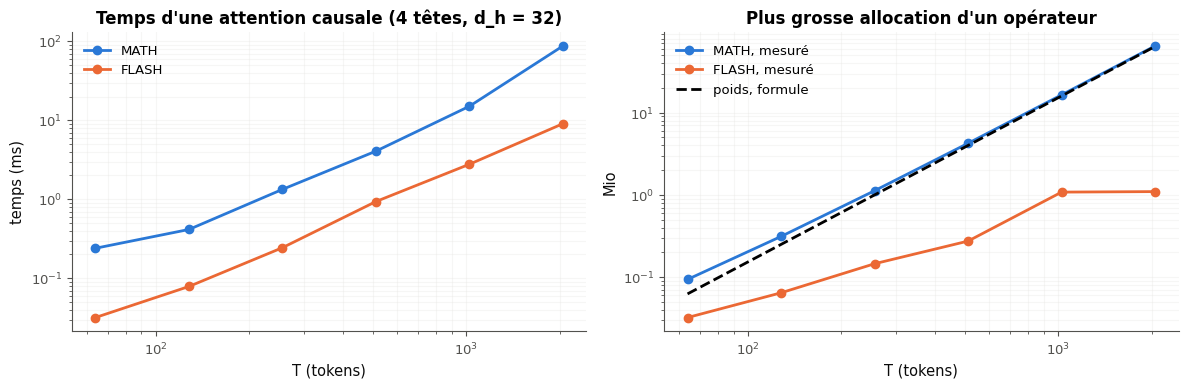

In [71]:
if not globals().get("timing_ok_27"):
    print("⏳ Ex B3.27 : la mesure attend tes deux fonctions (la cellule précédente).")
else:
    with checked("B3.27"):
        q_27 = torch.randn(1, 4, 256, 32)
        print("noyau choisi par défaut sur ce CPU (torch._fused_sdp_choice) :",
              {0: "MATH", 1: "FLASH_ATTENTION", 2: "EFFICIENT_ATTENTION"}.get(torch._fused_sdp_choice(q_27, q_27, q_27, is_causal=True), "?"))
        try:
            with sdpa_kernel(SDPBackend.EFFICIENT_ATTENTION):
                F.scaled_dot_product_attention(q_27, q_27, q_27, is_causal=True)
            print("EFFICIENT_ATTENTION : disponible")
        except RuntimeError as exc:
            print("EFFICIENT_ATTENTION :", str(exc).splitlines()[0][:90])
        times_27 = {name: [attention_time_27(T, b) for T in LENGTHS_27] for name, b in BACKENDS_27.items()}
        bytes_27 = {name: [profiled_bytes_27(T, b) for T in LENGTHS_27] for name, b in BACKENDS_27.items()}
        print(f"\n{'T':>6} {'MATH (ms)':>10} {'FLASH (ms)':>11} {'rapport':>8}   {'poids, formule':>15} {'MATH, mesuré':>13} "
              f"{'FLASH, mesuré':>14}")
        for i, T in enumerate(LENGTHS_27):
            print(f"{T:>6} {fr(times_27['MATH'][i], 2):>10} {fr(times_27['FLASH'][i], 2):>11} "
                  f"{fr(times_27['MATH'][i] / times_27['FLASH'][i], 1):>8}   {fr(weights_bytes_27(T) / 2**20, 2) + ' Mio':>15} "
                  f"{fr(bytes_27['MATH'][i] / 2**20, 2) + ' Mio':>13} {fr(bytes_27['FLASH'][i] / 2**20, 2) + ' Mio':>14}")
        slopes_27 = {name: np.polyfit(np.log(LENGTHS_27[3:]), np.log(t[3:]), 1)[0] for name, t in times_27.items()}
        print("\npente du temps en log-log, de 512 à 2 048 tokens :", {n: fr(s, 2) for n, s in slopes_27.items()})
        verdict("B3.27", 1.5 <= slopes_27["MATH"] <= 2.5,
                f"noyau MATH : le temps croît comme T^{fr(slopes_27['MATH'], 1)} au-delà de 512 tokens (quadratique).",
                f"noyau MATH : pente {fr(slopes_27['MATH'], 2)} au-delà de 512 tokens, loin de 2 : la machine est-elle "
                "chargée ? Relance la cellule.")
        verdict("B3.27", abs(bytes_27["MATH"][-1] / weights_bytes_27(LENGTHS_27[-1]) - 1) < 0.1
                and bytes_27["FLASH"][-1] < 0.1 * weights_bytes_27(LENGTHS_27[-1]),
                "mémoire à 2 048 tokens : le noyau MATH alloue la matrice des poids (ta formule), le noyau FLASH beaucoup "
                "moins.", "mémoire à 2 048 tokens : la plus grosse allocation mesurée de MATH devrait être voisine de ta "
                "formule, et celle de FLASH bien plus petite.")
        fig_27, axes_27 = plt.subplots(1, 2, figsize=(12, 4))
        for name in BACKENDS_27:
            axes_27[0].loglog(LENGTHS_27, times_27[name], "o-", label=name)
            axes_27[1].loglog(LENGTHS_27, [b / 2**20 for b in bytes_27[name]], "o-", label=f"{name}, mesuré")
        axes_27[1].loglog(LENGTHS_27, [weights_bytes_27(T) / 2**20 for T in LENGTHS_27], "k--", label="poids, formule")
        axes_27[0].set(xlabel="T (tokens)", ylabel="temps (ms)", title="Temps d'une attention causale (4 têtes, d_h = 32)")
        axes_27[1].set(xlabel="T (tokens)", ylabel="Mio", title="Plus grosse allocation d'un opérateur")
        for ax in axes_27:
            ax.grid(alpha=0.3, which="both")
            ax.legend()
        plt.tight_layout()
        plt.show()

## Partie E · Un ViT, un test de causalité et le défi

Le Transformer hors du texte : un Vision Transformer minuscule sur Fashion-MNIST (B3.28) ; une compétence pro : un test pytest qui garantit la causalité du mini-GPT (B3.29) ; et le défi du chapitre (B3.30).

### Ex B3.28 — Un Vision Transformer minuscule : Fashion-MNIST découpé en patchs 📦 ★★★ ⏱️ 45 min 🚀
**Objectif :** écrire un Vision Transformer minuscule, des patchs de $7 \times 7$ à la classe, et l'entraîner sur Fashion-MNIST.  
**Prérequis :** Ex B3.19 · ch. 21 (convolutions, Fashion-MNIST) · fiche §203.10 (« Le Vision Transformer »), §203.7 (l'encodeur) · **Fil rouge :** Fashion-MNIST · **Parcours :** C

Une image de Fashion-MNIST ($28 \times 28$, un canal) se découpe en $4 \times 4 = 16$ patchs de $7 \times 7$ pixels : 16 tokens, plus un token `[CLS]` dont la sortie classe l'image (fiche §203.10). L'exemple de la fiche prend CIFAR-10 et des patchs de 4 pixels ; ici, des vêtements, et un **encodeur** : chaque token voit tous les autres.

**Contrat**
- `EncoderBlock_28(d_model, n_head, dropout=0.0)` : ton bloc pré-LN de B3.19, **sans masque causal** : $\mathbf{h} = \mathbf{x} + \operatorname{attn}(\operatorname{LN}_1(\mathbf{x}))$, puis $\mathbf{h} + \operatorname{mlp}(\operatorname{LN}_2(\mathbf{h}))$, l'attention multi-têtes par `F.scaled_dot_product_attention` (avec ses projections `qkv` et `proj`, comme `CausalSelfAttention_18`, et un dropout des poids en mode train seulement), le MLP GELU de largeur $4d$ ; `x` (N, T, d) → (N, T, d).
- `ViT_28(image_size=28, patch_size=7, n_classes=10, d_model=64, n_layer=4, n_head=4, dropout=0.0)` :
  - `patch_embed = nn.Conv2d(1, d_model, kernel_size=patch_size, stride=patch_size)` : une couche dense par patch, écrite comme une convolution (fiche §203.10) ; ses 16 sorties, dans l'ordre de lecture (ligne par ligne, ce que donne `flatten(2)`), sont les tokens des patchs ;
  - `cls_token`, un `nn.Parameter` de forme `(1, 1, d_model)`, placé **en tête** de la séquence ; `pos_emb`, des positions apprises, un `nn.Parameter` de forme `(1, 1 + 16, d_model)` (initialisées petites, $\mathcal{N}(0;\ 0{,}02^2)$ par exemple), ajoutées aux 17 tokens ;
  - `blocks`, un `nn.ModuleList` de `n_layer` `EncoderBlock_28`, puis `ln_f` (`nn.LayerNorm`) et `head = nn.Linear(d_model, n_classes)` appliquée à la sortie du `[CLS]` ;
  - `forward(x)` : des images `(N, 1, 28, 28)` → des logits `(N, n_classes)` ; `ValueError` si `patch_size` ne divise pas `image_size` ;
  - ni `nn.Transformer…` ni `nn.MultiheadAttention`.

La cellule suivante charge Fashion-MNIST (normalisé comme aux ch. 20 et 21), et donne `train_vit_28` (AdamW, warmup puis cosinus, clipping) et `accuracy_28`. La cellule de vérification contrôle les formes des paramètres, celle des logits, que la sortie dépende du premier **et** du dernier patch (le `[CLS]` voit toute l'image), que les positions servent (échanger deux patchs change la sortie), l'entrée du premier bloc (lue par un *hook* : le `[CLS]` en tête, puis les patchs dans l'ordre de lecture) et un refus. La suivante entraîne ton ViT : 12 000 images et 3 epochs en mode rapide (moins d'une minute) ; 🚀 60 000 images et 12 epochs en mode complet (environ 6 min sur CPU) ; puis elle mesure l'accuracy sur les 10 000 images de test, comparée au seuil `TARGET_28`.

Dans tes notes : ton nombre de paramètres et ton accuracy, face au CNN du ch. 21 (le défi y demandait 92 % avec moins de 100 000 paramètres). Pourquoi un ViT manque-t-il de biais inductifs (§203.10), et qu'est-ce que cela change sur 12 000 images ? Que donnerait ton ViT si le masque causal restait dans les blocs ? Le `[CLS]` est-il indispensable, ou la moyenne des 16 tokens ferait-elle l'affaire ?

In [72]:
from wb import datasets as wbdata

N_TRAIN_28, EPOCHS_28 = (12_000, 3) if FAST_MODE else (60_000, 12)
_xtr_28, _ytr_28 = wbdata.load_fashion_mnist("train", n=N_TRAIN_28 if FAST_MODE else None, seed=0)
_xte_28, _yte_28 = wbdata.load_fashion_mnist("test")
MEAN_28, STD_28 = 0.2860, 0.3530                          # the statistics of the training images (ch. 20 and 21)
X_TRAIN_28 = (torch.from_numpy(_xtr_28).float().div(255).sub(MEAN_28).div(STD_28))[:, None]   # (N, 1, 28, 28)
Y_TRAIN_28 = torch.from_numpy(_ytr_28).long()
X_TEST_28 = (torch.from_numpy(_xte_28).float().div(255).sub(MEAN_28).div(STD_28))[:, None]
Y_TEST_28 = torch.from_numpy(_yte_28).long()
TARGET_28 = 0.79 if FAST_MODE else 0.87   # accuracy on the 10 000 test images


def train_vit_28(model, X, y, epochs, batch_size=128, lr=2e-3, weight_decay=0.05, seed=28):
    """AdamW, linear warmup then cosine decay (per mini-batch, wbgpt.lr_at), clipping at 1: returns the mean training
    loss of each epoch."""
    generator = torch.Generator().manual_seed(seed)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    steps, step, losses = epochs * math.ceil(len(X) / batch_size), 0, []
    model.train()
    for _ in range(epochs):
        total = 0.0
        for batch in torch.randperm(len(X), generator=generator).split(batch_size):
            for group in optimizer.param_groups:
                group["lr"] = wbgpt.lr_at(step, steps, lr, steps // 10, lr / 20)
            loss = F.cross_entropy(model(X[batch]), y[batch])
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total += loss.item() * len(batch)
            step += 1
        losses.append(total / len(X))
    return losses


@torch.no_grad()
def accuracy_28(model, X, y, batch_size=1000):
    """The accuracy of `model` (eval mode) on (X, y)."""
    model.eval()
    return sum((model(X[i:i + batch_size]).argmax(1) == y[i:i + batch_size]).sum().item()
               for i in range(0, len(X), batch_size)) / len(X)


print(f"Fashion-MNIST : {len(X_TRAIN_28):_} images d'entraînement, {len(X_TEST_28):_} de test, {EPOCHS_28} epochs."
      .replace("_", " "))

Fashion-MNIST : 12 000 images d'entraînement, 10 000 de test, 3 epochs.


In [73]:
class EncoderBlock_28(nn.Module):
    """A pre-LN encoder block (contract of Ex B3.28): every token sees every token, x (N, T, d) -> (N, T, d)."""

    def __init__(self, d_model, n_head, dropout=0.0):
        super().__init__()
        if d_model % n_head:
            raise ValueError(f"n_head = {n_head} must divide d_model = {d_model}")
        self.n_head, self.dropout = n_head, dropout
        self.ln1 = nn.LayerNorm(d_model)
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.proj = nn.Linear(d_model, d_model)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(), nn.Linear(4 * d_model, d_model),
                                 nn.Dropout(dropout))

    def forward(self, x):
        N, T, D = x.shape
        q, k, v = self.qkv(self.ln1(x)).split(D, dim=2)
        q, k, v = (t.view(N, T, self.n_head, D // self.n_head).transpose(1, 2) for t in (q, k, v))
        y = F.scaled_dot_product_attention(q, k, v, dropout_p=self.dropout if self.training else 0.0)   # no mask
        x = x + self.proj(y.transpose(1, 2).reshape(N, T, D))
        return x + self.mlp(self.ln2(x))


class ViT_28(nn.Module):
    """A tiny Vision Transformer (contract of Ex B3.28): images (N, 1, 28, 28) -> logits (N, n_classes)."""

    def __init__(self, image_size=28, patch_size=7, n_classes=10, d_model=64, n_layer=4, n_head=4, dropout=0.0):
        super().__init__()
        if image_size % patch_size:
            raise ValueError(f"patch_size = {patch_size} must divide image_size = {image_size}")
        n_patches = (image_size // patch_size) ** 2
        self.patch_embed = nn.Conv2d(1, d_model, kernel_size=patch_size, stride=patch_size)   # a dense layer per patch
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))
        self.pos_emb = nn.Parameter(torch.randn(1, 1 + n_patches, d_model) * 0.02)
        self.blocks = nn.ModuleList([EncoderBlock_28(d_model, n_head, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, n_classes)

    def forward(self, x):
        tokens = self.patch_embed(x).flatten(2).transpose(1, 2)                  # (N, 16, d): one token per patch
        tokens = torch.cat([self.cls_token.expand(len(x), -1, -1), tokens], dim=1) + self.pos_emb
        for block in self.blocks:
            tokens = block(tokens)
        return self.head(self.ln_f(tokens[:, 0]))                                # the [CLS] token classifies


vit_ok_28 = False
with checked("B3.28"):
    need("B3.28", "ViT_28")
    torch.manual_seed(28)
    vit_28 = ViT_28()
    if forbidden_in(vit_28):
        print(f"❌ Ex B3.28 : ton ViT contient {forbidden_in(vit_28)} : le contrat demande ton propre bloc d'encodeur.")
        raise StopCheck
    shapes_28 = {n: tuple(p.shape) for n, p in vit_28.named_parameters()}
    want_28 = {"patch_embed.weight": (64, 1, 7, 7), "patch_embed.bias": (64,), "cls_token": (1, 1, 64),
               "pos_emb": (1, 17, 64), "head.weight": (10, 64), "head.bias": (10,)}
    wrong_28 = {n: shapes_28.get(n) for n, s in want_28.items() if shapes_28.get(n) != s}
    verdict("B3.28", not wrong_28 and len(vit_28.blocks) == 4,
            "les patchs : une convolution 7 × 7 de stride 7 vers d = 64, un token [CLS], 17 positions apprises (16 patchs "
            "+ [CLS]), 4 blocs et une tête de 10 classes.",
            f"paramètres attendus {want_28} et 4 blocs ; différents : {wrong_28}, {len(getattr(vit_28, 'blocks', []))} bloc(s).")
    if wrong_28:
        raise StopCheck
    print(f"{n_params(vit_28):_} paramètres.".replace("_", " "))
    vit_28.eval()
    x_28 = X_TEST_28[:4].clone()
    with torch.no_grad():
        out_28 = vit_28(x_28)
        shape_ok_28 = tuple(out_28.shape) == (4, 10)
        verdict("B3.28", shape_ok_28, "des images (4, 1, 28, 28) donnent des logits (4, 10).",
                f"des images (4, 1, 28, 28) doivent donner des logits (4, 10) ; reçu {tuple(out_28.shape)}.")
        if not shape_ok_28:
            raise StopCheck
        last_28 = x_28.clone()
        last_28[:, :, 21:, 21:] += 1.0                                         # the last patch (bottom right) only
        first_28 = x_28.clone()
        first_28[:, :, :7, :7] += 1.0                                          # the first patch (top left) only
        sees_last_28 = (vit_28(last_28) - out_28).abs().max().item() > 1e-6
        sees_first_28 = (vit_28(first_28) - out_28).abs().max().item() > 1e-6
    verdict("B3.28", sees_last_28 and sees_first_28,
            "la sortie dépend du premier et du dernier patch : le [CLS] voit toute l'image (aucun masque causal).",
            "la sortie ne dépend pas " + ("du dernier patch" if not sees_last_28 else "du premier patch")
            + " : un masque causal resté dans l'encodeur ? Le [CLS] doit voir tous les patchs.")
    with torch.no_grad():
        swapped_28 = x_28.clone()
        swapped_28[:, :, :7, :7], swapped_28[:, :, 21:, 21:] = x_28[:, :, 21:, 21:], x_28[:, :, :7, :7]
        moved_28 = (vit_28(swapped_28) - out_28).abs().max().item()
    verdict("B3.28", moved_28 > 1e-6, "échanger deux patchs change la sortie : les positions apprises sont ajoutées.",
            "échanger le premier et le dernier patch ne change pas la sortie : les positions apprises sont-elles ajoutées "
            "aux tokens ?")
    seen_28 = {}
    hook_28 = vit_28.blocks[0].register_forward_hook(lambda m, inp, out: seen_28.__setitem__("in", inp[0]))
    try:
        with torch.no_grad():
            vit_28(x_28)
            want_cls_28 = (vit_28.cls_token + vit_28.pos_emb[:, :1]).expand(4, -1, -1)
            want_patches_28 = vit_28.patch_embed(x_28).flatten(2).transpose(1, 2) + vit_28.pos_emb[:, 1:]
    finally:
        hook_28.remove()
    got_in_28 = seen_28.get("in")
    order_ok_28 = got_in_28 is not None and tuple(got_in_28.shape) == (4, 17, 64) \
        and torch.allclose(got_in_28[:, :1], want_cls_28, atol=1e-6) and torch.allclose(got_in_28[:, 1:], want_patches_28, atol=1e-5)
    verdict("B3.28", order_ok_28,
            "l'entrée du premier bloc : le [CLS] en tête, puis les 16 patchs dans l'ordre de lecture, positions ajoutées.",
            "l'entrée du premier bloc doit être (4, 17, 64) : le [CLS] en position 0, puis les 16 tokens des patchs dans "
            "l'ordre de patch_embed(x).flatten(2).transpose(1, 2), chacun avec sa position apprise ; reçu "
            + (f"{tuple(got_in_28.shape)}" if got_in_28 is not None else "rien") + ".")
    refuses("B3.28", "patch_size = 5 pour des images de 28 pixels", lambda: ViT_28(patch_size=5))
    vit_ok_28 = sees_last_28 and sees_first_28 and moved_28 > 1e-6 and order_ok_28

✅ Ex B3.28 : les patchs : une convolution 7 × 7 de stride 7 vers d = 64, un token [CLS], 17 positions apprises (16 patchs + [CLS]), 4 blocs et une tête de 10 classes.
205 066 paramètres.
✅ Ex B3.28 : des images (4, 1, 28, 28) donnent des logits (4, 10).
✅ Ex B3.28 : la sortie dépend du premier et du dernier patch : le [CLS] voit toute l'image (aucun masque causal).
✅ Ex B3.28 : échanger deux patchs change la sortie : les positions apprises sont ajoutées.
✅ Ex B3.28 : l'entrée du premier bloc : le [CLS] en tête, puis les 16 patchs dans l'ordre de lecture, positions ajoutées.
✅ Ex B3.28 : patch_size = 5 pour des images de 28 pixels : ValueError levée (patch_size = 5 must divide image_size = 28).


In [74]:
if not globals().get("vit_ok_28"):
    print("⏳ Ex B3.28 : l'entraînement attend ton ViT (la cellule précédente).")
else:
    with checked("B3.28"):
        torch.manual_seed(28)
        model_28 = ViT_28()
        t0_28 = time.perf_counter()
        losses_28 = train_vit_28(model_28, X_TRAIN_28, Y_TRAIN_28, EPOCHS_28)
        seconds_28 = time.perf_counter() - t0_28
        acc_28 = accuracy_28(model_28, X_TEST_28, Y_TEST_28)
        print(f"{EPOCHS_28} epochs en {seconds_28:.0f} s ; loss d'entraînement par epoch {[round(l, 3) for l in losses_28]} ; "
              f"accuracy de test {fr(100 * acc_28, 1)} %.")
        verdict("B3.28", acc_28 >= TARGET_28, f"accuracy de test {fr(100 * acc_28, 1)} %, au-dessus de {fr(100 * TARGET_28, 0)} %.",
                f"accuracy de test {fr(100 * acc_28, 1)} % : attendu au moins {fr(100 * TARGET_28, 0)} % ; relis les "
                "contrôles de la cellule précédente.")

3 epochs en 16 s ; loss d'entraînement par epoch [1.088, 0.609, 0.475] ; accuracy de test 81,8 %.
✅ Ex B3.28 : accuracy de test 81,8 %, au-dessus de 79 %.


### Ex B3.29 — Un test pytest qui prouve la causalité : modifier le futur ne change pas les logits passés 🛠️ ★★ ⏱️ 20 min
**Objectif :** écrire le test pytest qui garantit qu'un modèle de langue causal ne voit pas le futur, et vérifier qu'il attrape des modèles qui trichent.  
**Prérequis :** Ex B3.19 · fiche §203.3 (« Le masque causal »), §203.8 (💼 En entreprise : les trois contrôles) · ✏️ B3.2 · ch. 0A (tests pytest) · **Fil rouge :** Holmes · **Parcours :** C

Un modèle causal qui voit le futur s'entraîne très bien : sa loss d'entraînement baisse vite et il ne sait rien générer (🐛 B3.17). En entreprise, l'invariant de la causalité se garde par un **test** qui tourne à chaque modification du code : changer le token d'une position $t$ ne change **aucun** logit des positions avant $t$.

Écris `test_causality_29()`, une fonction de test pytest :
- elle tourne dans un fichier à part, que `wb.run_pytest` écrit et lance dans un autre processus : elle ne lit **aucune** variable du notebook ; ce fichier lui fournit `MODEL` (un mini-GPT en mode eval, sans gradient), `VOCAB_SIZE`, `BLOCK_SIZE` et `torch` ;
- elle vérifie l'invariant par des `assert` dont le message dit ce qui était attendu ;
- elle doit **échouer** sur un modèle qui voit le futur, ne serait-ce qu'à une seule position, et **passer** sur le bon ; elle tourne en quelques secondes.

La cellule suivante prépare les modèles testés : ton mini-GPT entraîné (sa sauvegarde de B3.20, chargée dans la classe `ReferenceGPT` de `wb.gpt`, aux mêmes noms : une classe définie dans un notebook ne se copie pas dans un fichier de test), ou un mini-GPT non entraîné s'il n'y a pas de sauvegarde (la causalité ne dépend pas de l'entraînement), et trois copies dont l'attention voit le futur. La cellule de vérification lance ton test sur le bon modèle (il doit passer), puis sur les trois copies : un masque causal transposé, un masque qui laisse voir le token suivant, et un masque qui ne le laisse voir qu'à partir de la position 100. Pour chacune, ton test doit échouer : la cellule affiche alors le nom du test et la raison de l'échec, sur deux lignes.

Dans tes notes : pourquoi comparer les logits **exactement** est-il possible ici, et quand faudrait-il une tolérance ? Que coûte ton test, en passes du modèle ? Quel autre invariant du mini-GPT mériterait un test (la forme des logits, la loss de départ, les poids liés) ? Où placerais-tu ces tests dans un dépôt, et quand les lancerais-tu ?

In [75]:
# The models under test: your trained mini-GPT (its checkpoint, in the class ReferenceGPT of wb.gpt), or an untrained
# mini-GPT when there is none (causality does not depend on training); and three copies whose attention sees the future
SUBJECT_29 = str(CKPT["path"]) if CKPT is not None else None
_PREAMBLE_29 = """
import torch
import torch.nn.functional as F
from wb import gpt as wbgpt

torch.set_grad_enabled(False)


PATH = {path!r}


def _subject():
    if PATH is None:
        torch.manual_seed(29)
        return wbgpt.ReferenceGPT(**wbgpt.MINI_CONFIG).eval()
    return wbgpt.build_from_checkpoint(wbgpt.ReferenceGPT, torch.load(PATH, map_location="cpu", weights_only=True))


def _with_mask(model, rule):
    # every attention of the model, with the boolean mask rule(T) (True = may attend) instead of the causal one
    def forward(attn, x):
        N, T, D = x.shape
        q, k, v = attn.qkv(x).split(D, dim=2)
        q, k, v = (t.view(N, T, attn.n_head, D // attn.n_head).transpose(1, 2) for t in (q, k, v))
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=rule(T))
        return attn.proj(y.transpose(1, 2).reshape(N, T, D))
    for block in model.blocks:
        block.attn.forward = forward.__get__(block.attn)
    return model


_RULES = {{
    "transposed": lambda T: torch.ones(T, T, dtype=torch.bool).triu(),
    "one_ahead": lambda T: torch.ones(T, T, dtype=torch.bool).tril(diagonal=1),
    "late_leak": lambda T: torch.ones(T, T, dtype=torch.bool).tril() | (torch.eye(T, dtype=torch.bool).roll(1, dims=1)
                                                                       & (torch.arange(T)[:, None] >= 100)),
}}
MODEL = _subject() if {kind!r} == "good" else _with_mask(_subject(), _RULES[{kind!r}])
VOCAB_SIZE, BLOCK_SIZE = MODEL.tok_emb.num_embeddings, MODEL.block_size
"""


def preamble_29(kind):
    """The code that the test file runs before your test: MODEL (eval mode, no gradient), VOCAB_SIZE, BLOCK_SIZE."""
    return _PREAMBLE_29.format(path=SUBJECT_29, kind=kind)


def failures_29(result):
    """(name, reason) of each failed test of a wb.run_pytest result, read in pytest's short summary."""
    out = []
    for line in result.output.splitlines():
        if line.startswith("FAILED ") or line.startswith("ERROR "):
            name, _, reason = line.split(" ", 1)[1].partition(" - ")
            out.append((name.split("::")[-1], reason.strip() or "(sans message)"))
    return out


print("modèle testé :", "ton mini-GPT entraîné (B3.20)" if SUBJECT_29 else "un mini-GPT non entraîné (pas de sauvegarde de B3.20)")

modèle testé : ton mini-GPT entraîné (B3.20)


In [76]:
def test_causality_29():
    """Changing the token at a position t never changes the logits of the positions before t (MODEL, VOCAB_SIZE,
    BLOCK_SIZE and torch are given by the test file)."""
    generator = torch.Generator().manual_seed(0)
    idx = torch.randint(0, VOCAB_SIZE, (2, BLOCK_SIZE), generator=generator)
    logits = MODEL(idx)
    for t in range(1, BLOCK_SIZE):                         # every position, the first one excepted (nothing before it)
        changed = idx.clone()
        changed[:, t] = (changed[:, t] + 1) % VOCAB_SIZE
        past = (MODEL(changed)[:, :t] - logits[:, :t]).abs().max().item()
        assert past == 0, f"expected the logits before position {t} unchanged, got a change of {past:.2e}"


import inspect

if "NotImplementedError" in inspect.getsource(test_causality_29):
    print("⏳ Ex B3.29 : écris ton test de causalité.")
else:
    with checked("B3.29"):
        print("Ton test, sur le bon modèle (il doit passer) :")
        good_29 = wb.run_pytest([test_causality_29], preamble=preamble_29("good"))
        verdict("B3.29", good_29.ok, "ton test passe sur le bon modèle.",
                "ton test doit passer sur le bon modèle (la sortie de pytest est au-dessus).")
        if not good_29.ok:
            raise StopCheck
        for kind, label in (("transposed", "au masque causal transposé (triu au lieu de tril)"),
                            ("one_ahead", "dont le masque laisse voir le token suivant"),
                            ("late_leak", "dont le masque laisse voir le token suivant à partir de la position 100 seulement")):
            bad_29 = wb.run_pytest([test_causality_29], preamble=preamble_29(kind), quiet=True)
            caught_29 = not bad_29.ok and bad_29.failed > 0
            verdict("B3.29", caught_29, f"ton test échoue sur un modèle {label} :",
                    f"ton test laisse passer un modèle {label}" + ("." if bad_29.errors == 0 else
                    f" (pytest : {bad_29.summary})."))
            for name, reason in failures_29(bad_29)[:1]:
                print(f"   {name}\n   {reason[:300]}")

Ton test, sur le bon modèle (il doit passer) :


pytest : 1 passed in 2.10s
✅ Ex B3.29 : ton test passe sur le bon modèle.


✅ Ex B3.29 : ton test échoue sur un modèle au masque causal transposé (triu au lieu de tril) :
   test_causality_29
   AssertionError: expected the logits before position 1 unchanged, got a change of 1.70e+00


✅ Ex B3.29 : ton test échoue sur un modèle dont le masque laisse voir le token suivant :
   test_causality_29
   AssertionError: expected the logits before position 1 unchanged, got a change of 4.58e+00


✅ Ex B3.29 : ton test échoue sur un modèle dont le masque laisse voir le token suivant à partir de la position 100 seulement :
   test_causality_29
   AssertionError: expected the logits before position 101 unchanged, got a change of 2.09e-01


### Ex B3.30 — Défi : la meilleure perplexité caractère sur Holmes avec au plus 1 M de paramètres et 10 min de CPU 🏆 ★★★★ ⏱️ 120 min
**Objectif :** trouver, avec ce que le chapitre a montré, un modèle de caractères qui prédit la validation de Holmes nettement mieux que le mini-GPT de B3.20, en 10 minutes de CPU.  
**Prérequis :** Ex B3.20, B3.21, B3.25 · fiche §203.8 · tout le chapitre · **Fil rouge :** Holmes · **Parcours :** C

En B3.20, 600 itérations ont donné environ 1,59 nat par caractère sur la validation de Holmes. Le défi : au plus **1,43** nats par caractère, avec **au plus 1 000 000 de valeurs apprises** et **10 minutes** de CPU. La solution de référence y arrive en 1,351 à 1,360 selon la graine ; l'objectif lui laisse 5 % de marge.

Écris `method_30(train_ids, vocab_size, seconds)` : elle reçoit les ids du texte d'entraînement de Holmes (le découpage de B3.20, un tenseur 1-D), la taille du vocabulaire (88) et son budget de temps en secondes ; elle construit et entraîne **dans ce budget** un modèle neuf, puis le rend. Le modèle rendu : un `nn.Module`, `model(idx)` → des logits `(N, T, vocab_size)` pour des ids `(N, T)` avec $T$ au plus `model.block_size`, un attribut entier `block_size` de 1 à 512. Tout est permis : ton mini-GPT, une autre forme ($d$, blocs, têtes, contexte), d'autres réglages, un autre modèle. `evaluate_30(method_30)` (cellule suivante) vérifie quatre règles :
1. **1 000 000 de valeurs apprises au plus**, paramètres et buffers du modèle rendu, chaque tenseur partagé compté une fois ;
2. **un modèle neuf, à froid** : il n'existait pas avant l'appel et n'a les poids d'aucun modèle du notebook ; pendant la course, le dossier des sauvegardes de `wb.gpt` est vide et le modèle de référence indisponible ;
3. **rien de la validation** : ta méthode n'apprend que sur les ids qu'elle reçoit. Pendant la course, les variables globales qui contiennent la validation (`DATA` et les tableaux d'ids des exercices précédents) valent un leurre, et `wb.text`, `wb.datasets` et `wb.gpt` ne rendent que le texte d'entraînement ou refusent. Puis un **contrôle** : la même méthode, avec le quart du temps et les 8/9 du texte d'entraînement seulement, est mesurée sur la validation et sur le dernier neuvième, tenu à l'écart ; les deux loss doivent différer comme pour la solution de référence ;
4. **dans le temps** : 10 minutes pour la course (et 2 min 30 pour le contrôle), mesurées à froid, entraînement compris : ta méthode doit respecter son argument `seconds`.

Puis elle affiche ton score : la loss par caractère sur la validation, chaque caractère à partir de l'indice 512 prédit avec le contexte de ton modèle. Règle d'honneur : la validation sert à mesurer, jamais à apprendre ni à choisir à la main des poids.

**En mode rapide**, la course est réduite à 2 minutes (30 s pour le contrôle) et l'objectif est **1,76** (référence 1,630 à 1,672) : de quoi vérifier ta méthode. Le défi lui-même se court avec `FAST_MODE = False` (environ 13 minutes avec le contrôle, sur CPU).

Dans tes notes : tes idées, leur gain sur la validation et leur temps ; ce qu'apportent les courbes de B3.21 et les ablations de B3.25 ; ce que tu ferais d'une heure de CPU au lieu de 10 minutes ; et pourquoi une meilleure perplexité ne garantit pas un texte généré plus agréable à lire.

In [77]:
# The challenge: the best loss per character on the validation of Holmes, at most 1 000 000 learned values, 10 min of CPU
MAX_VALUES_30, MAX_BLOCK_30 = 1_000_000, 512
LIMIT_30 = 120.0 if FAST_MODE else 600.0          # seconds: a reduced run in fast mode, THE challenge in full mode
GOAL_30 = 1.76 if FAST_MODE else 1.43   # nats per character to reach (reference + 5 %, worst of the seeds)
REFERENCE_30 = (1.6301, 1.6718) if FAST_MODE else (1.3507, 1.3596)   # the reference solution: (best, worst) of the seeds
CONTROL_GAP_30 = (0.034, 0.08) if FAST_MODE else (0.037, 0.08)   # control: the gap (validation − held-out
                                                                                # text) of the reference, and its tolerance


def _make_evaluate_30(data):
    """evaluate_30, with the validation and the held-out text kept here only (the global variables that hold them are
    replaced by a decoy while your method runs)."""
    train_text, val_text = data.train_text, data.val_text
    cut = wbtext.split_point(train_text, 8 / 9)
    vocab_size = len(data.itos)
    texts = {"validation": (data.val_ids, data.train_ids), "contrôle": (data.train_ids[cut:], data.train_ids[:cut])}
    decoy_text = " ".join(sorted(set(train_text[:cut].split()))[:3000])

    def marker(text):
        at = next(i for i in range(1000, len(text)) if not set(text[i:i + 60]) & set("\n'\"\\"))
        return text[at:at + 60]

    markers = {"validation": [marker(val_text)], "contrôle": [marker(val_text), marker(train_text[cut:])]}

    class Hidden:
        """What a hidden global variable holds during the run: any use of it says why."""

        def __init__(self, name):
            self._name = name

        def _refuse(self, *args, **kwargs):
            raise RuntimeError(f"pendant le défi, {self._name} est masqué : ta méthode ne reçoit que train_ids, "
                               "vocab_size et seconds")

        __getattr__ = __getitem__ = __call__ = __iter__ = __len__ = _refuse

    def hidden_globals(name):
        g, found = globals(), {}
        for n, v in list(g.items()):
            if n.startswith("_") or n in ("In", "Out"):
                continue
            if isinstance(v, str) and any(m in v for m in markers[name]):
                found[n] = decoy_text
            elif isinstance(v, wbgpt.CharData):
                found[n] = Hidden(n)
            elif isinstance(v, dict) and "state_dict" in v:                    # a checkpoint (CKPT)
                found[n] = Hidden(n)
            elif isinstance(v, torch.Tensor) and v.ndim >= 1 and v.numel() >= 10_000 and not v.dtype.is_floating_point:
                found[n] = v[:0]                                                # an array of ids
            elif isinstance(v, np.ndarray) and v.ndim >= 1 and v.size >= 10_000 and np.issubdtype(v.dtype, np.integer):
                found[n] = v[:0]
        return found

    def count_values(model):
        seen, total = set(), 0
        for t in list(model.parameters()) + list(model.buffers()):
            if id(t) not in seen:
                seen.add(id(t))
                total += t.numel()
        return total

    def run(method, name, seconds):
        """Train the method on the ids that go with `name`, cold (an empty checkpoints folder, no reference model),
        with the global variables that hold a measured text replaced by a decoy and the loaders of wb giving only the
        text it learns on. Returns (model, seconds) or None."""
        measured, learned = texts[name]
        learned_text = data.decode(learned)
        g = globals()
        hidden = hidden_globals(name)
        before = [m for m in g.values() if isinstance(m, nn.Module)]
        pointers = {p.data_ptr() for m in before for p in m.parameters()}
        saved = {"load_text": wbtext.load_text, "load_holmes": wbtext.datasets.load_holmes, "char_data": wbgpt.char_data,
                 "checkpoints_dir": wbgpt.checkpoints_dir, "reference_model": wbgpt.reference_model,
                 "texts": dict(wbtext._TEXTS), "data": dict(wbgpt._DATA)}
        empty = Path(tempfile.mkdtemp(prefix="wb_b3_30_"))

        def refused(*args, **kwargs):
            raise RuntimeError("pendant le défi, ta méthode ne reçoit que train_ids, vocab_size et seconds")

        originals = {n: g[n] for n in hidden}
        try:
            g.update(hidden)
            wbtext.load_text = lambda text_name, _load=saved["load_text"]: learned_text if text_name == "holmes" else _load(text_name)
            wbtext.datasets.load_holmes = lambda *args, **kwargs: learned_text
            wbtext._TEXTS.pop("holmes", None)
            wbgpt._DATA.clear()
            wbgpt.char_data, wbgpt.reference_model = refused, refused
            wbgpt.checkpoints_dir = lambda: empty
            torch.manual_seed(3030)
            start = time.perf_counter()
            model = method(learned.clone(), vocab_size, seconds)
            elapsed = time.perf_counter() - start
        finally:
            g.update(originals)
            wbtext.load_text, wbtext.datasets.load_holmes = saved["load_text"], saved["load_holmes"]
            wbgpt.char_data, wbgpt.reference_model = saved["char_data"], saved["reference_model"]
            wbgpt.checkpoints_dir = saved["checkpoints_dir"]
            wbtext._TEXTS.clear()
            wbtext._TEXTS.update(saved["texts"])
            wbgpt._DATA.clear()
            wbgpt._DATA.update(saved["data"])
        if not isinstance(model, nn.Module):
            print(f"❌ Ex B3.30 : method_30 doit rendre un nn.Module ; reçu {type(model).__name__}.")
            return None
        old = [p for m in before for p in m.parameters() if p.device.type != "meta"]   # not the shapes-only models
        copied = any(p.data_ptr() in pointers or any(q.shape == p.shape and torch.equal(q.detach(), p.detach()) for q in old)
                     for p in model.parameters() if p.numel() > 1000)
        if any(model is m for m in before) or copied:
            print("❌ Ex B3.30 : method_30 doit construire et entraîner un modèle neuf pendant la course : le modèle rendu "
                  "existait déjà, ou il a les poids d'un modèle du notebook.")
            return None
        block = getattr(model, "block_size", None)
        if not isinstance(block, int) or not 1 <= block <= MAX_BLOCK_30:
            print(f"❌ Ex B3.30 : le modèle doit avoir un attribut block_size, un entier de 1 à {MAX_BLOCK_30} ; reçu {block!r}.")
            return None
        return model, elapsed

    def score(model, ids):
        """Nats per character on ids, every target from index MAX_BLOCK_30 on (the same targets for every context)."""
        block = model.block_size
        return wbgpt.char_loss(model, ids[MAX_BLOCK_30 - block:], block_size=block, stride=max(1, min(32, block // 2)))

    def evaluate_30(method):
        """method(train_ids, vocab_size, seconds) -> model: the rules of the statement, then the loss per character."""
        out = run(method, "validation", LIMIT_30)
        if out is None:
            return None
        model, seconds = out
        values = count_values(model)
        loss = score(model, data.val_ids)
        print(f"{values:_} valeurs apprises, contexte de {model.block_size} caractères ; entraînement en {fr(seconds, 1)} s ; "
              f"validation : {fr(loss, 4)} nats par caractère (perplexité {fr(math.exp(loss), 2)}).".replace("_", " "))
        verdict("B3.30", values <= MAX_VALUES_30, f"{values:_} valeurs apprises, au plus {MAX_VALUES_30:_}.".replace("_", " "),
                f"{values:_} valeurs apprises (paramètres et buffers) : le défi en permet {MAX_VALUES_30:_}."
                .replace("_", " "))
        verdict("B3.30", seconds <= LIMIT_30, f"entraînement en {fr(seconds, 1)} s, sous les {LIMIT_30:.0f} s.",
                f"entraînement en {fr(seconds, 1)} s : le défi en permet {LIMIT_30:.0f} (ta méthode doit respecter seconds).")
        # the control: the same method, on the first 8/9 of the training text, with a quarter of the time
        honest, control = False, run(method, "contrôle", LIMIT_30 / 4)
        c_val = c_held = c_seconds = None
        if control is not None:
            c_model, c_seconds = control
            c_val, c_held = score(c_model, data.val_ids), score(c_model, texts["contrôle"][0])
            gap, (ref_gap, tol) = c_val - c_held, CONTROL_GAP_30
            honest = abs(gap - ref_gap) <= tol and c_seconds <= LIMIT_30 / 4
            verdict("B3.30", c_seconds <= LIMIT_30 / 4,
                    f"contrôle : entraînement en {fr(c_seconds, 1)} s, sous les {LIMIT_30 / 4:.0f} s demandées.",
                    f"contrôle : entraînement en {fr(c_seconds, 1)} s pour {LIMIT_30 / 4:.0f} s demandées : ta méthode doit "
                    "respecter son argument seconds.")
            verdict("B3.30", abs(gap - ref_gap) <= tol,
                    f"contrôle : appris sur les 8/9 de l'entraînement, ton modèle fait {fr(c_val, 3)} sur la validation et "
                    f"{fr(c_held, 3)} sur le dernier neuvième, tenu à l'écart : l'écart de la référence ({fr(ref_gap, 2)} "
                    f"± {fr(tol, 2)}).",
                    f"contrôle : appris sur les 8/9 de l'entraînement, ton modèle fait {fr(c_val, 3)} sur la validation mais "
                    f"{fr(c_held, 3)} sur le dernier neuvième, tenu à l'écart (écart de la référence {fr(ref_gap, 2)} ± "
                    f"{fr(tol, 2)}) : apprend-il autre chose que les ids qu'il reçoit ?")
        ok = values <= MAX_VALUES_30 and seconds <= LIMIT_30 and honest
        verdict("B3.30", ok and loss <= GOAL_30,
                f"défi réussi : {fr(loss, 3)} nats par caractère (objectif {fr(GOAL_30, 2)} ; référence de "
                f"{fr(REFERENCE_30[0], 3)} à {fr(REFERENCE_30[1], 3)}).",
                f"pas encore : {fr(loss, 3)} nats par caractère, il en faut au plus {fr(GOAL_30, 2)} en respectant les "
                "règles.")
        return {"loss": loss, "seconds": seconds, "values": values, "honest": honest, "ok": ok and loss <= GOAL_30,
                "control_val": c_val, "control_held": c_held, "control_seconds": c_seconds}

    return evaluate_30


import tempfile  # noqa: E402
from pathlib import Path  # noqa: E402

from wb import text as wbtext  # noqa: E402

evaluate_30 = _make_evaluate_30(DATA)
print(f"Course de {LIMIT_30:.0f} s ; objectif : au plus {fr(GOAL_30, 2)} nats par caractère sur la validation.")

Course de 120 s ; objectif : au plus 1,76 nats par caractère sur la validation.


In [78]:
SEED_30 = 3030          # the seed of the reference (history_chB3.py calibrates the goal on several seeds)


def method_30(train_ids, vocab_size, seconds):
    """Your method: build and train, in at most `seconds` seconds, a NEW model of at most 1 000 000 learned values on
    train_ids ONLY (1-D int64, the characters of Holmes); return it: model(idx (N, T)) -> logits (N, T, vocab_size)
    for T <= model.block_size."""
    start = time.perf_counter()
    torch.manual_seed(SEED_30)
    generator = torch.Generator().manual_seed(SEED_30)
    model = MiniGPT_19(vocab_size, block_size=128, n_layer=4, n_head=4, d_model=128)    # 820 992 parameters
    optimizer = configure_optimizer_20(model, 5e-3, 0.1, (0.9, 0.99))
    model.train()
    budget, warmup, it = 0.92 * seconds, 50, 0          # a margin for the end of the call
    while (elapsed := time.perf_counter() - start) < budget:
        # a warmup over the first iterations, then a cosine over the TIME left: the schedule ends with the budget,
        # whatever the speed of the machine
        lr = 5e-3 * it / warmup if it < warmup else 5e-4 + 4.5e-3 * 0.5 * (1 + math.cos(math.pi * elapsed / budget))
        for group in optimizer.param_groups:
            group["lr"] = lr
        x, y = wbgpt.get_batch(train_ids, 32, 128, generator)
        loss = F.cross_entropy(model(x).flatten(0, 1), y.flatten())
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        it += 1
    return model.eval()


with checked("B3.30"):
    need("B3.30", "method_30")
    result_30 = evaluate_30(method_30)

820 992 valeurs apprises, contexte de 128 caractères ; entraînement en 110,4 s ; validation : 1,6511 nats par caractère (perplexité 5,21).
✅ Ex B3.30 : 820 992 valeurs apprises, au plus 1 000 000.
✅ Ex B3.30 : entraînement en 110,4 s, sous les 120 s.


✅ Ex B3.30 : contrôle : entraînement en 27,7 s, sous les 30 s demandées.
✅ Ex B3.30 : contrôle : appris sur les 8/9 de l'entraînement, ton modèle fait 2,417 sur la validation et 2,382 sur le dernier neuvième, tenu à l'écart : l'écart de la référence (0,03 ± 0,08).
✅ Ex B3.30 : défi réussi : 1,651 nats par caractère (objectif 1,76 ; référence de 1,630 à 1,672).


## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu calculer une attention à la main, masque causal compris, et dire pourquoi on divise par $\sqrt{d_k}$ ?
2. Sais-tu écrire un bloc Transformer, puis un mini-GPT, et l'entraîner avec la recette de nanoGPT ?
3. Sais-tu dire ce que fait un KV cache, ce qu'il économise et ce qu'il coûte en mémoire ?
4. Sais-tu mener une ablation avec sa dispersion, et comparer deux tokenizers en nats par caractère ?
5. Sais-tu chiffrer le calcul d'un entraînement et le coût quadratique d'un long contexte ?

**Pour aller plus loin** : la vidéo « Let's build GPT » d'A. Karpathy et *The Annotated Transformer*, cités dans la fiche ; nanochat, du même auteur, jusqu'au modèle de chat. La suite : le bonus B4, les LLM en pratique.